# CUDA : étude de performance

## Utilisation d'un LLM

J'ai utilisé une LLM (Claude Sonnet 5.5) pendant ce travail. Voici à quoi elle m'a servi :
- Installer et vérifier l'environnement CUDA (CUDA Toolkit, compilateur MSVC, script `build.bat`).
- Corriger les erreurs trouvées en testant (par exemple le type `long` de 32 bits sous Windows).
- Reprendre la structure du notebook et le stockage des mesures du TP OpenMP (classeur `mesures_cuda.xlsx`, ajout des résultats après chaque lancement, reprise sans doublons).
- Étoffer les discussions (valeurs chiffrées, calculs de facteurs et parfois correction des hypothèses d'explication).
- Aide dans l'écriture des descriptions des programmes avant les sections code.
- La mise en place du chrono.

## Environnement expérimental

| | |
|---|---|
| GPU | NVIDIA GeForce GTX 1650 (architecture Turing, capacité de calcul 7.5, 14 multiprocesseurs), 4 Go de mémoire |
| Pilote | 610.60 |
| Compilateur | nvcc 13.4 (CUDA Toolkit 13.4) avec MSVC (Visual Studio Build Tools 2022) |
| Options | `-O3 -arch=sm_75` (script `build.bat`) |
| Système | Windows 11 Famille |

**Méthodologie** : chaque configuration est lancée au moins 10 fois par un script Python (bibliothèque `subprocess`), sauf aux très grandes tailles de la partie 1 (voir 1.5). Chaque exécution écrit une ligne avec ses paramètres, qui est ajoutée à une feuille du classeur `mesures_cuda.xlsx` (une feuille par partie). Les tableaux donnent la moyenne ± l'écart-type, et les figures tracent la moyenne avec des barres d'erreur (écart-type) ainsi que les mesures individuelles. Les paramètres (nombre de pas, threads par bloc, pas par thread) sont des arguments des programmes, sans recompilation. Le temps mesuré par les programmes comprend le lancement des kernels, les réductions et la copie du résultat vers le CPU, mais pas l'initialisation du contexte CUDA ni les allocations.

Pour reproduire : exécuter le notebook de haut en bas sur une machine avec une carte NVIDIA, le CUDA Toolkit et Python (pandas, matplotlib, openpyxl).

## Organisation des fichiers

- `src/` : les sources (`.cpp` pour la référence séquentielle, `.cu` pour CUDA)
- `bin/` : les exécutables compilés (créé par le notebook)
- `donnees/` : le classeur `mesures_cuda.xlsx` (une feuille par partie)
- `build.bat` : compile un fichier `.cu` avec nvcc (`.\build.bat src\fichier.cu`)
- `rapport_CUDA.pdf` : la version PDF de ce rapport

## Stockage des mesures

Les mesures sont rangées dans le classeur `donnees/mesures_cuda.xlsx`, avec une feuille par partie. Chaque programme écrit ses résultats dans un petit fichier CSV temporaire, que la cellule suivante ajoute au classeur puis supprime. Les cellules de lancement ne relancent que les mesures qui manquent pour atteindre le nombre de répétitions voulu.

In [1]:
import csv
import os
import subprocess

import pandas as pd
from openpyxl import Workbook, load_workbook

# placer le noyau dans le dossier du notebook (VS Code peut le demarrer dans un autre dossier)
if "__vsc_ipynb_file__" in globals():
    os.chdir(os.path.dirname(__vsc_ipynb_file__))
assert os.path.exists("build.bat"), "Le noyau n'est pas dans le dossier du notebook (build.bat introuvable)"

NB_REPETITIONS = 10
FICHIER = "donnees/mesures_cuda.xlsx"

for dossier in ("src", "bin", "donnees"):
    os.makedirs(dossier, exist_ok=True)

# feuille du classeur : (CSV temporaire ecrit par les programmes, colonnes)
FEUILLES = {
    "partie1_pi": ("stats_cuda_pi.csv", ["version", "num_steps", "T", "S", "nblocks", "runtime"]),
}


def charger(feuille):
    # lit une feuille du classeur (tableau vide si le classeur ou la feuille n'existe pas encore)
    if os.path.exists(FICHIER):
        try:
            return pd.read_excel(FICHIER, sheet_name=feuille)
        except ValueError:
            pass
    return pd.DataFrame(columns=FEUILLES[feuille][1])


def deja_faites(feuille, version, taille, T, S):
    # nombre de mesures deja presentes dans la feuille pour cette configuration
    d = charger(feuille)
    if d.empty:
        return 0
    return int(((d["version"] == version) & (d["num_steps"] == taille) & (d["T"] == T) & (d["S"] == S)).sum())


def nettoyer_csv(feuille):
    # supprime un CSV temporaire oublie (par exemple ecrit par une cellule de test)
    csv_temp = FEUILLES[feuille][0]
    if os.path.exists(csv_temp):
        os.remove(csv_temp)


def nombre(x):
    try:
        return int(x)
    except ValueError:
        return float(x)


def fusionner(feuille):
    # ajoute a la feuille les lignes ecrites par les programmes dans le CSV temporaire, puis supprime ce CSV
    csv_temp, colonnes = FEUILLES[feuille]
    if not os.path.exists(csv_temp):
        return
    with open(csv_temp) as f:
        lignes = [r for r in csv.reader(f) if r]
    if os.path.exists(FICHIER):
        wb = load_workbook(FICHIER)
    else:
        wb = Workbook()
        wb.remove(wb.active)
    if feuille in wb.sheetnames:
        ws = wb[feuille]
    else:
        ws = wb.create_sheet(feuille)
        ws.append(colonnes)
    for r in lignes:
        ws.append([r[0]] + [nombre(x) for x in r[1:]])
    wb.save(FICHIER)
    os.remove(csv_temp)

## 1. Computing PI

### Référence séquentielle

Code de départ fourni (non modifié), utilisé comme référence pour les comparaisons de performance dans les questions suivantes. Il calcule pi par intégration de 4/(1+x^2) sur [0,1] : chaque itération est indépendante, seule l'accumulation finale dans `sum` crée une dépendance.

In [1]:
from pathlib import Path

Path("src/1_0_pi_depart.cpp").write_text(r"""/*

This program will numerically compute the integral of

                  4/(1+x*x)

from 0 to 1.  The value of this integral is pi -- which
is great since it gives us an easy way to check the answer.

History: Written by Tim Mattson, 11/1999.
         Modified/extended by Jonathan Rouzaud-Cornabas, 10/2022
*/

#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <sys/time.h>

static long num_steps = 100000000;
double step;

int main (int argc, char** argv)
{

      // Read command line arguments.
      for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 ) || ( strcmp( argv[ i ], "-num_steps" ) == 0 ) ) {
            num_steps = atol( argv[ ++i ] );
            printf( "  User num_steps is %ld\n", num_steps );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Pi Options:\n" );
            printf( "  -num_steps (-N) <int>:      Number of steps to compute Pi (by default 100000000)\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
      }

	  int i;
	  double x, pi, sum = 0.0;

      step = 1.0/(double) num_steps;

      // Timer products.
      struct timeval begin, end;

      gettimeofday( &begin, NULL );

	  for (i=1;i<= num_steps; i++){
		  x = (i-0.5)*step;
		  sum = sum + 4.0/(1.0+x*x);
	  }

	  pi = step * sum;


      gettimeofday( &end, NULL );

      // Calculate time.
      double time = 1.0 * ( end.tv_sec - begin.tv_sec ) +
                1.0e-6 * ( end.tv_usec - begin.tv_usec );

      printf("\n pi with %ld steps is %lf in %lf seconds\n ",num_steps,pi,time);
}
""", encoding="utf8")

1695

In [1]:
!g++ -O2 -Wall -o bin/1_0_pi_depart.exe src/1_0_pi_depart.cpp

In [2]:
!.\bin\1_0_pi_depart.exe -N 100000000

  User num_steps is 100000000

 pi with 100000000 steps is 3.141593 in 0.182178 seconds
 


In [2]:
import re
import statistics
import subprocess

# 10 executions du code sequentiel de depart (10^8 pas)
temps_seq = []
for repeat in range(NB_REPETITIONS):
    sortie = subprocess.run(["./bin/1_0_pi_depart.exe", "-N", "100000000"], capture_output=True, text=True).stdout
    temps_seq.append(float(re.search(r"in ([0-9.]+) seconds", sortie).group(1)))

print(f"sequentiel, 10^8 pas : {statistics.mean(temps_seq):.3f} ± {statistics.stdev(temps_seq):.3f} s ({len(temps_seq)} exécutions)")

sequentiel, 10^8 pas : 0.158 ± 0.002 s (10 exécutions)


### Question 1.1 - Port CUDA avec un thread par bloc

Le calcul est confié à un kernel lancé avec `N_blocs` blocs, chacun associé à un seul thread. Le tableau est découpé en tranches de `S` pas (`S` = pas par thread, argument `-S`) et le bloc numéro `b` calcule les pas `b*S + 1` à `(b+1)*S`. Chaque thread écrit sa somme partielle dans un tableau en mémoire du GPU, copié ensuite vers le CPU où la somme finale est faite. Le nombre de blocs est `(N+S-1)//S`.

Remarques :
- Le type `long` ne fait que 32 bits sous Windows, alors que 10^10 et 10^12 dépassent 2^31 : donc les compteurs ont été modifiés en `long long`.
- Le nombre de blocs est limité à 2^31 - 1 et la mémoire du GPU à 4 Go. Un programme qui ne peut pas s'exécuter s'arrête avec un code de sortie (2 : trop de blocs, 3 : mémoire insuffisante, 4 : erreur de lancement) et n'écrit aucune mesure.

In [5]:
from pathlib import Path

Path("src/1_1_pi_cuda.cu").write_text(r"""/*

This program will numerically compute the integral of

                  4/(1+x*x)

from 0 to 1.  The value of this integral is pi -- which
is great since it gives us an easy way to check the answer.

History: Written by Tim Mattson, 11/1999.
         Modified/extended by Jonathan Rouzaud-Cornabas, 10/2022
*/

#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <chrono>
#include <fstream>
#include <climits>

static long long num_steps = 100000000;
static long long spt = 256;            // pas par thread (S)
static int nthreads = 1;          // 1 thread par bloc
static int nblocks;               // calculé : ceil(N / S)
double step;

__global__ void pi_kernel(double *partial, long long num_steps, double step, long long steps_per_thread)
{
    long long b = blockIdx.x;                     // n° bloc = n° thread (1 thread par bloc)
    long long start = b * steps_per_thread + 1;
    long long end   = start + steps_per_thread;
    double sum = 0.0;
    for (long long i = start; i < end && i <= num_steps; i++) {
        double x = (i - 0.5) * step;
        sum += 4.0 / (1.0 + x * x);
    }
    partial[b] = sum;
}


int main (int argc, char** argv)
{

      // Read command line arguments.
      for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 ) || ( strcmp( argv[ i ], "-num_steps" ) == 0 ) ) {
            num_steps = atoll( argv[ ++i ] );
            printf( "  User num_steps is %lld\n", num_steps );
        } else if ( strcmp( argv[ i ], "-S" ) == 0 ) {
            spt = atoll( argv[ ++i ] );
            printf( "  User steps per thread is %lld\n", spt );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Pi Options:\n" );
            printf( "  -num_steps (-N) <int>:      Number of steps to compute Pi (by default 100000000)\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
      }

      step = 1.0 / (double) num_steps;
      long long nb = (num_steps + spt - 1) / spt;
      if (nb > INT_MAX) {
          printf("Erreur : %lld blocs, au-dessus de la limite de la grille\n", nb);
          return 2;
      }
      nblocks = (int) nb;
      long long steps_per_thread = spt;

      //D'abord on alloue le tableau des sommes partielles sur le GPU
      double *d_partial;
      if (cudaMalloc(&d_partial, nblocks * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }

      auto begin = std::chrono::high_resolution_clock::now();

      //  Puis on peut lancer le kernel
      pi_kernel<<<nblocks, 1>>>(d_partial, num_steps, step, steps_per_thread);

      cudaError_t err = cudaGetLastError();
      if (err != cudaSuccess) { printf("Erreur CUDA : %s\n", cudaGetErrorString(err)); return 4; }

      // On copie les résultats partiels du GPU vers le CPU
      double *h_partial = (double*) malloc(nblocks * sizeof(double));
      cudaMemcpy(h_partial, d_partial, nblocks * sizeof(double), cudaMemcpyDeviceToHost);

      //Puis on additionne les sommes partielles sur le CPU
      double sum = 0.0;
      for (int b = 0; b < nblocks; b++) sum += h_partial[b];
      double pi = step * sum;

      auto end = std::chrono::high_resolution_clock::now();
      double time = std::chrono::duration<double>(end - begin).count();

      printf("\n pi with %lld steps is %lf in %lf seconds\n ", num_steps, pi, time);

      std::ofstream("stats_cuda_pi.csv", std::ios::app)
          << "1_1_pi_cuda," << num_steps << "," << nthreads << "," << spt << "," << nblocks << "," << time << "\n";

      cudaFree(d_partial);
      free(h_partial);
      return 0;
}
""", encoding="utf8")

3716

In [1]:
!.\build.bat src\1_1_pi_cuda.cu

1_1_pi_cuda.cu


In [4]:
!.\bin\1_1_pi_cuda.exe -N 100000000 -S 256

  User num_steps is 100000000
  User steps per thread is 256

 pi with 100000000 steps is 3.141593 in 0.972101 seconds
 


### Question 1.2 - Plusieurs threads par bloc (réduction à deux niveaux)

Chaque bloc contient maintenant `T` threads (argument `-T`). Le thread d'indice global `id = blockIdx.x * blockDim.x + threadIdx.x` calcule sa tranche de `S` pas et écrit sa somme dans un tableau en mémoire globale. Après un `__syncthreads()`, le thread 0 de chaque bloc additionne les `T` valeurs de son bloc (premier niveau) et écrit le total du bloc. Le CPU additionne les totaux des blocs (second niveau).

In [8]:
from pathlib import Path

Path("src/1_2_pi_cuda.cu").write_text(r"""/*

This program will numerically compute the integral of

                  4/(1+x*x)

from 0 to 1.  The value of this integral is pi -- which
is great since it gives us an easy way to check the answer.

History: Written by Tim Mattson, 11/1999.
         Modified/extended by Jonathan Rouzaud-Cornabas, 10/2022
*/

#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <chrono>
#include <fstream>
#include <climits>

static long long num_steps = 100000000;
static long long spt = 256;            // pas par thread (S)
static int nthreads = 128;        // threads par bloc (T)
static int nblocks;               // calcul : ceil(N / (T * S))
double step;

__global__ void pi_kernel(double *partial, double *block_sum, long long num_steps, double step, long long steps_per_thread)
{
    // id thread = num bloc * nb threads par bloc + num thread dans le bloc
    long long id = (long long)blockIdx.x * blockDim.x + threadIdx.x;
    long long start = id * steps_per_thread + 1;
    long long end   = start + steps_per_thread;
    double sum = 0.0;
    for (long long i = start; i < end && i <= num_steps; i++) {
        double x = (i - 0.5) * step;
        sum += 4.0 / (1.0 + x * x);
    }
    partial[id] = sum;                 // niv 0 : 1 sum / thread, en mémoire globale
    __syncthreads();                   // attendre tous les threads du bloc
    if (threadIdx.x == 0) {            // niv 1 : le thread 0 additionne les threads de son bloc
        double s = 0.0;
        for (int t = 0; t < blockDim.x; t++)
            s += partial[(long long)blockIdx.x * blockDim.x + t];
        block_sum[blockIdx.x] = s;
    }
}


int main (int argc, char** argv)
{

      // Read command line arguments.
      for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 ) || ( strcmp( argv[ i ], "-num_steps" ) == 0 ) ) {
            num_steps = atoll( argv[ ++i ] );
            printf( "  User num_steps is %lld\n", num_steps );
        } else if ( strcmp( argv[ i ], "-S" ) == 0 ) {
            spt = atoll( argv[ ++i ] );
            printf( "  User steps per thread is %lld\n", spt );
        } else if ( strcmp( argv[ i ], "-T" ) == 0 ) {
            nthreads = atoi( argv[ ++i ] );
            printf( "  User nthreads is %d\n", nthreads );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Pi Options:\n" );
            printf( "  -num_steps (-N) <int>:      Number of steps to compute Pi (by default 100000000)\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
      }

      step = 1.0 / (double) num_steps;
      long long nb = (num_steps + (long long)nthreads * spt - 1) / ((long long)nthreads * spt);
      if (nb > INT_MAX) {
          printf("Erreur : %lld blocs, au-dessus de la limite de la grille\n", nb);
          return 2;
      }
      nblocks = (int) nb;
      long long total_threads = (long long)nblocks * nthreads;
      long long steps_per_thread = spt;

      //D'abord on alloue le tableau des sommes partielles sur le GPU
      double *d_partial, *d_block_sum;
      if (cudaMalloc(&d_partial,   total_threads * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
      if (cudaMalloc(&d_block_sum, nblocks * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }

      auto begin = std::chrono::high_resolution_clock::now();

      //  Puis on peut lancer le kernel
      pi_kernel<<<nblocks, nthreads>>>(d_partial, d_block_sum, num_steps, step, steps_per_thread);

      cudaError_t err = cudaGetLastError();
      if (err != cudaSuccess) { printf("Erreur CUDA : %s\n", cudaGetErrorString(err)); return 4; }

      // On copie les résultats partiels du GPU vers le CPU
      double *h_partial = (double*) malloc(nblocks * sizeof(double));
      cudaMemcpy(h_partial, d_block_sum, nblocks * sizeof(double), cudaMemcpyDeviceToHost);

      //Puis on additionne les sommes partielles sur le CPU
      double sum = 0.0;
      for (int b = 0; b < nblocks; b++) sum += h_partial[b];
      double pi = step * sum;

      auto end = std::chrono::high_resolution_clock::now();
      double time = std::chrono::duration<double>(end - begin).count();

      printf("\n pi with %lld steps is %lf in %lf seconds\n ", num_steps, pi, time);

      std::ofstream("stats_cuda_pi.csv", std::ios::app)
          << "1_2_pi_cuda," << num_steps << "," << nthreads << "," << spt << "," << nblocks << "," << time << "\n";

      cudaFree(d_partial);
      cudaFree(d_block_sum);
      free(h_partial);
      return 0;
}
""", encoding="utf8")

4681

In [2]:
!.\build.bat src\1_2_pi_cuda.cu

1_2_pi_cuda.cu


In [6]:
!.\bin\1_2_pi_cuda.exe -N 100000000 -S 256 -T 128

  User num_steps is 100000000
  User steps per thread is 256
  User nthreads is 128

 pi with 100000000 steps is 3.141593 in 0.031671 seconds
 


### Question 1.3 - Mémoire partagée et atomiques

Chaque bloc a une variable `__shared__` (le total du bloc), initialisée à 0 par le thread 0. Chaque thread y ajoute sa somme avec `atomicAdd`, puis le thread 0 ajoute le total du bloc au résultat global avec un second `atomicAdd`. Il n'y a plus de tableau de sommes partielles ni de somme sur le CPU. Les deux `__syncthreads()` servent à garantir que le total est initialisé avant les ajouts, et est complet avant sa lecture.

In [11]:
from pathlib import Path

Path("src/1_3_pi_cuda.cu").write_text(r"""/*

This program will numerically compute the integral of

                  4/(1+x*x)

from 0 to 1.  The value of this integral is pi -- which
is great since it gives us an easy way to check the answer.

History: Written by Tim Mattson, 11/1999.
         Modified/extended by Jonathan Rouzaud-Cornabas, 10/2022
*/

#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <chrono>
#include <fstream>
#include <climits>

static long long num_steps = 100000000;
static long long spt = 256;            // pas par thread (S)
static int nthreads = 128;        // threads par bloc (T)
static int nblocks;               // calculé : ceil(N / (T * S))
double step;

__global__ void pi_kernel(double *result, long long num_steps, double step, long long steps_per_thread)
{
    __shared__ double block_total;     // 1 copie / bloc en mémoire partagée

    long long id = (long long)blockIdx.x * blockDim.x + threadIdx.x;
    long long start = id * steps_per_thread + 1;
    long long end   = start + steps_per_thread;

    if (threadIdx.x == 0) block_total = 0.0;       // un seul thread l'initialise
    __syncthreads();                               // attendre que tous les threads du bloc aient initialisé block_total

    double sum = 0.0;
    for (long long i = start; i < end && i <= num_steps; i++) {
        double x = (i - 0.5) * step;
        sum += 4.0 / (1.0 + x * x);
    }

    atomicAdd(&block_total, sum);                  // chaque thread ajoute sa somme au total du bloc
    __syncthreads();                               // attendre les threads

    if (threadIdx.x == 0)
        atomicAdd(result, block_total);            // total ajouter au résultat global
}


int main (int argc, char** argv)
{

      // Read command line arguments.
      for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 ) || ( strcmp( argv[ i ], "-num_steps" ) == 0 ) ) {
            num_steps = atoll( argv[ ++i ] );
            printf( "  User num_steps is %lld\n", num_steps );
        } else if ( strcmp( argv[ i ], "-S" ) == 0 ) {
            spt = atoll( argv[ ++i ] );
            printf( "  User steps per thread is %lld\n", spt );
        } else if ( strcmp( argv[ i ], "-T" ) == 0 ) {
            nthreads = atoi( argv[ ++i ] );
            printf( "  User nthreads is %d\n", nthreads );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Pi Options:\n" );
            printf( "  -num_steps (-N) <int>:      Number of steps to compute Pi (by default 100000000)\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
      }

      step = 1.0 / (double) num_steps;
      long long nb = (num_steps + (long long)nthreads * spt - 1) / ((long long)nthreads * spt);
      if (nb > INT_MAX) {
          printf("Erreur : %lld blocs, au-dessus de la limite de la grille\n", nb);
          return 2;
      }
      nblocks = (int) nb;
      long long steps_per_thread = spt;

      //D'abord on alloue le tableau des sommes partielles sur le GPU
      double *d_result;
      if (cudaMalloc(&d_result, sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
      cudaMemset(d_result, 0, sizeof(double));      // initialisation à 0


      auto begin = std::chrono::high_resolution_clock::now();

      //  Puis on peut lancer le kernel
      pi_kernel<<<nblocks, nthreads>>>(d_result, num_steps, step, steps_per_thread);

      cudaError_t err = cudaGetLastError();
      if (err != cudaSuccess) { printf("Erreur CUDA : %s\n", cudaGetErrorString(err)); return 4; }

      // On copie le résultat global
      double sum;
      cudaMemcpy(&sum, d_result, sizeof(double), cudaMemcpyDeviceToHost);
      double pi = step * sum;

      auto end = std::chrono::high_resolution_clock::now();
      double time = std::chrono::duration<double>(end - begin).count();

      printf("\n pi with %lld steps is %lf in %lf seconds\n ", num_steps, pi, time);

      std::ofstream("stats_cuda_pi.csv", std::ios::app)
          << "1_3_pi_cuda," << num_steps << "," << nthreads << "," << spt << "," << nblocks << "," << time << "\n";

      cudaFree(d_result);
      return 0;
}
""", encoding="utf8")

4328

In [1]:
!.\build.bat src\1_3_pi_cuda.cu

1_3_pi_cuda.cu


In [8]:
!.\bin\1_3_pi_cuda.exe -N 100000000 -S 256 -T 128

  User num_steps is 100000000
  User steps per thread is 256
  User nthreads is 128

 pi with 100000000 steps is 3.141593 in 0.031627 seconds
 


### Question 1.4 - Réduction multi-étapes complète

Il n'y a plus d'atomiques. Chaque thread écrit sa somme dans la mémoire partagée du bloc, puis le bloc fait une réduction en arbre : à chaque tour, la moitié des threads actifs ajoute la valeur de l'autre moitié, ce qui demande `log2(T)` tours (mais il faut supposer que `T` est une puissance de 2). Le premier kernel produit un total par bloc. Un second kernel (`reduce_kernel`) applique la même réduction au tableau de totaux, et on le relance tant qu'il reste plus d'une valeur. Deux tableaux servent tour à tour d'entrée et de sortie, car un bloc ne doit pas écrire dans une case qu'un autre bloc lit.

In [14]:
from pathlib import Path

Path("src/1_4_pi_cuda.cu").write_text(r"""/*

This program will numerically compute the integral of

                  4/(1+x*x)

from 0 to 1.  The value of this integral is pi -- which
is great since it gives us an easy way to check the answer.

History: Written by Tim Mattson, 11/1999.
         Modified/extended by Jonathan Rouzaud-Cornabas, 10/2022
*/

#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <chrono>
#include <fstream>
#include <climits>

static long long num_steps = 100000000;
static long long spt = 256;            // pas par thread (S)
static int nthreads = 128;        // threads par bloc (T)
static int nblocks;               // calculé : ceil(N / (T * S))
double step;

__global__ void pi_kernel(double *block_sum, long long num_steps, double step, long long steps_per_thread)
{
    extern __shared__ double sdata[];
    long long id = (long long)blockIdx.x * blockDim.x + threadIdx.x;
    long long start = id * steps_per_thread + 1;
    long long end   = start + steps_per_thread;
    double sum = 0.0;
    for (long long i = start; i < end && i <= num_steps; i++) {
        double x = (i - 0.5) * step;
        sum += 4.0 / (1.0 + x * x);
    }
    sdata[threadIdx.x] = sum;
    __syncthreads();

    // Réduction en arbre : on divise le nombre de threads actifs par 2 à chaque tour
    int nb_threads_actifs = blockDim.x / 2; // au 1er tour, la moitié des threads travaillent

    while (nb_threads_actifs > 0) {
        // On vérifie si le thread travaille à ce tour ?
        if (threadIdx.x < nb_threads_actifs) {
            int ma_case      = threadIdx.x;
            int case_voisine = threadIdx.x + nb_threads_actifs;
            double ma_valeur      = sdata[ma_case];
            double valeur_voisine = sdata[case_voisine];
            sdata[ma_case] = ma_valeur + valeur_voisine;
        }
        __syncthreads(); // Tout le monde attend avant le tour suivant
        nb_threads_actifs = nb_threads_actifs / 2; // moitié moins de threads travaillent
    }
    if (threadIdx.x == 0) block_sum[blockIdx.x] = sdata[0];
}

//second kernel pour additioner les résultats de chaque bloc
__global__ void reduce_kernel(const double *in, double *out, long long n)
{
    extern __shared__ double sdata[];
    long long id = (long long)blockIdx.x * blockDim.x + threadIdx.x;

    // Chaque thread lit une valeur et quand il n'y en a plus (id >= n), il met 0.
    if (id < n)
        sdata[threadIdx.x] = in[id];
    else
        sdata[threadIdx.x] = 0.0;
    __syncthreads();

    int nb_threads_actifs = blockDim.x / 2;
    while (nb_threads_actifs > 0) {
        if (threadIdx.x < nb_threads_actifs) {
            int ma_case      = threadIdx.x;
            int case_voisine = threadIdx.x + nb_threads_actifs;
            double ma_valeur      = sdata[ma_case];
            double valeur_voisine = sdata[case_voisine];
            sdata[ma_case] = ma_valeur + valeur_voisine;
        }
        __syncthreads();
        nb_threads_actifs = nb_threads_actifs / 2;
    }
    if (threadIdx.x == 0) out[blockIdx.x] = sdata[0];
}


int main (int argc, char** argv)
{

      // Read command line arguments.
      for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 ) || ( strcmp( argv[ i ], "-num_steps" ) == 0 ) ) {
            num_steps = atoll( argv[ ++i ] );
            printf( "  User num_steps is %lld\n", num_steps );
        } else if ( strcmp( argv[ i ], "-S" ) == 0 ) {
            spt = atoll( argv[ ++i ] );
            printf( "  User steps per thread is %lld\n", spt );
        } else if ( strcmp( argv[ i ], "-T" ) == 0 ) {
            nthreads = atoi( argv[ ++i ] );
            printf( "  User nthreads is %d\n", nthreads );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Pi Options:\n" );
            printf( "  -num_steps (-N) <int>:      Number of steps to compute Pi (by default 100000000)\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
      }

      step = 1.0 / (double) num_steps;
      long long nb = (num_steps + (long long)nthreads * spt - 1) / ((long long)nthreads * spt);
      if (nb > INT_MAX) {
          printf("Erreur : %lld blocs, au-dessus de la limite de la grille\n", nb);
          return 2;
      }
      nblocks = (int) nb;
      long long steps_per_thread = spt;


      // On alloue deux tableaux de nblocks valeurs sur le GPU.
      // Ils servent d'entrée et de sortie, à tour de rôle.
      double *d_a, *d_b;
      if (cudaMalloc(&d_a, nblocks * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
      if (cudaMalloc(&d_b, nblocks * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }

      auto begin = std::chrono::high_resolution_clock::now();

    // Taille de la mémoire partagée par bloc
      size_t shmem = nthreads * sizeof(double);

      // calcul + réduction dans chaque bloc
      // Résultat : nblocks totaux dans d_a
      pi_kernel<<<nblocks, nthreads, shmem>>>(d_a, num_steps, step, steps_per_thread);

      // On réduit le tableau jusqu'à n'avoir plus qu'une valeur
      long long n = nblocks;              // nb de blocs restant à additionner
      double *entree = d_a;
      double *sortie = d_b;
      // Avec 1 thread par bloc, la réduction ne diminuerait jamais n (boucle infinie) :
      // les étapes de réduction utilisent au moins 32 threads (une puissance de 2)
      int rthreads = (nthreads >= 32) ? nthreads : 32;
      size_t rshmem = rthreads * sizeof(double);
      while (n > 1) {
          long long blocs = (n + rthreads - 1) / rthreads;     // chaque bloc avale rthreads valeurs
          reduce_kernel<<<blocs, rthreads, rshmem>>>(entree, sortie, n);
          n = blocs;                                       // il reste autant de valeurs que de blocs
          double *tmp = entree;                            // échange entrée/sortie
          entree = sortie;
          sortie = tmp;
      }
      // Le résultat final est dans entree[0]


      cudaError_t err = cudaGetLastError();
      if (err != cudaSuccess) { printf("Erreur CUDA : %s\n", cudaGetErrorString(err)); return 4; }

      // On copie le résultat global
      double sum;
      cudaMemcpy(&sum, entree, sizeof(double), cudaMemcpyDeviceToHost);
      double pi = step * sum;

      auto end = std::chrono::high_resolution_clock::now();
      double time = std::chrono::duration<double>(end - begin).count();

      printf("\n pi with %lld steps is %lf in %lf seconds\n ", num_steps, pi, time);

      std::ofstream("stats_cuda_pi.csv", std::ios::app)
          << "1_4_pi_cuda," << num_steps << "," << nthreads << "," << spt << "," << nblocks << "," << time << "\n";

      cudaFree(d_a);
      cudaFree(d_b);
      return 0;
}
""", encoding="utf8")

6913

In [2]:
!.\build.bat src\1_4_pi_cuda.cu

1_4_pi_cuda.cu


In [10]:
!.\bin\1_4_pi_cuda.exe -N 100000000 -S 256 -T 128

  User num_steps is 100000000
  User steps per thread is 256
  User nthreads is 128

 pi with 100000000 steps is 3.141593 in 0.036329 seconds
 


### Question 1.5 - Évaluation de performance

L'énoncé demande d'évaluer le nombre de pas 10^6, 10^8, 10^10 et 10^12 avec 1, 32, 64, 128 et 256 threads par bloc et 1, 64, 256 et 1024 pas par thread. 
La grille complète de mesures a été faite sur la version finale (Q1.4). Les versions Q1.1, Q1.2 et Q1.3 sont mesurées sur la même grille mais seulement jusqu'à 10^8 pas, afin de les comparer dans la discussion. Pour la Q1.1, T vaut toujours 1 (un thread par bloc).

Limites :
- **Blocs et threads** : le nombre de blocs ne peut pas dépasser 2^31 - 1. À 10^10 pas avec 1 pas par thread, il faut au moins 5 threads par bloc.
- **Mémoire** (4 Go) : la Q1.2 stocke un `double` par thread, ce qui dépasse la mémoire pour les très grands nombres de threads.
- **Durée** : lors des tests, j'ai pu constater qu'un thread par bloc est environ 30 fois plus lent. À partir de 10^10 pas, le choix a donc été fait de ne garder que T >= 32. À 10^12 pas (environ 5 minutes par exécution dans les meilleurs cas), on se limite à T = 32, 64, 128 et 256, deux valeurs de S (256 et 1024) et 2 répétitions.

Les cas impossibles échouent immédiatement (codes de sortie 2, 3 ou 4) et ne produisent aucune ligne de mesure.

In [17]:
nettoyer_csv("partie1_pi")

T_tous = [1, 32, 64, 128, 256]
S_tous = [1, 64, 256, 1024]

# (num_steps, versions, valeurs de T, valeurs de S, repetitions)
experiences = [
    # version finale (Q1.4) : grille complete
    (1000000, ["1_4_pi_cuda"], T_tous, S_tous, NB_REPETITIONS),
    (100000000, ["1_4_pi_cuda"], T_tous, S_tous, NB_REPETITIONS),
    (10000000000, ["1_4_pi_cuda"], [32, 64, 128, 256], S_tous, NB_REPETITIONS),   # T = 1 exclu (trop lent)
    (1000000000000, ["1_4_pi_cuda"], [32, 64, 128, 256], [256, 1024], 2),                       # tres couteux : 2 repetitions
    # versions precedentes, pour la comparaison (cf. 1.7)
    (1000000, ["1_1_pi_cuda", "1_2_pi_cuda", "1_3_pi_cuda"], T_tous, S_tous, NB_REPETITIONS),
    (100000000, ["1_1_pi_cuda", "1_2_pi_cuda", "1_3_pi_cuda"], T_tous, S_tous, NB_REPETITIONS),
]

import time

# Pour limiter la duree d'une session : nombre de secondes apres lequel la cellule s'arrete
# (entre deux configurations). None = aller jusqu'au bout. Relancer la cellule reprend la ou elle s'est arretee.
BUDGET_SECONDES = None

debut = time.time()
configs = [(num_steps, version, T, S, cible)
           for num_steps, versions, Ts, Ss, cible in experiences
           for version in versions
           for T in Ts
           if not (version == "1_1_pi_cuda" and T != 1)      # Q1.1 : un seul thread par bloc
           for S in Ss]

for i, (num_steps, version, T, S, cible) in enumerate(configs):
    if BUDGET_SECONDES is not None and time.time() - debut > BUDGET_SECONDES:
        print(f"Budget de temps atteint ({i}/{len(configs)} configurations examinees). Relancer la cellule pour continuer.")
        break
    interrompu = False
    for repeat in range(cible - deja_faites("partie1_pi", version, num_steps, T, S)):
        args = [f"./bin/{version}.exe", "-N", str(num_steps), "-S", str(S)]
        if version != "1_1_pi_cuda":
            args += ["-T", str(T)]
        popen = subprocess.Popen(args, stdout=subprocess.PIPE)
        try:
            popen.wait(timeout=1800)          # securite : un programme bloque est interrompu apres 30 minutes
        except subprocess.TimeoutExpired:
            popen.kill()
            print("Interrompu (30 min) :", args)
            interrompu = True
            break
    fusionner("partie1_pi")
    if interrompu:
        break
else:
    print("Toutes les configurations ont ete examinees.")

Toutes les configurations ont ete examinees.


### Question 1.6 - Figures de performance

#### Temps en fonction du nombre de pas par thread (Q1.4)

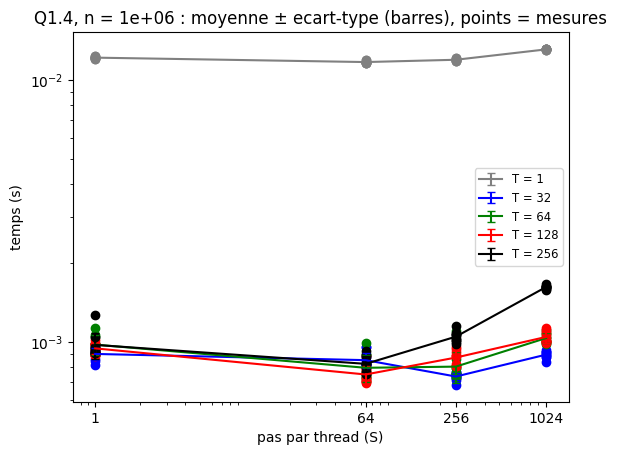

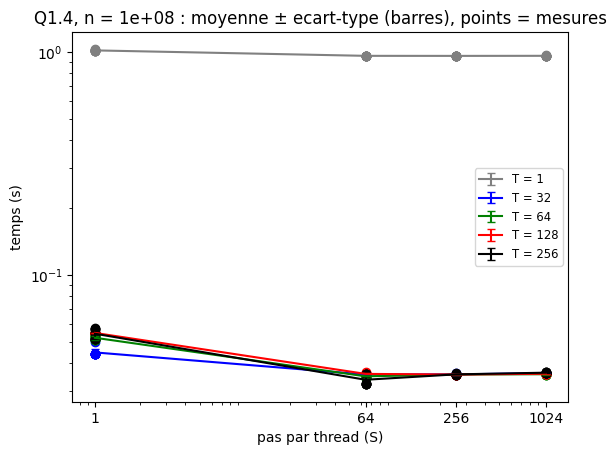

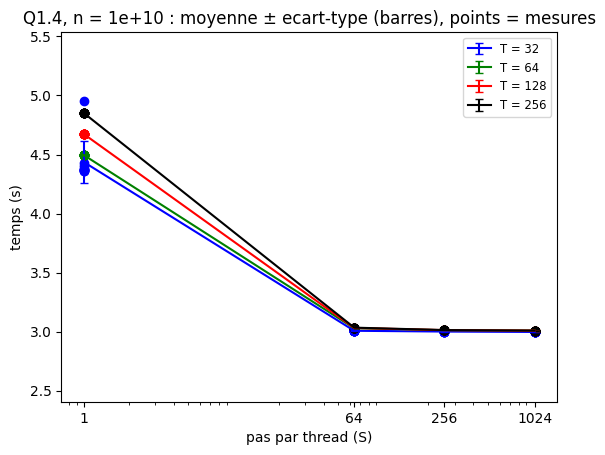

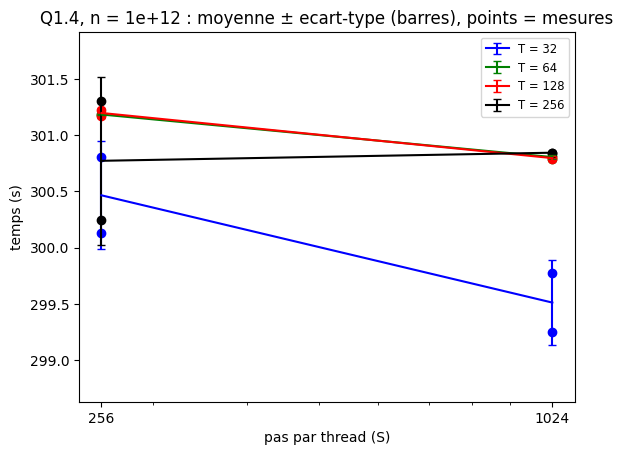

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

df = pd.read_excel('donnees/mesures_cuda.xlsx', sheet_name='partie1_pi')
df_final = df[df['version'] == '1_4_pi_cuda']

from matplotlib.ticker import ScalarFormatter, NullFormatter

def mise_en_forme(df_size, colonne):
    # echelle log, sauf si les temps varient peu (ex. 10^12 pas) : echelle lineaire, graduations lisibles
    ymin, ymax = df_size['runtime'].min(), df_size['runtime'].max()
    if ymax / ymin < 2:
        plt.yscale('linear')
        plt.gca().yaxis.set_major_formatter(ScalarFormatter(useOffset=False))
        marge = (ymax - ymin) * 0.3 or ymax * 0.01
        plt.ylim(ymin - marge, ymax + marge)
    else:
        plt.yscale('log')
    plt.xscale('log')
    valeurs = sorted(df_size[colonne].unique())
    plt.xticks(valeurs, [str(v) for v in valeurs])
    plt.gca().xaxis.set_minor_formatter(NullFormatter())
    if len(valeurs) == 1:
        plt.xlim(valeurs[0] / 1.5, valeurs[0] * 1.5)

color_T = {1: "gray", 32: "blue", 64: "green", 128: "red", 256: "black"}

for num_steps in sorted(df_final['num_steps'].unique()):
    df_size = df_final[df_final['num_steps'] == int(num_steps)]

    for T, color in color_T.items():
        df_plot = df_size[df_size['T'] == T]
        if df_plot.empty:
            continue

        mean_stats = df_plot.groupby(['T', 'S']).mean(numeric_only=True).reset_index()
        std_stats = df_plot.groupby(['T', 'S']).std(numeric_only=True).reset_index()

        plt.errorbar(mean_stats['S'], mean_stats['runtime'], yerr=std_stats['runtime'], capsize=3,
                     color=color, label=f"T = {T}")
        plt.scatter(df_plot['S'], df_plot['runtime'], color=color)

    mise_en_forme(df_size, 'S')
    plt.xlabel('pas par thread (S)')
    plt.ylabel('temps (s)')
    plt.title(f'Q1.4, n = {num_steps:.0e} : moyenne ± ecart-type (barres), points = mesures')
    plt.legend(fontsize='small')
    plt.show()

#### Temps en fonction du nombre de threads par bloc (Q1.4)

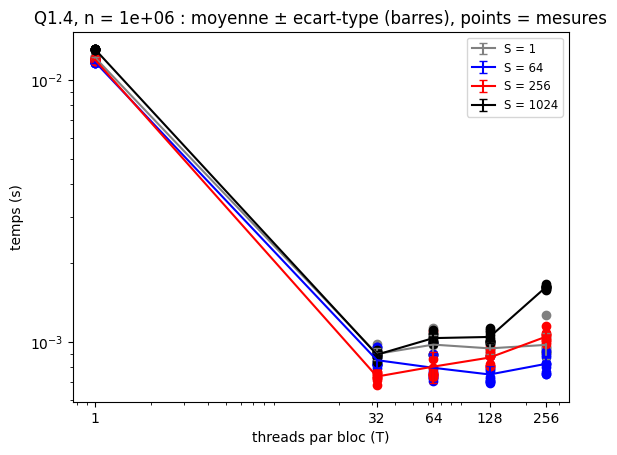

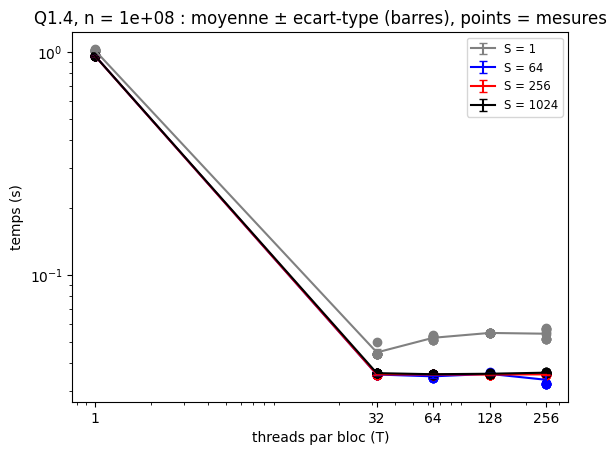

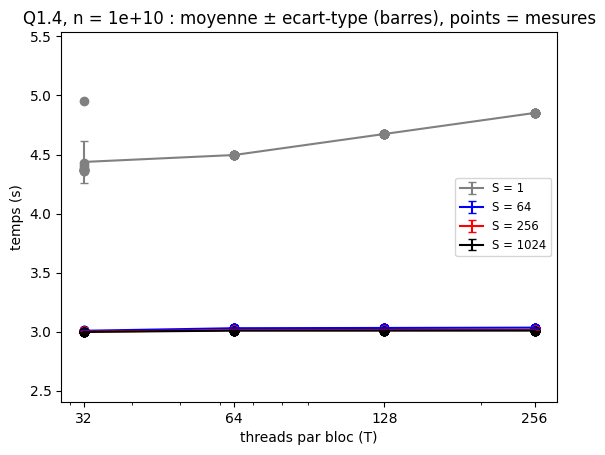

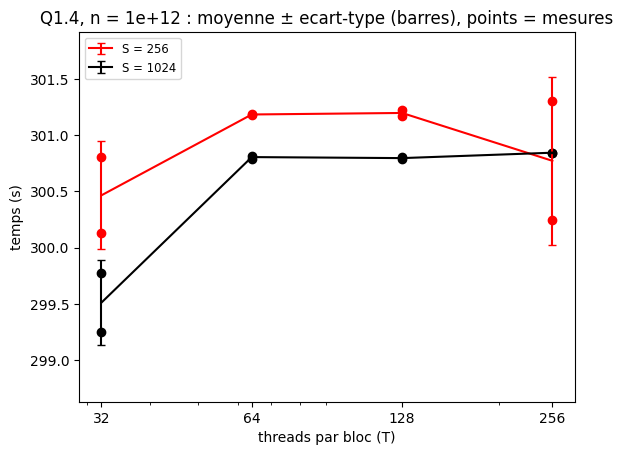

In [3]:
color_S = {1: "gray", 64: "blue", 256: "red", 1024: "black"}

for num_steps in sorted(df_final['num_steps'].unique()):
    df_size = df_final[df_final['num_steps'] == int(num_steps)]

    for S, color in color_S.items():
        df_plot = df_size[df_size['S'] == S]
        if df_plot.empty:
            continue

        mean_stats = df_plot.groupby(['T', 'S']).mean(numeric_only=True).reset_index()
        std_stats = df_plot.groupby(['T', 'S']).std(numeric_only=True).reset_index()

        plt.errorbar(mean_stats['T'], mean_stats['runtime'], yerr=std_stats['runtime'], capsize=3,
                     color=color, label=f"S = {S}")
        plt.scatter(df_plot['T'], df_plot['runtime'], color=color)

    mise_en_forme(df_size, 'T')
    plt.xlabel('threads par bloc (T)')
    plt.ylabel('temps (s)')
    plt.title(f'Q1.4, n = {num_steps:.0e} : moyenne ± ecart-type (barres), points = mesures')
    plt.legend(fontsize='small')
    plt.show()

#### Comparaison des quatre versions

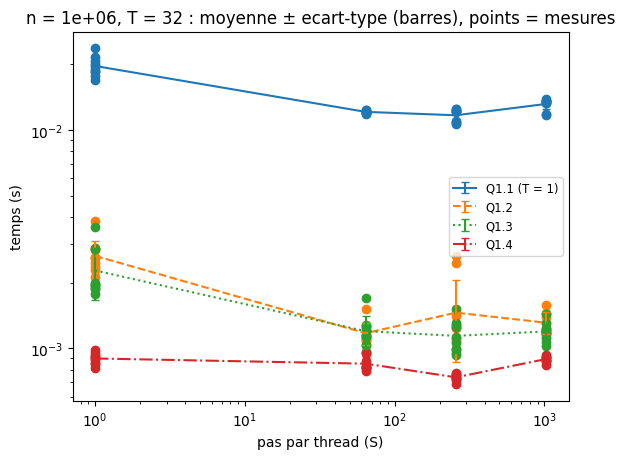

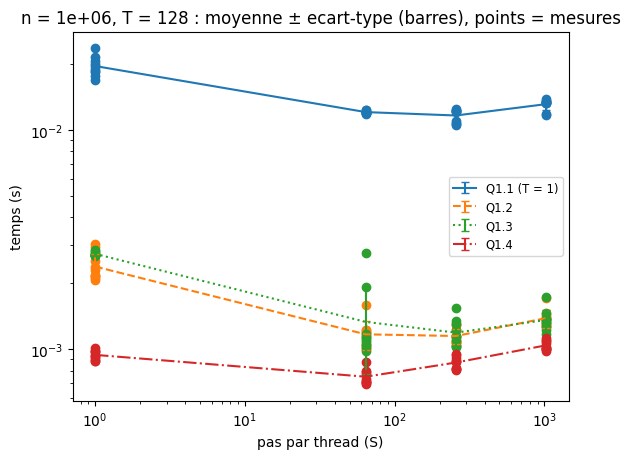

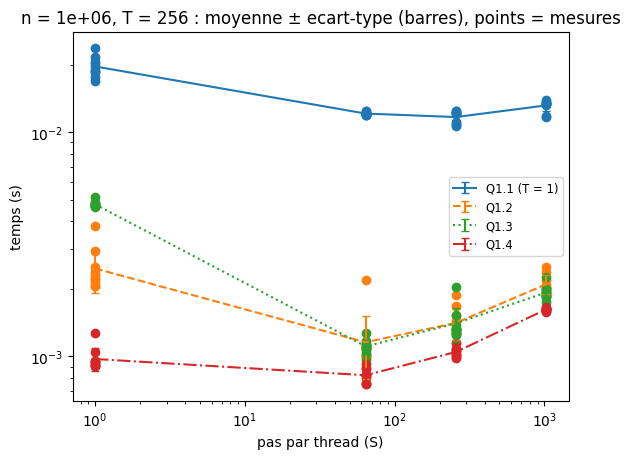

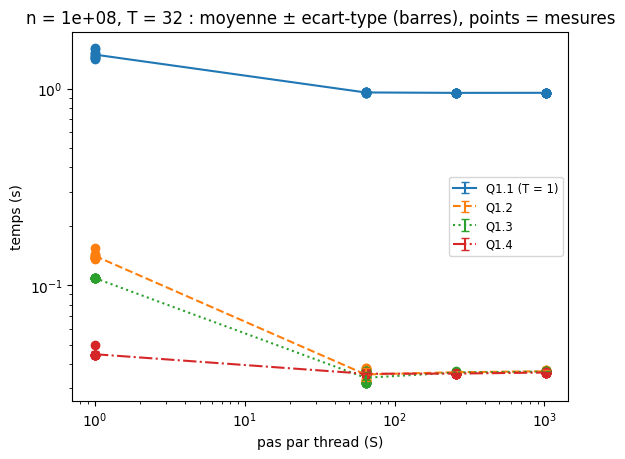

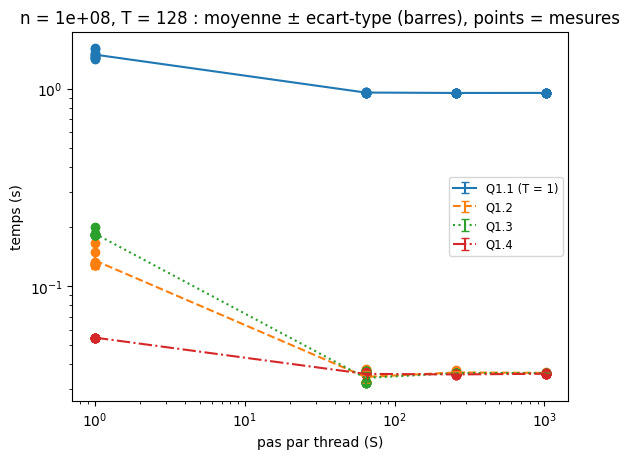

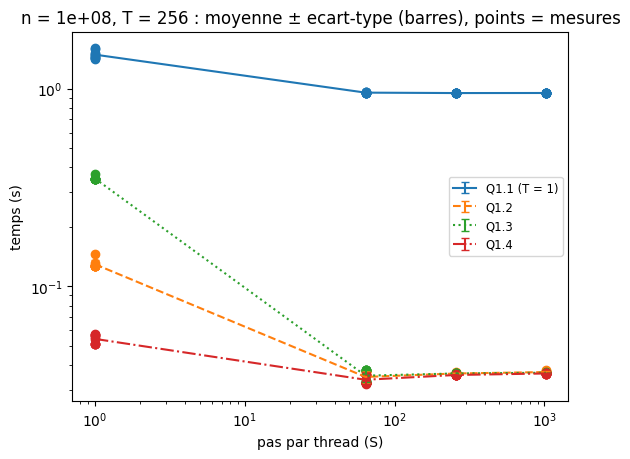

In [4]:
version_style = {"1_1_pi_cuda": ("solid", "Q1.1 (T = 1)"), "1_2_pi_cuda": ("dashed", "Q1.2"),
                 "1_3_pi_cuda": ("dotted", "Q1.3"), "1_4_pi_cuda": ("dashdot", "Q1.4")}

for num_steps in (1000000, 100000000):
    for T in (32, 128, 256):
        for version, (linestyle, nom) in version_style.items():
            t_eff = 1 if version == "1_1_pi_cuda" else T
            df_plot = df[(df['version'] == version) & (df['num_steps'] == num_steps) & (df['T'] == t_eff)]
            if df_plot.empty:
                continue

            mean_stats = df_plot.groupby(['S']).mean(numeric_only=True).reset_index()
            std_stats = df_plot.groupby(['S']).std(numeric_only=True).reset_index()

            plt.errorbar(mean_stats['S'], mean_stats['runtime'], yerr=std_stats['runtime'], capsize=3,
                         linestyle=linestyle, label=nom)
            plt.scatter(df_plot['S'], df_plot['runtime'])

        plt.yscale('log')
        plt.xscale('log')
        plt.xlabel('pas par thread (S)')
        plt.ylabel('temps (s)')
        plt.title(f'n = {num_steps:.0e}, T = {T} : moyenne ± ecart-type (barres), points = mesures')
        plt.legend(fontsize='small')
        plt.show()

#### Tableau des meilleures configurations (Q1.4)

In [5]:
from IPython.display import Markdown, display

def _fmt(x):
    return f"{x:.0f}" if x >= 100 else f"{x:.1f}" if x >= 10 else f"{x:.2f}" if x >= 1 else f"{x:.4f}"

g = df_final.groupby(['num_steps', 'T', 'S']).agg(t=('runtime', 'mean'), ts=('runtime', 'std'),
                                                   nb=('nblocks', 'first'), n=('runtime', 'count')).reset_index()
out = "| pas | meilleure config (T, S) | blocs | temps moyen ± écart-type (s) | exécutions | débit (milliards de pas/s) |\n|---|---|---|---|---|---|\n"
for num_steps, d in g.groupby('num_steps'):
    r = d.loc[d['t'].idxmin()]
    out += (f"| {num_steps:.0e} | T = {int(r['T'])}, S = {int(r['S'])} | {int(r['nb'])} | "
            f"{_fmt(r['t'])} ± {_fmt(0 if pd.isna(r['ts']) else r['ts'])} | {int(r['n'])} | {num_steps / r['t'] / 1e9:.1f} |\n")
display(Markdown(out))

| pas | meilleure config (T, S) | blocs | temps moyen ± écart-type (s) | exécutions | débit (milliards de pas/s) |
|---|---|---|---|---|---|
| 1e+06 | T = 32, S = 256 | 123 | 0.0007 ± 0.0000 | 10 | 1.4 |
| 1e+08 | T = 256, S = 64 | 6104 | 0.0337 ± 0.0018 | 10 | 3.0 |
| 1e+10 | T = 32, S = 1024 | 305176 | 3.00 ± 0.0014 | 10 | 3.3 |
| 1e+12 | T = 32, S = 1024 | 30517579 | 300 ± 0.3748 | 2 | 3.3 |


### Question 1.7 - Discussion

Les temps cités sont des moyennes sur 10 exécutions (seulement 2 exécutions à 10^12 pas car beaucoup trop long).

**Meilleure configuration de la Q1.4 pour chaque nombre de pas (temps en secondes)**

| nombre de pas | T | S | blocs | temps moyen ± écart-type (s) | exécutions | débit (milliards de pas/s) |
|---|---|---|---|---|---|---|
| 10^6 | 32 | 256 | 123 | 0.00074 ± 0.00003 | 10 | 1.4 |
| 10^8 | 256 | 64 | 6104 | 0.0337 ± 0.0018 | 10 | 3.0 |
| 10^10 | 32 | 1024 | 305176 | 2.9974 ± 0.0014 | 10 | 3.3 |
| 10^12 | 32 | 1024 | 30517579 | 299.51 ± 0.37 | 2 | 3.3 |

**10^6 pas, temps en millisecondes, 10 exécutions par configuration**

| version | T | S = 1 | S = 64 | S = 256 | S = 1024 |
|---|---|---|---|---|---|
| Q1.1 | 1 | 19.6 ± 2.0 | 12.09 ± 0.17 | 11.67 ± 0.77 | 13.15 ± 0.74 |
| Q1.2 | 1 | 20.8 ± 2.0 | 12.35 ± 0.31 | 12.26 ± 0.16 | 13.54 ± 0.41 |
| Q1.2 | 32 | 2.65 ± 0.47 | 1.17 ± 0.13 | 1.46 ± 0.59 | 1.31 ± 0.15 |
| Q1.2 | 64 | 2.27 ± 0.24 | 1.25 ± 0.33 | 1.089 ± 0.097 | 1.46 ± 0.23 |
| Q1.2 | 128 | 2.39 ± 0.34 | 1.17 ± 0.17 | 1.151 ± 0.093 | 1.39 ± 0.13 |
| Q1.2 | 256 | 2.47 ± 0.54 | 1.16 ± 0.36 | 1.41 ± 0.22 | 2.09 ± 0.20 |
| Q1.3 | 1 | 12.85 ± 0.24 | 11.97 ± 0.27 | 12.21 ± 0.17 | 13.46 ± 0.23 |
| Q1.3 | 32 | 2.27 ± 0.62 | 1.20 ± 0.21 | 1.14 ± 0.19 | 1.20 ± 0.12 |
| Q1.3 | 64 | 2.07 ± 0.27 | 1.06 ± 0.12 | 1.13 ± 0.20 | 1.30 ± 0.15 |
| Q1.3 | 128 | 2.727 ± 0.064 | 1.33 ± 0.57 | 1.19 ± 0.17 | 1.36 ± 0.15 |
| Q1.3 | 256 | 4.76 ± 0.14 | 1.108 ± 0.081 | 1.40 ± 0.24 | 1.93 ± 0.13 |
| Q1.4 | 1 | 12.16 ± 0.12 | 11.697 ± 0.098 | 11.94 ± 0.11 | 13.075 ± 0.040 |
| Q1.4 | 32 | 0.899 ± 0.050 | 0.851 ± 0.058 | 0.737 ± 0.025 | 0.893 ± 0.028 |
| Q1.4 | 64 | 0.976 ± 0.083 | 0.796 ± 0.096 | 0.804 ± 0.109 | 1.033 ± 0.043 |
| Q1.4 | 128 | 0.944 ± 0.045 | 0.750 ± 0.058 | 0.871 ± 0.055 | 1.044 ± 0.051 |
| Q1.4 | 256 | 0.973 ± 0.112 | 0.824 ± 0.059 | 1.046 ± 0.051 | 1.619 ± 0.025 |

**10^8 pas, temps en secondes, 10 exécutions par configuration**

| version | T | S = 1 | S = 64 | S = 256 | S = 1024 |
|---|---|---|---|---|---|
| Q1.1 | 1 | 1.488 ± 0.066 | 0.9559 ± 0.0021 | 0.9513 ± 0.0014 | 0.9520 ± 0.0014 |
| Q1.2 | 1 | 1.498 ± 0.058 | 0.9667 ± 0.0014 | 0.9606 ± 0.0011 | 0.9591 ± 0.0011 |
| Q1.2 | 32 | 0.1412 ± 0.0055 | 0.0353 ± 0.0026 | 0.03624 ± 0.00012 | 0.03665 ± 0.00034 |
| Q1.2 | 64 | 0.1364 ± 0.0070 | 0.0346 ± 0.0025 | 0.03642 ± 0.00042 | 0.03598 ± 0.00010 |
| Q1.2 | 128 | 0.135 ± 0.012 | 0.0346 ± 0.0025 | 0.03643 ± 0.00050 | 0.03625 ± 0.00012 |
| Q1.2 | 256 | 0.1295 ± 0.0060 | 0.0349 ± 0.0025 | 0.03627 ± 0.00023 | 0.03689 ± 0.00042 |
| Q1.3 | 1 | 1.0380 ± 0.0071 | 0.9566 ± 0.0011 | 0.9564 ± 0.0013 | 0.9567 ± 0.0016 |
| Q1.3 | 32 | 0.10894 ± 0.00005 | 0.0340 ± 0.0025 | 0.03613 ± 0.00023 | 0.03650 ± 0.00013 |
| Q1.3 | 64 | 0.1202 ± 0.0059 | 0.0341 ± 0.0025 | 0.03615 ± 0.00010 | 0.03611 ± 0.00029 |
| Q1.3 | 128 | 0.1840 ± 0.0055 | 0.0342 ± 0.0025 | 0.03614 ± 0.00007 | 0.03622 ± 0.00007 |
| Q1.3 | 256 | 0.3513 ± 0.0061 | 0.0354 ± 0.0026 | 0.03629 ± 0.00009 | 0.03660 ± 0.00006 |
| Q1.4 | 1 | 1.0142 ± 0.0058 | 0.95875 ± 0.00085 | 0.9582 ± 0.0015 | 0.9590 ± 0.0015 |
| Q1.4 | 32 | 0.0447 ± 0.0018 | 0.03560 ± 0.00022 | 0.03566 ± 0.00017 | 0.03612 ± 0.00006 |
| Q1.4 | 64 | 0.0521 ± 0.0011 | 0.03495 ± 0.00062 | 0.03561 ± 0.00010 | 0.03572 ± 0.00013 |
| Q1.4 | 128 | 0.05472 ± 0.00003 | 0.03584 ± 0.00028 | 0.03560 ± 0.00004 | 0.03590 ± 0.00009 |
| Q1.4 | 256 | 0.0543 ± 0.0027 | 0.0337 ± 0.0018 | 0.03566 ± 0.00014 | 0.03629 ± 0.00009 |

**Q1.4 à 10^10 pas, temps en secondes, 10 exécutions par configuration**

| T | S = 1 | S = 64 | S = 256 | S = 1024 |
|---|---|---|---|---|
| 32 | 4.44 ± 0.18 | 3.0074 ± 0.0027 | 3.0007 ± 0.0029 | 2.9974 ± 0.0014 |
| 64 | 4.4958 ± 0.0011 | 3.02900 ± 0.00019 | 3.01225 ± 0.00006 | 3.00875 ± 0.00009 |
| 128 | 4.67396 ± 0.00069 | 3.03132 ± 0.00009 | 3.01288 ± 0.00004 | 3.00887 ± 0.00006 |
| 256 | 4.85216 ± 0.00052 | 3.03389 ± 0.00010 | 3.01343 ± 0.00006 | 3.00903 ± 0.00007 |

**Q1.4 à 10^12 pas, temps en secondes (nombre d'exécutions entre parenthèses)**

| T | S = 256 | S = 1024 |
|---|---|---|
| 32 | 300.46 ± 0.48 (2) | 299.51 ± 0.37 (2) |
| 64 | 301.1830 ± 0.0014 (2) | 300.804 ± 0.019 (2) |
| 128 | 301.197 ± 0.042 (2) | 300.796 ± 0.015 (2) |
| 256 | 300.77 ± 0.75 (2) | 300.8435 ± 0.0021 (2) |

Un thread par bloc est très inefficace. À 10^8 pas, la Q1.1 met 0.95 s (S = 256) alors que la Q1.4 avec 128 threads par bloc met 0.036 s, soit 27 fois moins. Le même écart apparaît dans les versions Q1.2, Q1.3 et Q1.4 dès qu'on les lance avec T = 1 (0.96 s à 10^8 pas), donc la cause n'est pas la méthode de réduction mais le nombre de threads par bloc. Après en avoir discuté avec une LLM, j'ai cru comprendre qu'un GPU exécute les threads par groupes de 32 (les warps) : donc si on se limite à un unique thread par bloc, cela occupe un warp dont 31 voies restent inactives, ce qui limite l'utilisation à environ 1/32. Le facteur observé (27) est assez cohérent avec cette limite.

Au-delà d'un warp, le nombre de threads par bloc ne change plus rien. Pour S >= 64, tous les T entre 32 et 256 donnent le même temps : entre 0.034 et 0.036 s à 10^8 pas, et entre 3.00 et 3.03 s à 10^10 pas (Q1.4). Le GPU semble saturé et le temps est celui du calcul. Une nuance : aux grandes tailles, T = 32 est un peu plus rapide que les autres, de 0.011 à 0.027 s sur 3 s à 10^10 pas (0.4 à 0.9 %) et de 1.3 s sur 300 s à 10^12 pas avec S = 1024 (0.4 %), un écart faible mais supérieur aux écarts-types de ces configurations, et je ne l'explique pas.

On remarque aussi que le nombre de pas par thread compte surtout aux extrêmes. Avec S = 1, chaque thread ne calcule qu'un pas : à 10^10 pas, il y a de 3.9 x 10^7 blocs (T = 256) à 3.1 x 10^8 blocs (T = 32), et chacun produit un total qu'il faut ensuite réduire. Le temps passe alors à 4.44-4.85 s au lieu de 3.0 s, soit 48 à 62 % de plus, et il augmente avec T (4.44 s à T = 32, 4.85 s à T = 256). Mon hypothèse est que le calcul par pas est si court que le coût de la réduction (écriture et relecture des totaux, avec arbre de log2(T) étapes) devient comparable au calcul (si le temps l'avait permis, cela aurait pu être mesuré séparément pour confirmer ou infirmer l'hypothèse). À T = 32 et S = 1, les deux tableaux de totaux font 2 x 2.5 Go, plus que les 4 Go de la carte. L'exécution réussit quand même et donne pi correct, possiblement grâce à un repli du pilote sur la mémoire du système, et j'ai été très surpris de ne pas voir de ralentissement lié à cela, puisque T = 32 est plus rapide que T = 64. À l'inverse, trop peu de threads pénalise les petites tailles : à 10^6 pas avec S = 1024 et T = 256, il n'y a qu'environ 1000 threads (4 blocs) pour 14 multiprocesseurs, et la Q1.4 met 1.6 ms contre 0.7 à 0.9 ms pour les autres combinaisons.

Pour S >= 64, les versions Q1.2, Q1.3 et Q1.4 sont indiscernables (0.034 à 0.037 s à 10^8 pas) : la réduction ne pèse presque rien devant le calcul. Les différences apparaissent quand il y a beaucoup de réduction à faire, par exemple avec S = 1 à 10^8 pas. La Q1.4 est alors la plus rapide et la plus stable (0.045 à 0.055 s selon T), car l'arbre en mémoire partagée ne demande que log2(T) étapes parallèles. La Q1.2 est 2.5 à 3 fois plus lente (0.13 à 0.14 s), car un seul thread par bloc additionne les T valeurs, l'une après l'autre, en mémoire globale. La Q1.3 se dégrade quand T augmente : 0.109 s à T = 32, 0.184 s à T = 128 et 0.351 s à T = 256. Je suppose que cela est dû au fait que les T threads d'un bloc font leur `atomicAdd` sur la même variable partagée, donc l'un après l'autre (cette sérialisation qui s'aggrave avec le nombre de threads avait aussi été vue avec `atomic` dans le TP OpenMP). À 10^6 pas, la Q1.4 reste la meilleure (environ 0.8 ms à T >= 32 contre 1.1 à 1.3 ms pour Q1.2 et Q1.3).

Le meilleur débit passe de 1.4 milliard de pas par seconde à 10^6 pas, à 3.0 à 10^8, puis 3.3 à 10^10 et à 10^12. À 10^6 pas, le temps (0.7 ms) semble dominé par les coûts fixes (lancement de plusieurs kernels, copie du résultat vers le CPU) qui ne sont pas amortis. À partir de 10^10 pas, le débit est constant et le temps est proportionnel au nombre de pas : 301 s à 10^12 contre 3.0 s à 10^10, soit 100 fois plus pour 100 fois plus de pas. Les écarts-types sont très faibles (de 0.001 s à 0.75 s sur environ 300 s à 10^12 pas, soit au plus 0.25 %) donc les mesures semblent stables.

Le code séquentiel de départ (compilé avec `-O2`) met en moyenne 0.158 s (écart-type 0.002 s) à 10^8 pas sur 10 exécutions, contre 0.034 s pour le meilleur kernel, soit environ 5 fois moins. À 10^10 pas en revanche, le TP OpenMP obtenait environ 3.1 s avec 8 threads, contre 3.0 s sur le GPU, donc surprenamment mon GPU n'est pas plus rapide que mon processeur parallélisé (peut-être que la GTX est limitée à cause du calcul en double précision ? Il aurait fallu faire d'autres mesures pour faire une hypothèse sérieuse, mais par manque de temps on ne développera pas davantage ce point).

Conclusion : sur ce GPU, le facteur déterminant est d'avoir assez de threads actifs par bloc (au moins un warp de 32, et cela peut permettre de gagner un facteur 27). Une fois cette condition remplie, le nombre de threads par bloc et le nombre de pas par thread ne changent presque plus le temps, sauf à S = 1 où la réduction devient coûteuse. Dans ce cas, la réduction en arbre (Q1.4) est la plus efficace et la plus stable, alors que les atomiques (Q1.3) et la somme par un seul thread (Q1.2) se dégradent.

## 2. Matrix-Vector operation

### Question 2.1 - Code séquentiel

Code complété (le même qu'au TP OpenMP, avec l'écriture des mesures dans le fichier CSV commun) :

In [1]:
from pathlib import Path

Path("src/2_1_vector.cpp").write_text(r"""/*
//@HEADER
// ************************************************************************
//
//                        Kokkos v. 2.0
//              Copyright (2014) Sandia Corporation
//
// Under the terms of Contract DE-AC04-94AL85000 with Sandia Corporation,
// the U.S. Government retains certain rights in this software.
//
// Redistribution and use in source and binary forms, with or without
// modification, are permitted provided that the following conditions are
// met:
//
// 1. Redistributions of source code must retain the above copyright
// notice, this list of conditions and the following disclaimer.
//
// 2. Redistributions in binary form must reproduce the above copyright
// notice, this list of conditions and the following disclaimer in the
// documentation and/or other materials provided with the distribution.
//
// 3. Neither the name of the Corporation nor the names of the
// contributors may be used to endorse or promote products derived from
// this software without specific prior written permission.
//
// THIS SOFTWARE IS PROVIDED BY SANDIA CORPORATION "AS IS" AND ANY
// EXPRESS OR IMPLIED WARRANTIES, INCLUDING, BUT NOT LIMITED TO, THE
// IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR
// PURPOSE ARE DISCLAIMED. IN NO EVENT SHALL SANDIA CORPORATION OR THE
// CONTRIBUTORS BE LIABLE FOR ANY DIRECT, INDIRECT, INCIDENTAL, SPECIAL,
// EXEMPLARY, OR CONSEQUENTIAL DAMAGES (INCLUDING, BUT NOT LIMITED TO,
// PROCUREMENT OF SUBSTITUTE GOODS OR SERVICES; LOSS OF USE, DATA, OR
// PROFITS; OR BUSINESS INTERRUPTION) HOWEVER CAUSED AND ON ANY THEORY OF
// LIABILITY, WHETHER IN CONTRACT, STRICT LIABILITY, OR TORT (INCLUDING
// NEGLIGENCE OR OTHERWISE) ARISING IN ANY WAY OUT OF THE USE OF THIS
// SOFTWARE, EVEN IF ADVISED OF THE POSSIBILITY OF SUCH DAMAGE.
//
// Questions Contact  H. Carter Edwards (hcedwar@sandia.gov)
//
// ************************************************************************
//@HEADER
*/

#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <sys/time.h>

#include <cmath>
#include <fstream>

void checkSizes( int &N, int &M, int &S, int &nrepeat );

int main( int argc, char* argv[] )
{
  int N = -1;         // number of rows 2^12
  int M = -1;         // number of columns 2^10
  int S = -1;         // total size 2^22
  int nrepeat = 100;  // number of repeats of the test

  // Read command line arguments.
  for ( int i = 0; i < argc; i++ ) {
    if ( ( strcmp( argv[ i ], "-N" ) == 0 ) || ( strcmp( argv[ i ], "-Rows" ) == 0 ) ) {
      N = pow( 2, atoi( argv[ ++i ] ) );
      printf( "  User N is %d\n", N );
    }
    else if ( ( strcmp( argv[ i ], "-M" ) == 0 ) || ( strcmp( argv[ i ], "-Columns" ) == 0 ) ) {
      M = pow( 2, atof( argv[ ++i ] ) );
      printf( "  User M is %d\n", M );
    }
    else if ( ( strcmp( argv[ i ], "-S" ) == 0 ) || ( strcmp( argv[ i ], "-Size" ) == 0 ) ) {
      S = pow( 2, atof( argv[ ++i ] ) );
      printf( "  User S is %d\n", S );
    }
    else if ( strcmp( argv[ i ], "-nrepeat" ) == 0 ) {
      nrepeat = atoi( argv[ ++i ] );
    }
    else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
      printf( "  y^T*A*x Options:\n" );
      printf( "  -Rows (-N) <int>:      exponent num, determines number of rows 2^num (default: 2^12 = 4096)\n" );
      printf( "  -Columns (-M) <int>:   exponent num, determines number of columns 2^num (default: 2^10 = 1024)\n" );
      printf( "  -Size (-S) <int>:      exponent num, determines total matrix size 2^num (default: 2^22 = 4096*1024 )\n" );
      printf( "  -nrepeat <int>:        number of repetitions (default: 100)\n" );
      printf( "  -help (-h):            print this message\n\n" );
      exit( 1 );
    }
  }

  // Check sizes.
  checkSizes( N, M, S, nrepeat );

  // Allocate x,y,A
  auto y = (double*) std::malloc(N*sizeof(double));
  auto x = (double*) std::malloc(M*sizeof(double));
  auto A = (double*) std::malloc(N*M*sizeof(double));

  // Initialize y vector to 1.
  for (int i = 0; i < N; i++) {
    y[i] = 1.0;
  }

  // Initialize x vector to 1.
  for (int i = 0; i < M; i++) {
    x[i] = 1.0;
  }

  // Initialize A matrix, you can use a 1D index if you want a flat structure (i.e. a 1D array) e.g. j*M+i is the same than [j][i]
  for (int j = 0; j < N; j++) {
    for (int i = 0; i < M; i++) {
      A[j*M+i] = 1.0;
    }
  }

  // Timer products.
  struct timeval begin, end;

  gettimeofday( &begin, NULL );

  for ( int repeat = 0; repeat < nrepeat; repeat++ ) {
    // For each line i
        // Multiply the i lines with the vector x 
        // Sum the results of the previous step into a single variable
        double result = 0.0;
        for (int i = 0; i < N; i++) {
            double sum = 0.0;
            for (int j = 0; j < M; j++) {
                sum += A[i*M+j] * x[j];
            }
            // Multiply the result of the previous step with the i value of vector y
            // Sum the results of the previous step into a single variable (result)
            result += sum * y[i];
        }


    // Output result.
    if ( repeat == ( nrepeat - 1 ) ) {
      printf( "  Computed result for %d x %d is %lf\n", N, M, result );
    }

    const double solution = (double) N * (double) M;

    if ( result != solution ) {
      printf( "  Error: result( %lf ) != solution( %lf )\n", result, solution );
    }
  }

  gettimeofday( &end, NULL );

  // Calculate time.
  //double time = timer.seconds();
  double time = 1.0 * ( end.tv_sec - begin.tv_sec ) +
                1.0e-6 * ( end.tv_usec - begin.tv_usec );

  // Calculate bandwidth.
  // Each matrix A row (each of length M) is read once.
  // The x vector (of length M) is read N times.
  // The y vector (of length N) is read once.
  // double Gbytes = 1.0e-9 * double( sizeof(double) * ( 2 * M * N + N ) );
  double Gbytes = 1.0e-9 * double( sizeof(double) * ( M + M * N + N ) );

  // Print results (problem size, time and bandwidth in GB/s).
  printf( "  N( %d ) M( %d ) nrepeat ( %d ) problem( %g MB ) time( %g s ) bandwidth( %g GB/s )\n",
          N, M, nrepeat, Gbytes * 1000, time, Gbytes * nrepeat / time );
  std::ofstream("stats_cuda_vecteur.csv", std::ios::app) << "2_1_vector_seq,1," << N << "," << M << "," << Gbytes * 1000 << "," << time << "," << Gbytes * nrepeat / time << "\n";

  std::free(A);
  std::free(y);
  std::free(x);

  return 0;
}

void checkSizes( int &N, int &M, int &S, int &nrepeat ) {
  // If S is undefined and N or M is undefined, set S to 2^22 or the bigger of N and M.
  if ( S == -1 && ( N == -1 || M == -1 ) ) {
    S = pow( 2, 22 );
    if ( S < N ) S = N;
    if ( S < M ) S = M;
  }

  // If S is undefined and both N and M are defined, set S = N * M.
  if ( S == -1 ) S = N * M;

  // If both N and M are undefined, fix row length to the smaller of S and 2^10 = 1024.
  if ( N == -1 && M == -1 ) {
    if ( S > 1024 ) {
      M = 1024;
    }
    else {
      M = S;
    }
  }

  // If only M is undefined, set it.
  if ( M == -1 ) M = S / N;

  // If N is undefined, set it.
  if ( N == -1 ) N = S / M;

  printf( "  Total size S = %d N = %d M = %d\n", S, N, M );

  // Check sizes.
  if ( ( S < 0 ) || ( N < 0 ) || ( M < 0 ) || ( nrepeat < 0 ) ) {
    printf( "  Sizes must be greater than 0.\n" );
    exit( 1 );
  }

  if ( ( N * M ) != S ) {
    printf( "  N * M != S\n" );
    exit( 1 );
  }
}
""", encoding="utf8")

7387

In [11]:
!g++ -o bin/2_1_vector src/2_1_vector.cpp -O3 -march=native

In [12]:
!.\bin\2_1_vector.exe -N 12 -M 10

  User N is 4096
  User M is 1024
  Total size S = 4194304 N = 4096 M = 1024
  Computed result for 4096 x 1024 is 4194304.000000
  N( 4096 ) M( 1024 ) nrepeat ( 100 ) problem( 33.5954 MB ) time( 0.814032 s ) bandwidth( 4.12704 GB/s )


### Question 2.2 - Port CUDA (un thread par bloc)

Le kernel est lancé avec `N` blocs d'un seul thread, un bloc par ligne de `A`. Le bloc `i` calcule la somme des produits de la ligne `i` avec `x`, la multiplie par `y[i]` et écrit le résultat dans un tableau de `N` valeurs. Ce tableau est copié vers le CPU à chaque répétition et la somme finale est faite sur le CPU. Les copies de `A`, `x` et `y` vers le GPU sont faites une seule fois avant le chronomètre, comme l'initialisation dans la version OpenMP. Le temps mesuré comprend donc les `nrepeat` = 100 répétitions du kernel et de la copie du résultat, mais pas les copies initiales (pas pertinent car constant).

In [4]:
from pathlib import Path

Path("src/2_2_vector_cuda.cu").write_text(r"""/*
//@HEADER
// ************************************************************************
//
//                        Kokkos v. 2.0
//              Copyright (2014) Sandia Corporation
//
// Under the terms of Contract DE-AC04-94AL85000 with Sandia Corporation,
// the U.S. Government retains certain rights in this software.
//
// Redistribution and use in source and binary forms, with or without
// modification, are permitted provided that the following conditions are
// met:
//
// 1. Redistributions of source code must retain the above copyright
// notice, this list of conditions and the following disclaimer.
//
// 2. Redistributions in binary form must reproduce the above copyright
// notice, this list of conditions and the following disclaimer in the
// documentation and/or other materials provided with the distribution.
//
// 3. Neither the name of the Corporation nor the names of the
// contributors may be used to endorse or promote products derived from
// this software without specific prior written permission.
//
// THIS SOFTWARE IS PROVIDED BY SANDIA CORPORATION "AS IS" AND ANY
// EXPRESS OR IMPLIED WARRANTIES, INCLUDING, BUT NOT LIMITED TO, THE
// IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR
// PURPOSE ARE DISCLAIMED. IN NO EVENT SHALL SANDIA CORPORATION OR THE
// CONTRIBUTORS BE LIABLE FOR ANY DIRECT, INDIRECT, INCIDENTAL, SPECIAL,
// EXEMPLARY, OR CONSEQUENTIAL DAMAGES (INCLUDING, BUT NOT LIMITED TO,
// PROCUREMENT OF SUBSTITUTE GOODS OR SERVICES; LOSS OF USE, DATA, OR
// PROFITS; OR BUSINESS INTERRUPTION) HOWEVER CAUSED AND ON ANY THEORY OF
// LIABILITY, WHETHER IN CONTRACT, STRICT LIABILITY, OR TORT (INCLUDING
// NEGLIGENCE OR OTHERWISE) ARISING IN ANY WAY OUT OF THE USE OF THIS
// SOFTWARE, EVEN IF ADVISED OF THE POSSIBILITY OF SUCH DAMAGE.
//
// Questions Contact  H. Carter Edwards (hcedwar@sandia.gov)
//
// ************************************************************************
//@HEADER
*/

#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <chrono>

#include <cmath>
#include <fstream>

void checkSizes( int &N, int &M, int &S, int &nrepeat );

// l'énoncé dit : 1 thread par bloc, 1 bloc par ligne de A 
// Donc le bloc i calcule y[i] * (ligne i de A . x)
__global__ void matvec_kernel(const double *A, const double *x, const double *y, double *partial, int M)
{
    int i = blockIdx.x;                          // num ligne = num bloc
    double sum = 0.0;
    for (int j = 0; j < M; j++)
        sum += A[(long long)i * M + j] * x[j];  // long long pour éviter dépassement (meme si pas forcément pertinent au vue de nos tests)
    partial[i] = sum * y[i];
}


int main( int argc, char* argv[] )
{
  int N = -1;         // number of rows 2^12
  int M = -1;         // number of columns 2^10
  int S = -1;         // total size 2^22
  int nrepeat = 100;  // number of repeats of the test

  // Read command line arguments.
  for ( int i = 0; i < argc; i++ ) {
    if ( ( strcmp( argv[ i ], "-N" ) == 0 ) || ( strcmp( argv[ i ], "-Rows" ) == 0 ) ) {
      N = pow( 2, atoi( argv[ ++i ] ) );
      printf( "  User N is %d\n", N );
    }
    else if ( ( strcmp( argv[ i ], "-M" ) == 0 ) || ( strcmp( argv[ i ], "-Columns" ) == 0 ) ) {
      M = pow( 2, atof( argv[ ++i ] ) );
      printf( "  User M is %d\n", M );
    }
    else if ( ( strcmp( argv[ i ], "-S" ) == 0 ) || ( strcmp( argv[ i ], "-Size" ) == 0 ) ) {
      S = pow( 2, atof( argv[ ++i ] ) );
      printf( "  User S is %d\n", S );
    }
    else if ( strcmp( argv[ i ], "-nrepeat" ) == 0 ) {
      nrepeat = atoi( argv[ ++i ] );
    }
    else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
      printf( "  y^T*A*x Options:\n" );
      printf( "  -Rows (-N) <int>:      exponent num, determines number of rows 2^num (default: 2^12 = 4096)\n" );
      printf( "  -Columns (-M) <int>:   exponent num, determines number of columns 2^num (default: 2^10 = 1024)\n" );
      printf( "  -Size (-S) <int>:      exponent num, determines total matrix size 2^num (default: 2^22 = 4096*1024 )\n" );
      printf( "  -nrepeat <int>:        number of repetitions (default: 100)\n" );
      printf( "  -help (-h):            print this message\n\n" );
      exit( 1 );
    }
  }

  // Check sizes.
  checkSizes( N, M, S, nrepeat );

  // Allocate x,y,A
  auto y = (double*) std::malloc(N*sizeof(double));
  auto x = (double*) std::malloc(M*sizeof(double));
  auto A = (double*) std::malloc(N*M*sizeof(double));

  // Initialize y vector to 1.
  for (int i = 0; i < N; i++) {
    y[i] = 1.0;
  }

  // Initialize x vector to 1.
  for (int i = 0; i < M; i++) {
    x[i] = 1.0;
  }

  // Initialize A matrix, you can use a 1D index if you want a flat structure (i.e. a 1D array) e.g. j*M+i is the same than [j][i]
  for (int j = 0; j < N; j++) {
    for (int i = 0; i < M; i++) {
      A[j*M+i] = 1.0;
    }
  }

  // on copie les données sur le GPU (hors chrono)
  double *d_A, *d_x, *d_y, *d_partial;
  if (cudaMalloc(&d_A, (size_t)N * M * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
  if (cudaMalloc(&d_x, M * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
  if (cudaMalloc(&d_y, N * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
  if (cudaMalloc(&d_partial, N * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
  cudaMemcpy(d_A, A, (size_t)N * M * sizeof(double), cudaMemcpyHostToDevice);
  cudaMemcpy(d_x, x, M * sizeof(double), cudaMemcpyHostToDevice);
  cudaMemcpy(d_y, y, N * sizeof(double), cudaMemcpyHostToDevice);
  double *partial = (double*) std::malloc(N * sizeof(double));

  // Timer products.
  auto begin = std::chrono::high_resolution_clock::now();

  for ( int repeat = 0; repeat < nrepeat; repeat++ ) {
    matvec_kernel<<<N, 1>>>(d_A, d_x, d_y, d_partial, M);
    cudaError_t err = cudaGetLastError();
    if (err != cudaSuccess) { printf("Erreur CUDA : %s\n", cudaGetErrorString(err)); return 4; }

    // résultats partiels de chaque ligne : GPU vers CPU, puis somme sur le CPU
    cudaMemcpy(partial, d_partial, N * sizeof(double), cudaMemcpyDeviceToHost);
    double result = 0.0;
    for (int i = 0; i < N; i++) {
      result += partial[i];
    }


    // Output result.
    if ( repeat == ( nrepeat - 1 ) ) {
      printf( "  Computed result for %d x %d is %lf\n", N, M, result );
    }

    const double solution = (double) N * (double) M;

    if ( result != solution ) {
      printf( "  Error: result( %lf ) != solution( %lf )\n", result, solution );
    }
  }
  auto end = std::chrono::high_resolution_clock::now();
  double time = std::chrono::duration<double>(end - begin).count();


  // Calculate bandwidth.
  // Each matrix A row (each of length M) is read once.
  // The x vector (of length M) is read N times.
  // The y vector (of length N) is read once.
  // double Gbytes = 1.0e-9 * double( sizeof(double) * ( 2 * M * N + N ) );
  double Gbytes = 1.0e-9 * double( sizeof(double) * ( M + M * N + N ) );

  // Print results (problem size, time and bandwidth in GB/s).
  printf( "  N( %d ) M( %d ) nrepeat ( %d ) problem( %g MB ) time( %g s ) bandwidth( %g GB/s )\n",
          N, M, nrepeat, Gbytes * 1000, time, Gbytes * nrepeat / time );
  std::ofstream("stats_cuda_vecteur.csv", std::ios::app) << "2_2_vector_cuda,1," << N << "," << M << "," << Gbytes * 1000 << "," << time << "," << Gbytes * nrepeat / time << "\n";

  cudaFree(d_A); cudaFree(d_x); cudaFree(d_y); cudaFree(d_partial);
  std::free(A);
  std::free(y);
  std::free(x);
  std::free(partial);

  return 0;
}

void checkSizes( int &N, int &M, int &S, int &nrepeat ) {
  // If S is undefined and N or M is undefined, set S to 2^22 or the bigger of N and M.
  if ( S == -1 && ( N == -1 || M == -1 ) ) {
    S = pow( 2, 22 );
    if ( S < N ) S = N;
    if ( S < M ) S = M;
  }

  // If S is undefined and both N and M are defined, set S = N * M.
  if ( S == -1 ) S = N * M;

  // If both N and M are undefined, fix row length to the smaller of S and 2^10 = 1024.
  if ( N == -1 && M == -1 ) {
    if ( S > 1024 ) {
      M = 1024;
    }
    else {
      M = S;
    }
  }

  // If only M is undefined, set it.
  if ( M == -1 ) M = S / N;

  // If N is undefined, set it.
  if ( N == -1 ) N = S / M;

  printf( "  Total size S = %d N = %d M = %d\n", S, N, M );

  // Check sizes.
  if ( ( S < 0 ) || ( N < 0 ) || ( M < 0 ) || ( nrepeat < 0 ) ) {
    printf( "  Sizes must be greater than 0.\n" );
    exit( 1 );
  }

  if ( ( N * M ) != S ) {
    printf( "  N * M != S\n" );
    exit( 1 );
  }
}
""", encoding="utf8")

8659

In [5]:
!.\build.bat src\2_2_vector_cuda.cu

2_2_vector_cuda.cu


In [14]:
!.\bin\2_2_vector_cuda.exe -N 12 -M 10

  User N is 4096
  User M is 1024
  Total size S = 4194304 N = 4096 M = 1024
  Computed result for 4096 x 1024 is 4194304.000000
  N( 4096 ) M( 1024 ) nrepeat ( 100 ) problem( 33.5954 MB ) time( 0.32201 s ) bandwidth( 10.433 GB/s )


### Question 2.3 - Évaluation de performance (un thread par bloc)

Les tailles sont les paires (N, M) de l'énoncé, qui sont des exposants de 2 : (2, 1), (4, 3), (8, 7), (10, 9), (12, 11) et (14, 13). La dernière paire (16, 15) est exclue pour la même raison que celle détaillée dans le TP OpenMP précédent : N x M = 2^31 dépasse la capacité d'un `int`, et la matrice ferait de toute façon 16 Go, bien plus que les 4 Go de la carte. Le code séquentiel est mesuré sur la même grille pour servir de référence. Chaque exécution fait 100 répétitions du produit (`nrepeat`) et écrit une ligne avec le temps et la bande passante, ajoutée à la feuille `partie2_vecteur` du classeur.

In [ ]:
import time

FEUILLES["partie2_vecteur"] = ("stats_cuda_vecteur.csv", ["version", "T", "N", "M", "size_mb", "runtime", "bandwidth"])

paires = [(2, 1), (4, 3), (8, 7), (10, 9), (12, 11), (14, 13)]
T_cuda = [32, 64, 128, 256]

# Pour limiter la duree d'une session : secondes apres lesquelles on s'arrete (None = aller jusqu'au bout)
BUDGET_SECONDES = None


def deja_faites_vecteur(version, T, N, M):
    d = charger("partie2_vecteur")
    if d.empty:
        return 0
    return int(((d["version"] == version) & (d["T"] == T) & (d["N"] == N) & (d["M"] == M)).sum())


def mesurer_vecteur(version, Ts, avec_T, cible=NB_REPETITIONS):
    exe = {"2_1_vector_seq": "2_1_vector"}.get(version, version)
    debut = time.time()
    for T in Ts:
        for n_exp, m_exp in paires:
            if BUDGET_SECONDES is not None and time.time() - debut > BUDGET_SECONDES:
                print("Budget de temps atteint. Relancer la cellule pour continuer.")
                return
            for repeat in range(cible - deja_faites_vecteur(version, T, 2 ** n_exp, 2 ** m_exp)):
                args = [f"./bin/{exe}.exe", "-N", str(n_exp), "-M", str(m_exp)]
                if avec_T:
                    args += ["-T", str(T)]
                popen = subprocess.Popen(args, stdout=subprocess.PIPE)
                try:
                    popen.wait(timeout=1800)
                except subprocess.TimeoutExpired:
                    popen.kill()
                    print("Interrompu (30 min) :", args)
                    return
            fusionner("partie2_vecteur")

In [ ]:
nettoyer_csv("partie2_vecteur")
mesurer_vecteur("2_1_vector_seq", [1], avec_T=False)
mesurer_vecteur("2_2_vector_cuda", [1], avec_T=False)

### Question 2.4 - Figures de performance (un thread par bloc)

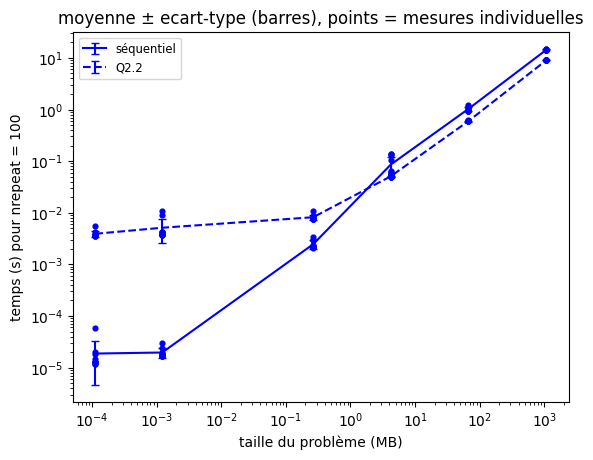

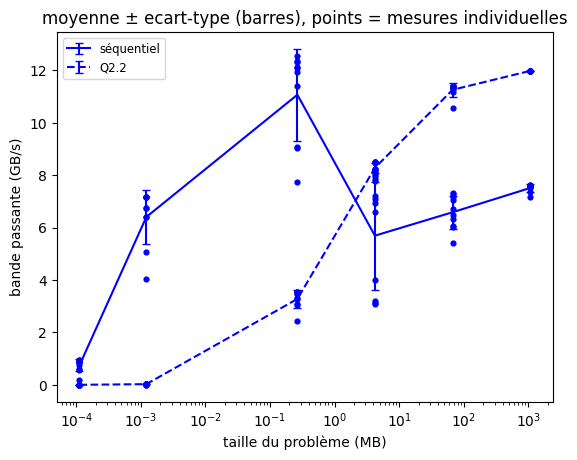

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

color_T = {1: "blue", 32: "green", 64: "orange", 128: "red", 256: "black"}
version_linestyle = {"2_1_vector_seq": "solid", "2_2_vector_cuda": "dashed", "2_6_vector_cuda": "dotted", "2_10_vector_cuda": "dashdot"}
version_nom = {"2_1_vector_seq": "séquentiel", "2_2_vector_cuda": "Q2.2", "2_6_vector_cuda": "Q2.6", "2_10_vector_cuda": "Q2.10"}


def courbe(df, version, T, colonne):
    d = df[(df['version'] == version) & (df['T'] == T)]
    if d.empty:
        return
    moy = d.groupby(['N', 'M']).mean(numeric_only=True).reset_index().sort_values('size_mb')
    ecart = d.groupby(['N', 'M']).std(numeric_only=True).reset_index().set_index(['N', 'M']).loc[list(zip(moy['N'], moy['M']))]
    label = version_nom[version] + ("" if version in ("2_1_vector_seq", "2_2_vector_cuda") else f", T = {T}")
    plt.errorbar(moy['size_mb'], moy[colonne], yerr=ecart[colonne].values, capsize=3,
                 linestyle=version_linestyle[version], color=color_T[T], label=label)
    plt.scatter(d['size_mb'], d[colonne], color=color_T[T], s=12)


def figures(courbes):
    df2 = charger("partie2_vecteur")
    for colonne, ylabel in (("runtime", "temps (s) pour nrepeat = 100"), ("bandwidth", "bande passante (GB/s)")):
        for version, T in courbes:
            courbe(df2, version, T, colonne)
        plt.xscale('log')
        if colonne == "runtime":
            plt.yscale('log')
        plt.xlabel('taille du problème (MB)')
        plt.ylabel(ylabel)
        plt.title('moyenne ± ecart-type (barres), points = mesures individuelles')
        plt.legend(fontsize='small')
        plt.show()


figures([("2_1_vector_seq", 1), ("2_2_vector_cuda", 1)])

### Question 2.5 - Discussion (un thread par bloc)

**Séquentiel et Q2.2, nrepeat = 100, 10 exécutions par taille**

| N x M (taille de A) | séquentiel : temps (s) | Q2.2 : temps (s) | séquentiel : bande passante (GB/s) | Q2.2 : bande passante (GB/s) |
|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 0.00002 ± 0.00001 | 0.00391 ± 0.00058 | 0.743 ± 0.231 | 0.00291 ± 0.00033 |
| 2^4 x 2^3 (1216 o) | 0.00002 ± 0.00000 | 0.00512 ± 0.00253 | 6.40 ± 1.04 | 0.0273 ± 0.0080 |
| 2^8 x 2^7 (265 Ko) | 0.00246 ± 0.00046 | 0.00819 ± 0.00103 | 11.1 ± 1.8 | 3.28 ± 0.35 |
| 2^10 x 2^9 (4.21 Mo) | 0.0857 ± 0.0366 | 0.0508 ± 0.0012 | 5.69 ± 2.06 | 8.28 ± 0.20 |
| 2^12 x 2^11 (67.2 Mo) | 1.03 ± 0.11 | 0.597 ± 0.014 | 6.59 ± 0.64 | 11.26 ± 0.26 |
| 2^14 x 2^13 (1.07 Go) | 14.30 ± 0.29 | 8.9646 ± 0.0058 | 7.51 ± 0.15 | 11.9797 ± 0.0078 |

Pour les très petites matrices, le CPU est beaucoup plus rapide : 0.00002 s pour 100 répétitions à 2^2 x 2^1 contre 0.0039 s sur le GPU. À chaque répétition, le GPU doit lancer un kernel, copier le résultat vers le CPU et se synchroniser, ce qui semble coûter environ 40 à 50 microsecondes (d'après nos mesures) et c'est bien plus que le calcul lui-même. Le GPU passe devant à partir de 4.21 Mo (0.051 s contre 0.086 s) et l'écart augmente ensuite : à 1.07 Go, la Q2.2 met 8.96 s contre 14.3 s pour le séquentiel, soit 1.6 fois moins. Le CPU atteint 11.1 GB/s à 265 Ko, où la matrice tient dans ses caches, puis seulement 5.7 à 7.5 GB/s au-delà.

Ce gain reste faible. À 1.07 Go, la Q2.2 atteint 11.98 GB/s. D'après les propriétés de la carte lues avec CUDA (mémoire à 6001 MHz sur un bus de 128 bits), la bande passante mémoire théorique est de 192 GB/s, soit seulement 6 %. Je pense que c'est parce que chaque bloc n'a qu'un thread : il occupe un warp dont une seule voie travaille, et ce thread lit sa ligne élément par élément sans que d'autres threads l'aident à masquer la latence de la mémoire. C'est une hypothèse qu'il aurait fallu vérifier en mesurant d'autres configurations de cette version. Les mesures sont très stables à grande taille (écart-type de 0.006 s sur 8.96 s à 1.07 Go) et plus bruitées pour les petites matrices, où le temps est dominé par les lancements.

### Question 2.6 - Plusieurs threads par bloc et atomiques

Le bloc `i` traite toujours la ligne `i`, mais avec `T` threads (argument `-T`). Le thread `t` prend les colonnes `t`, `t + T`, `t + 2T`, etc. de la ligne, ce qui fait que des threads voisins lisent des cases voisines de `A`. Chaque thread multiplie sa somme partielle par `y[i]` et l'ajoute au résultat global avec `atomicAdd`. Le résultat est remis à zéro (`cudaMemset`) avant chaque répétition, et il n'y a plus de tableau intermédiaire ni de somme sur le CPU.

In [7]:
from pathlib import Path

Path("src/2_6_vector_cuda.cu").write_text(r"""/*
//@HEADER
// ************************************************************************
//
//                        Kokkos v. 2.0
//              Copyright (2014) Sandia Corporation
//
// Under the terms of Contract DE-AC04-94AL85000 with Sandia Corporation,
// the U.S. Government retains certain rights in this software.
//
// Redistribution and use in source and binary forms, with or without
// modification, are permitted provided that the following conditions are
// met:
//
// 1. Redistributions of source code must retain the above copyright
// notice, this list of conditions and the following disclaimer.
//
// 2. Redistributions in binary form must reproduce the above copyright
// notice, this list of conditions and the following disclaimer in the
// documentation and/or other materials provided with the distribution.
//
// 3. Neither the name of the Corporation nor the names of the
// contributors may be used to endorse or promote products derived from
// this software without specific prior written permission.
//
// THIS SOFTWARE IS PROVIDED BY SANDIA CORPORATION "AS IS" AND ANY
// EXPRESS OR IMPLIED WARRANTIES, INCLUDING, BUT NOT LIMITED TO, THE
// IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR
// PURPOSE ARE DISCLAIMED. IN NO EVENT SHALL SANDIA CORPORATION OR THE
// CONTRIBUTORS BE LIABLE FOR ANY DIRECT, INDIRECT, INCIDENTAL, SPECIAL,
// EXEMPLARY, OR CONSEQUENTIAL DAMAGES (INCLUDING, BUT NOT LIMITED TO,
// PROCUREMENT OF SUBSTITUTE GOODS OR SERVICES; LOSS OF USE, DATA, OR
// PROFITS; OR BUSINESS INTERRUPTION) HOWEVER CAUSED AND ON ANY THEORY OF
// LIABILITY, WHETHER IN CONTRACT, STRICT LIABILITY, OR TORT (INCLUDING
// NEGLIGENCE OR OTHERWISE) ARISING IN ANY WAY OUT OF THE USE OF THIS
// SOFTWARE, EVEN IF ADVISED OF THE POSSIBILITY OF SUCH DAMAGE.
//
// Questions Contact  H. Carter Edwards (hcedwar@sandia.gov)
//
// ************************************************************************
//@HEADER
*/

#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <chrono>

#include <cmath>
#include <fstream>

void checkSizes( int &N, int &M, int &S, int &nrepeat );

//  bloc i traite ligne i, et ses T threads se répartissent les colonnes
__global__ void matvec_kernel(const double *A, const double *x, const double *y, double *result, int M)
{
    int i = blockIdx.x;                                      // num ligne = num bloc
    double sum = 0.0;
    for (int j = threadIdx.x; j < M; j += blockDim.x)        // le thread t prend les colonnes t, t+T, t+2T, ...
        sum += A[(long long)i * M + j] * x[j];
    atomicAdd(result, sum * y[i]);                           // chaque thread ajoute sa part au résultat global
}

int main( int argc, char* argv[] )
{
  int N = -1;         // number of rows 2^12
  int M = -1;         // number of columns 2^10
  int S = -1;         // total size 2^22
  int nrepeat = 100;  // number of repeats of the test
  int nthreads = 128;  // threads par bloc

  // Read command line arguments.
  for ( int i = 0; i < argc; i++ ) {
    if ( ( strcmp( argv[ i ], "-N" ) == 0 ) || ( strcmp( argv[ i ], "-Rows" ) == 0 ) ) {
      N = pow( 2, atoi( argv[ ++i ] ) );
      printf( "  User N is %d\n", N );
    }
    else if ( ( strcmp( argv[ i ], "-M" ) == 0 ) || ( strcmp( argv[ i ], "-Columns" ) == 0 ) ) {
      M = pow( 2, atof( argv[ ++i ] ) );
      printf( "  User M is %d\n", M );
    }
    else if ( ( strcmp( argv[ i ], "-S" ) == 0 ) || ( strcmp( argv[ i ], "-Size" ) == 0 ) ) {
      S = pow( 2, atof( argv[ ++i ] ) );
      printf( "  User S is %d\n", S );
    }
    else if ( strcmp( argv[ i ], "-nrepeat" ) == 0 ) {
      nrepeat = atoi( argv[ ++i ] );
    }
    else if ( strcmp( argv[ i ], "-T" ) == 0 ) {
      nthreads = atoi( argv[ ++i ] );
      printf( "  User nthreads is %d\n", nthreads );
    }
    else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
      printf( "  y^T*A*x Options:\n" );
      printf( "  -Rows (-N) <int>:      exponent num, determines number of rows 2^num (default: 2^12 = 4096)\n" );
      printf( "  -Columns (-M) <int>:   exponent num, determines number of columns 2^num (default: 2^10 = 1024)\n" );
      printf( "  -Size (-S) <int>:      exponent num, determines total matrix size 2^num (default: 2^22 = 4096*1024 )\n" );
      printf( "  -T <int>:              number of threads per block (default: 128)\n" );
      printf( "  -nrepeat <int>:        number of repetitions (default: 100)\n" );
      printf( "  -help (-h):            print this message\n\n" );
      exit( 1 );
    }
  }

  // Check sizes.
  checkSizes( N, M, S, nrepeat );

  // Allocate x,y,A
  auto y = (double*) std::malloc(N*sizeof(double));
  auto x = (double*) std::malloc(M*sizeof(double));
  auto A = (double*) std::malloc(N*M*sizeof(double));

  // Initialize y vector to 1.
  for (int i = 0; i < N; i++) {
    y[i] = 1.0;
  }

  // Initialize x vector to 1.
  for (int i = 0; i < M; i++) {
    x[i] = 1.0;
  }

  // Initialize A matrix, you can use a 1D index if you want a flat structure (i.e. a 1D array) e.g. j*M+i is the same than [j][i]
  for (int j = 0; j < N; j++) {
    for (int i = 0; i < M; i++) {
      A[j*M+i] = 1.0;
    }
  }

  // on copie les données sur le GPU (hors chrono)
  double *d_A, *d_x, *d_y, *d_result;
  if (cudaMalloc(&d_A, (size_t)N * M * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
  if (cudaMalloc(&d_x, M * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
  if (cudaMalloc(&d_y, N * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
  if (cudaMalloc(&d_result, sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
  cudaMemcpy(d_A, A, (size_t)N * M * sizeof(double), cudaMemcpyHostToDevice);
  cudaMemcpy(d_x, x, M * sizeof(double), cudaMemcpyHostToDevice);
  cudaMemcpy(d_y, y, N * sizeof(double), cudaMemcpyHostToDevice);

  // Timer products.
  auto begin = std::chrono::high_resolution_clock::now();

  for ( int repeat = 0; repeat < nrepeat; repeat++ ) {
    cudaMemset(d_result, 0, sizeof(double));       // le résultat repart de 0 à chaque répétition
    matvec_kernel<<<N, nthreads>>>(d_A, d_x, d_y, d_result, M);
    cudaError_t err = cudaGetLastError();
    if (err != cudaSuccess) { printf("Erreur CUDA : %s\n", cudaGetErrorString(err)); return 4; }      // garde ton test d'erreur
    double result;
    cudaMemcpy(&result, d_result, sizeof(double), cudaMemcpyDeviceToHost);



    // Output result.
    if ( repeat == ( nrepeat - 1 ) ) {
      printf( "  Computed result for %d x %d is %lf\n", N, M, result );
    }

    const double solution = (double) N * (double) M;

    if ( result != solution ) {
      printf( "  Error: result( %lf ) != solution( %lf )\n", result, solution );
    }
  }
  auto end = std::chrono::high_resolution_clock::now();
  double time = std::chrono::duration<double>(end - begin).count();


  // Calculate bandwidth.
  // Each matrix A row (each of length M) is read once.
  // The x vector (of length M) is read N times.
  // The y vector (of length N) is read once.
  // double Gbytes = 1.0e-9 * double( sizeof(double) * ( 2 * M * N + N ) );
  double Gbytes = 1.0e-9 * double( sizeof(double) * ( M + M * N + N ) );

  // Print results (problem size, time and bandwidth in GB/s).
  printf( "  N( %d ) M( %d ) nrepeat ( %d ) problem( %g MB ) time( %g s ) bandwidth( %g GB/s )\n",
          N, M, nrepeat, Gbytes * 1000, time, Gbytes * nrepeat / time );
  std::ofstream("stats_cuda_vecteur.csv", std::ios::app) << "2_6_vector_cuda," << nthreads << "," << N << "," << M << "," << Gbytes * 1000 << "," << time << "," << Gbytes * nrepeat / time << "\n";

  cudaFree(d_A); cudaFree(d_x); cudaFree(d_y); cudaFree(d_result);
  std::free(A);
  std::free(y);
  std::free(x);

  return 0;
}

void checkSizes( int &N, int &M, int &S, int &nrepeat ) {
  // If S is undefined and N or M is undefined, set S to 2^22 or the bigger of N and M.
  if ( S == -1 && ( N == -1 || M == -1 ) ) {
    S = pow( 2, 22 );
    if ( S < N ) S = N;
    if ( S < M ) S = M;
  }

  // If S is undefined and both N and M are defined, set S = N * M.
  if ( S == -1 ) S = N * M;

  // If both N and M are undefined, fix row length to the smaller of S and 2^10 = 1024.
  if ( N == -1 && M == -1 ) {
    if ( S > 1024 ) {
      M = 1024;
    }
    else {
      M = S;
    }
  }

  // If only M is undefined, set it.
  if ( M == -1 ) M = S / N;

  // If N is undefined, set it.
  if ( N == -1 ) N = S / M;

  printf( "  Total size S = %d N = %d M = %d\n", S, N, M );

  // Check sizes.
  if ( ( S < 0 ) || ( N < 0 ) || ( M < 0 ) || ( nrepeat < 0 ) ) {
    printf( "  Sizes must be greater than 0.\n" );
    exit( 1 );
  }

  if ( ( N * M ) != S ) {
    printf( "  N * M != S\n" );
    exit( 1 );
  }
}
""", encoding="utf8")

8882

In [6]:
!.\build.bat src\2_6_vector_cuda.cu

2_6_vector_cuda.cu


In [16]:
!.\bin\2_6_vector_cuda.exe -N 12 -M 10 -T 128

  User N is 4096
  User M is 1024
  User nthreads is 128
  Total size S = 4194304 N = 4096 M = 1024
  Computed result for 4096 x 1024 is 4194304.000000
  N( 4096 ) M( 1024 ) nrepeat ( 100 ) problem( 33.5954 MB ) time( 0.123025 s ) bandwidth( 27.3078 GB/s )


### Question 2.7 - Évaluation de performance (plusieurs threads par bloc)

Mêmes paires (N, M) que pour la question 2.3. L'énoncé ne fixe pas le nombre de threads par bloc : je prends T = 32, 64, 128 et 256, soit un warp complet jusqu'à une taille de bloc courante.

In [ ]:
nettoyer_csv("partie2_vecteur")
mesurer_vecteur("2_6_vector_cuda", T_cuda, avec_T=True)

### Question 2.8 - Figures de performance (plusieurs threads par bloc)

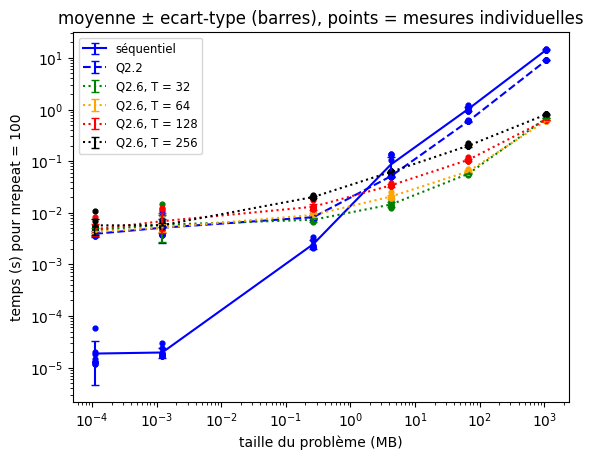

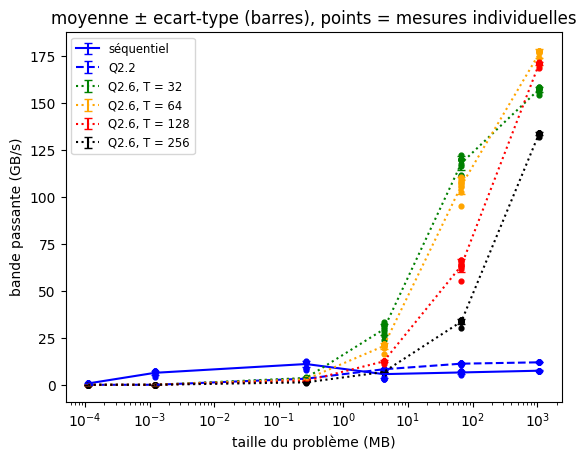

In [4]:
figures([("2_1_vector_seq", 1), ("2_2_vector_cuda", 1)] + [("2_6_vector_cuda", T) for T in T_cuda])

### Question 2.9 - Discussion (plusieurs threads par bloc)

**Q2.6, temps en secondes, nrepeat = 100, 10 exécutions par configuration**

| N x M (taille de A) | T = 32 | T = 64 | T = 128 | T = 256 |
|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 0.00459 ± 0.00049 | 0.00425 ± 0.00011 | 0.00480 ± 0.00124 | 0.00568 ± 0.00200 |
| 2^4 x 2^3 (1216 o) | 0.00586 ± 0.00318 | 0.00516 ± 0.00096 | 0.00686 ± 0.00283 | 0.00573 ± 0.00053 |
| 2^8 x 2^7 (265 Ko) | 0.00731 ± 0.00069 | 0.00905 ± 0.00068 | 0.0131 ± 0.0018 | 0.0201 ± 0.0010 |
| 2^10 x 2^9 (4.21 Mo) | 0.0144 ± 0.0016 | 0.0205 ± 0.0019 | 0.0338 ± 0.0017 | 0.0618 ± 0.0017 |
| 2^12 x 2^11 (67.2 Mo) | 0.0570 ± 0.0019 | 0.0634 ± 0.0028 | 0.1061 ± 0.0061 | 0.1997 ± 0.0079 |
| 2^14 x 2^13 (1.07 Go) | 0.6826 ± 0.0056 | 0.6094 ± 0.0091 | 0.6286 ± 0.0028 | 0.8031 ± 0.0039 |

**Q2.6, bande passante en GB/s, nrepeat = 100, 10 exécutions par configuration**

| N x M (taille de A) | T = 32 | T = 64 | T = 128 | T = 256 |
|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 0.00246 ± 0.00024 | 0.00264 ± 0.00007 | 0.00242 ± 0.00038 | 0.00211 ± 0.00046 |
| 2^4 x 2^3 (1216 o) | 0.0235 ± 0.0057 | 0.0241 ± 0.0032 | 0.0198 ± 0.0059 | 0.0214 ± 0.0017 |
| 2^8 x 2^7 (265 Ko) | 3.65 ± 0.32 | 2.94 ± 0.20 | 2.06 ± 0.23 | 1.319 ± 0.065 |
| 2^10 x 2^9 (4.21 Mo) | 29.5 ± 3.1 | 20.6 ± 1.6 | 12.45 ± 0.57 | 6.81 ± 0.18 |
| 2^12 x 2^11 (67.2 Mo) | 117.9 ± 3.7 | 106.1 ± 4.4 | 63.4 ± 3.3 | 33.7 ± 1.2 |
| 2^14 x 2^13 (1.07 Go) | 157.3 ± 1.3 | 176.3 ± 2.6 | 170.84 ± 0.76 | 133.72 ± 0.65 |

Ajouter des threads dans le bloc change complètement le résultat à grande taille. À 1.07 Go, le meilleur temps est 0.609 s avec T = 64, soit 14.7 fois moins que la Q2.2 (8.96 s) et 23 fois moins que le séquentiel (14.3 s). La bande passante atteint 176 GB/s, soit 92 % du maximum théorique de la carte (192 GB/s). À cette taille le calcul est limité par la mémoire, et il reste peu à gagner.

Pour les tailles petites et moyennes, le temps augmente avec T, ce qui est l'inverse de ce à quoi je m'attendais. À 4.21 Mo, il passe de 0.0144 s (T = 32) à 0.0618 s (T = 256), et à 67.2 Mo de 0.0570 s à 0.1997 s. Chaque thread fait un atomicAdd sur le résultat global, donc il y a N x T additions atomiques par répétition, toutes sur la même adresse. Si on divise ce nombre par le temps mesuré, on trouve environ 5.2 x 10^8 additions atomiques par seconde à T = 256, à 67.2 Mo comme à 1.07 Go (4096 x 256 x 100 additions en 0.1997 s, et 16384 x 256 x 100 en 0.8031 s), et environ 4.9 x 10^8 à T = 128 à 67.2 Mo. Ce débit est le même pour deux tailles différentes, ce qui laisse penser que le fait que les additions sont exécutées l'une après l'autre sur une seule adresse limite le temps quand T est grand (environ une addition tous les 3 cycles de l'horloge à 1.68 GHz). C'est mon interprétation et je ne l'ai pas vérifiée avec un autre outil. À T = 32, il y a 8 fois moins d'additions et le temps se rapproche de celui de la lecture de la mémoire (117.9 GB/s à 67.2 Mo).

Aux très petites tailles (112 o et 1216 o), tous les T donnent environ 4 à 7 ms pour 100 répétitions, comme la Q2.2. Le coût d'un lancement de kernel et d'une copie domine, et le nombre de threads ne compte pas. Les mesures sont bruitées à ces tailles, avec un écart-type parfois du même ordre que la moyenne (0.00318 pour 0.00586 s à 2^4 x 2^3 et T = 32).

### Question 2.10 - Mémoire partagée et atomiques

Chaque bloc a une variable `__shared__` qui contient le total de sa ligne. Les `T` threads y ajoutent leur somme partielle avec `atomicAdd` (en mémoire partagée), puis un seul thread par bloc ajoute le total du bloc, multiplié par `y[i]`, au résultat global avec un `atomicAdd`. Il y a donc `N` additions atomiques globales au lieu de `N x T` à la question 2.6. Deux `__syncthreads()` garantissent que le total est initialisé avant les ajouts et est complet avant la lecture.

In [10]:
from pathlib import Path

Path("src/2_10_vector_cuda.cu").write_text(r"""/*
//@HEADER
// ************************************************************************
//
//                        Kokkos v. 2.0
//              Copyright (2014) Sandia Corporation
//
// Under the terms of Contract DE-AC04-94AL85000 with Sandia Corporation,
// the U.S. Government retains certain rights in this software.
//
// Redistribution and use in source and binary forms, with or without
// modification, are permitted provided that the following conditions are
// met:
//
// 1. Redistributions of source code must retain the above copyright
// notice, this list of conditions and the following disclaimer.
//
// 2. Redistributions in binary form must reproduce the above copyright
// notice, this list of conditions and the following disclaimer in the
// documentation and/or other materials provided with the distribution.
//
// 3. Neither the name of the Corporation nor the names of the
// contributors may be used to endorse or promote products derived from
// this software without specific prior written permission.
//
// THIS SOFTWARE IS PROVIDED BY SANDIA CORPORATION "AS IS" AND ANY
// EXPRESS OR IMPLIED WARRANTIES, INCLUDING, BUT NOT LIMITED TO, THE
// IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR
// PURPOSE ARE DISCLAIMED. IN NO EVENT SHALL SANDIA CORPORATION OR THE
// CONTRIBUTORS BE LIABLE FOR ANY DIRECT, INDIRECT, INCIDENTAL, SPECIAL,
// EXEMPLARY, OR CONSEQUENTIAL DAMAGES (INCLUDING, BUT NOT LIMITED TO,
// PROCUREMENT OF SUBSTITUTE GOODS OR SERVICES; LOSS OF USE, DATA, OR
// PROFITS; OR BUSINESS INTERRUPTION) HOWEVER CAUSED AND ON ANY THEORY OF
// LIABILITY, WHETHER IN CONTRACT, STRICT LIABILITY, OR TORT (INCLUDING
// NEGLIGENCE OR OTHERWISE) ARISING IN ANY WAY OUT OF THE USE OF THIS
// SOFTWARE, EVEN IF ADVISED OF THE POSSIBILITY OF SUCH DAMAGE.
//
// Questions Contact  H. Carter Edwards (hcedwar@sandia.gov)
//
// ************************************************************************
//@HEADER
*/

#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <chrono>

#include <cmath>
#include <fstream>

void checkSizes( int &N, int &M, int &S, int &nrepeat );

__global__ void matvec_kernel(const double *A, const double *x, const double *y, double *result, int M)
{
    __shared__ double block_total;
    int i = blockIdx.x;

    if (threadIdx.x == 0) block_total = 0.0;
    __syncthreads();

    double sum = 0.0;
    for (int j = threadIdx.x; j < M; j += blockDim.x)
        sum += A[(long long)i * M + j] * x[j];

    atomicAdd(&block_total, sum);
    __syncthreads();

    if (threadIdx.x == 0)
        atomicAdd(result, block_total * y[i]);
}

int main( int argc, char* argv[] )
{
  int N = -1;         // number of rows 2^12
  int M = -1;         // number of columns 2^10
  int S = -1;         // total size 2^22
  int nrepeat = 100;  // number of repeats of the test
  int nthreads = 128;  // threads par bloc

  // Read command line arguments.
  for ( int i = 0; i < argc; i++ ) {
    if ( ( strcmp( argv[ i ], "-N" ) == 0 ) || ( strcmp( argv[ i ], "-Rows" ) == 0 ) ) {
      N = pow( 2, atoi( argv[ ++i ] ) );
      printf( "  User N is %d\n", N );
    }
    else if ( ( strcmp( argv[ i ], "-M" ) == 0 ) || ( strcmp( argv[ i ], "-Columns" ) == 0 ) ) {
      M = pow( 2, atof( argv[ ++i ] ) );
      printf( "  User M is %d\n", M );
    }
    else if ( ( strcmp( argv[ i ], "-S" ) == 0 ) || ( strcmp( argv[ i ], "-Size" ) == 0 ) ) {
      S = pow( 2, atof( argv[ ++i ] ) );
      printf( "  User S is %d\n", S );
    }
    else if ( strcmp( argv[ i ], "-nrepeat" ) == 0 ) {
      nrepeat = atoi( argv[ ++i ] );
    }
    else if ( strcmp( argv[ i ], "-T" ) == 0 ) {
      nthreads = atoi( argv[ ++i ] );
      printf( "  User nthreads is %d\n", nthreads );
    }
    else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
      printf( "  y^T*A*x Options:\n" );
      printf( "  -Rows (-N) <int>:      exponent num, determines number of rows 2^num (default: 2^12 = 4096)\n" );
      printf( "  -Columns (-M) <int>:   exponent num, determines number of columns 2^num (default: 2^10 = 1024)\n" );
      printf( "  -Size (-S) <int>:      exponent num, determines total matrix size 2^num (default: 2^22 = 4096*1024 )\n" );
      printf( "  -T <int>:              number of threads per block (default: 128)\n" );
      printf( "  -nrepeat <int>:        number of repetitions (default: 100)\n" );
      printf( "  -help (-h):            print this message\n\n" );
      exit( 1 );
    }
  }

  // Check sizes.
  checkSizes( N, M, S, nrepeat );

  // Allocate x,y,A
  auto y = (double*) std::malloc(N*sizeof(double));
  auto x = (double*) std::malloc(M*sizeof(double));
  auto A = (double*) std::malloc(N*M*sizeof(double));

  // Initialize y vector to 1.
  for (int i = 0; i < N; i++) {
    y[i] = 1.0;
  }

  // Initialize x vector to 1.
  for (int i = 0; i < M; i++) {
    x[i] = 1.0;
  }

  // Initialize A matrix, you can use a 1D index if you want a flat structure (i.e. a 1D array) e.g. j*M+i is the same than [j][i]
  for (int j = 0; j < N; j++) {
    for (int i = 0; i < M; i++) {
      A[j*M+i] = 1.0;
    }
  }

  // on copie les données sur le GPU (hors chrono)
  double *d_A, *d_x, *d_y, *d_result;
  if (cudaMalloc(&d_A, (size_t)N * M * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
  if (cudaMalloc(&d_x, M * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
  if (cudaMalloc(&d_y, N * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
  if (cudaMalloc(&d_result, sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
  cudaMemcpy(d_A, A, (size_t)N * M * sizeof(double), cudaMemcpyHostToDevice);
  cudaMemcpy(d_x, x, M * sizeof(double), cudaMemcpyHostToDevice);
  cudaMemcpy(d_y, y, N * sizeof(double), cudaMemcpyHostToDevice);

  // Timer products.
  auto begin = std::chrono::high_resolution_clock::now();

  for ( int repeat = 0; repeat < nrepeat; repeat++ ) {
    cudaMemset(d_result, 0, sizeof(double));       // le résultat repart de 0 à chaque répétition
    matvec_kernel<<<N, nthreads>>>(d_A, d_x, d_y, d_result, M);
    cudaError_t err = cudaGetLastError();
    if (err != cudaSuccess) { printf("Erreur CUDA : %s\n", cudaGetErrorString(err)); return 4; }      // garde ton test d'erreur
    double result;
    cudaMemcpy(&result, d_result, sizeof(double), cudaMemcpyDeviceToHost);



    // Output result.
    if ( repeat == ( nrepeat - 1 ) ) {
      printf( "  Computed result for %d x %d is %lf\n", N, M, result );
    }

    const double solution = (double) N * (double) M;

    if ( result != solution ) {
      printf( "  Error: result( %lf ) != solution( %lf )\n", result, solution );
    }
  }
  auto end = std::chrono::high_resolution_clock::now();
  double time = std::chrono::duration<double>(end - begin).count();


  // Calculate bandwidth.
  // Each matrix A row (each of length M) is read once.
  // The x vector (of length M) is read N times.
  // The y vector (of length N) is read once.
  // double Gbytes = 1.0e-9 * double( sizeof(double) * ( 2 * M * N + N ) );
  double Gbytes = 1.0e-9 * double( sizeof(double) * ( M + M * N + N ) );

  // Print results (problem size, time and bandwidth in GB/s).
  printf( "  N( %d ) M( %d ) nrepeat ( %d ) problem( %g MB ) time( %g s ) bandwidth( %g GB/s )\n",
          N, M, nrepeat, Gbytes * 1000, time, Gbytes * nrepeat / time );
  std::ofstream("stats_cuda_vecteur.csv", std::ios::app) << "2_10_vector_cuda," << nthreads << "," << N << "," << M << "," << Gbytes * 1000 << "," << time << "," << Gbytes * nrepeat / time << "\n";

  cudaFree(d_A); cudaFree(d_x); cudaFree(d_y); cudaFree(d_result);
  std::free(A);
  std::free(y);
  std::free(x);

  return 0;
}

void checkSizes( int &N, int &M, int &S, int &nrepeat ) {
  // If S is undefined and N or M is undefined, set S to 2^22 or the bigger of N and M.
  if ( S == -1 && ( N == -1 || M == -1 ) ) {
    S = pow( 2, 22 );
    if ( S < N ) S = N;
    if ( S < M ) S = M;
  }

  // If S is undefined and both N and M are defined, set S = N * M.
  if ( S == -1 ) S = N * M;

  // If both N and M are undefined, fix row length to the smaller of S and 2^10 = 1024.
  if ( N == -1 && M == -1 ) {
    if ( S > 1024 ) {
      M = 1024;
    }
    else {
      M = S;
    }
  }

  // If only M is undefined, set it.
  if ( M == -1 ) M = S / N;

  // If N is undefined, set it.
  if ( N == -1 ) N = S / M;

  printf( "  Total size S = %d N = %d M = %d\n", S, N, M );

  // Check sizes.
  if ( ( S < 0 ) || ( N < 0 ) || ( M < 0 ) || ( nrepeat < 0 ) ) {
    printf( "  Sizes must be greater than 0.\n" );
    exit( 1 );
  }

  if ( ( N * M ) != S ) {
    printf( "  N * M != S\n" );
    exit( 1 );
  }
}
""", encoding="utf8")

8811

In [7]:
!.\build.bat src\2_10_vector_cuda.cu

2_10_vector_cuda.cu


In [18]:
!.\bin\2_10_vector_cuda.exe -N 12 -M 10 -T 128

  User N is 4096
  User M is 1024
  User nthreads is 128
  Total size S = 4194304 N = 4096 M = 1024
  Computed result for 4096 x 1024 is 4194304.000000
  N( 4096 ) M( 1024 ) nrepeat ( 100 ) problem( 33.5954 MB ) time( 0.13565 s ) bandwidth( 24.7662 GB/s )


### Question 2.11 - Évaluation de performance (mémoire partagée)

Mêmes paires (N, M) et mêmes valeurs de T que pour la question 2.7.

In [ ]:
nettoyer_csv("partie2_vecteur")
mesurer_vecteur("2_10_vector_cuda", T_cuda, avec_T=True)

### Question 2.12 - Figures de performance (mémoire partagée)

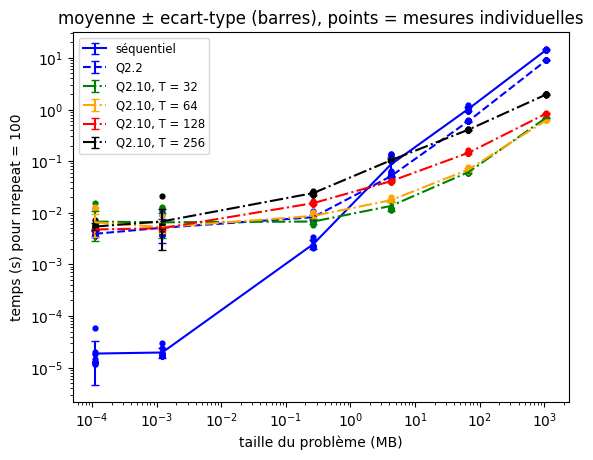

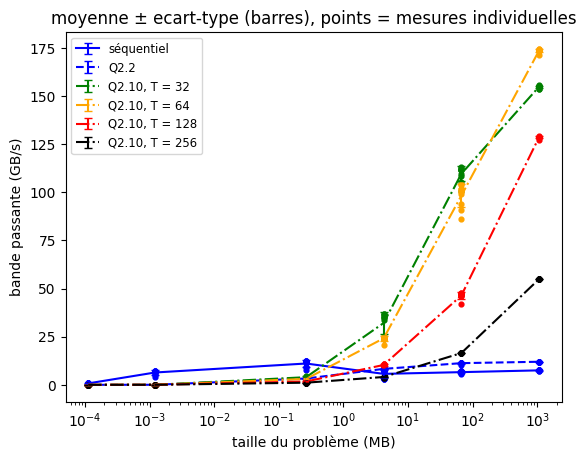

In [5]:
figures([("2_1_vector_seq", 1), ("2_2_vector_cuda", 1)] + [("2_10_vector_cuda", T) for T in T_cuda])

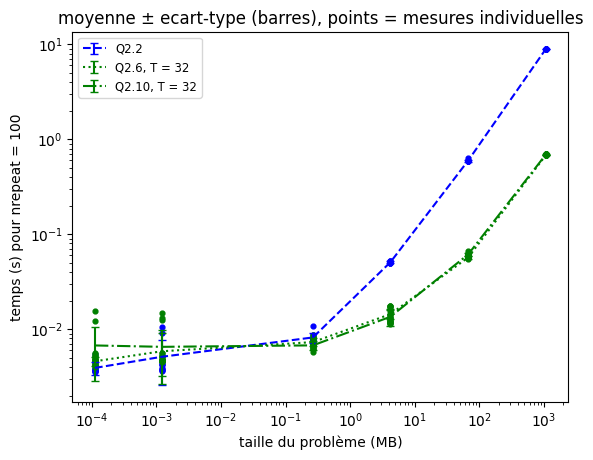

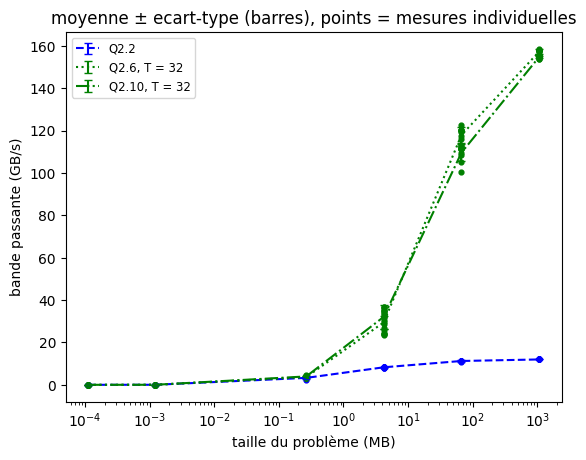

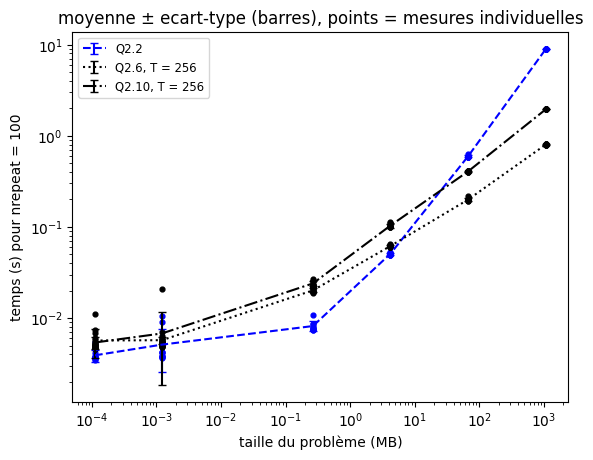

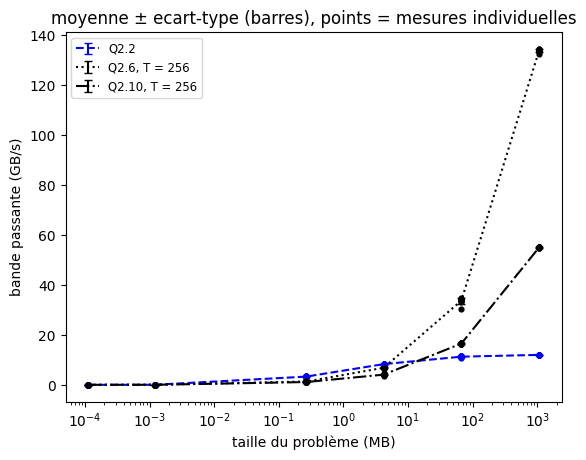

In [6]:
# comparaison des trois versions CUDA pour une valeur de T donnee
for T in (32, 256):
    figures([("2_2_vector_cuda", 1), ("2_6_vector_cuda", T), ("2_10_vector_cuda", T)])

### Question 2.13 - Discussion (mémoire partagée)

**Q2.10, temps en secondes, nrepeat = 100, 10 exécutions par configuration**

| N x M (taille de A) | T = 32 | T = 64 | T = 128 | T = 256 |
|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 0.00674 ± 0.00390 | 0.00651 ± 0.00311 | 0.00474 ± 0.00014 | 0.00541 ± 0.00083 |
| 2^4 x 2^3 (1216 o) | 0.00652 ± 0.00331 | 0.00526 ± 0.00129 | 0.00502 ± 0.00039 | 0.00679 ± 0.00493 |
| 2^8 x 2^7 (265 Ko) | 0.00676 ± 0.00078 | 0.00868 ± 0.00071 | 0.01532 ± 0.00081 | 0.0240 ± 0.0017 |
| 2^10 x 2^9 (4.21 Mo) | 0.0135 ± 0.0027 | 0.0175 ± 0.0011 | 0.0408 ± 0.0012 | 0.1036 ± 0.0051 |
| 2^12 x 2^11 (67.2 Mo) | 0.0613 ± 0.0023 | 0.0686 ± 0.0045 | 0.1450 ± 0.0058 | 0.4070 ± 0.0026 |
| 2^14 x 2^13 (1.07 Go) | 0.6935 ± 0.0026 | 0.6186 ± 0.0032 | 0.8349 ± 0.0031 | 1.9553 ± 0.0035 |

**Rapport du temps Q2.10 / Q2.6 (supérieur à 1 : la Q2.10 est plus lente)**

| N x M (taille de A) | T = 32 | T = 64 | T = 128 | T = 256 |
|---|---|---|---|---|
| 2^2 x 2^1 (112 o) | 1.47 | 1.53 | 0.99 | 0.95 |
| 2^4 x 2^3 (1216 o) | 1.11 | 1.02 | 0.73 | 1.19 |
| 2^8 x 2^7 (265 Ko) | 0.92 | 0.96 | 1.17 | 1.19 |
| 2^10 x 2^9 (4.21 Mo) | 0.94 | 0.85 | 1.21 | 1.68 |
| 2^12 x 2^11 (67.2 Mo) | 1.08 | 1.08 | 1.37 | 2.04 |
| 2^14 x 2^13 (1.07 Go) | 1.02 | 1.02 | 1.33 | 2.43 |

La Q2.10 n'améliore pas la Q2.6, contrairement à ce à quoi je m'attendais. Le rapport des temps est proche de 1 pour T = 32 et T = 64 (de 0.85 à 1.08 entre 4.21 Mo et 1.07 Go) et devient supérieur à 1 pour T = 128 et T = 256. À 1.07 Go, la Q2.10 est 1.33 fois plus lente à T = 128 et 2.43 fois plus lente à T = 256 (1.9553 s contre 0.8031 s). À 4.21 Mo elle gagne un peu pour T = 32 et T = 64 (rapports de 0.94 et 0.85), mais l'écart ne dépasse pas 3 ms.

L'idée de la Q2.10 était de remplacer les N x T additions atomiques globales par N additions globales, plus des additions atomiques en mémoire partagée entre les T threads d'un même bloc. Ça supprime le goulot repéré pour la Q2.6, mais la contention se déplace à l'intérieur de chaque bloc, puisque les T threads additionnent sur la même variable partagée. 
Hypothèse : l'addition atomique d'un double en mémoire partagée serait émulée sur cette carte par une boucle de comparaison et d'échange (compare-and-swap). Ça coûterait cher quand T threads se disputent la même variable et expliquerait que le temps augmente avec T (de 0.6935 s à 1.9553 s entre T = 32 et T = 256 à 1.07 Go). Une réduction en arbre dans la mémoire partagée, comme en partie 1 (Q1.4), éviterait toute addition atomique entre les threads et serait probablement meilleure, mais l'énoncé ne la demande pas.

À T = 32 et T = 64, le temps à 1.07 Go est identique à celui de la Q2.6 (rapport de 1.02), proche du maximum de la mémoire. Quand les additions atomiques ne limitent pas le temps, les deux versions semblent limitées par la mémoire et se valent.

## 3. Matrix multiplication and floating point precision

In [1]:
from pathlib import Path

Path("src/3_0_matrix_mul_depart.cpp").write_text(r"""/*
**  PROGRAM: Matrix Multiply
**
**  PURPOSE: This is a simple matrix multiply program. 
**           It will compute the product
**
**                C  = A * B
**
**           A and B are set to constant matrices so we
**           can make a quick test of the multiplication.
**
**
**  HISTORY: Written by Tim Mattson, Nov 1999.
*            Modified and extended by Jonathan Rouzaud-Cornabas, Oct 2022
*/


#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <sys/time.h>

#define AVAL 3.14
#define BVAL 5.42
#define TOL  0.001

int main(int argc, char **argv)
{
    int Ndim = 1000, Pdim = 1000, Mdim = 1000;   /* A[N][P], B[P][M], C[N][M] */
	int i,j,k;
	double *A, *B, *C, cval, tmp, err, errsq;
    double dN, dM, dP, mflops;


    
    // Read command line arguments.
      for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 )) {
            Ndim = atoi( argv[ ++i ] );
            printf( "  User N is %d\n", Ndim );
        } else if ( ( strcmp( argv[ i ], "-M" ) == 0 )) {
            Mdim = atoi( argv[ ++i ] );
            printf( "  User M is %d\n", Mdim );
        } else if ( ( strcmp( argv[ i ], "-P" ) == 0 )) {
            Pdim = atoi( argv[ ++i ] );
            printf( "  User P is %d\n", Pdim );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Matrix multiplication Options:\n" );
            printf( "  -N <int>:              Size of the dimension N (by default 1000)\n" );
            printf( "  -M <int>:              Size of the dimension M (by default 1000)\n" );
            printf( "  -P <int>:              Size of the dimension P (by default 1000)\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
      }
      
	
      A = (double *)malloc(Ndim*Pdim*sizeof(double));
      B = (double *)malloc(Pdim*Mdim*sizeof(double));
      C = (double *)malloc(Ndim*Mdim*sizeof(double));

	/* Initialize matrices */

	for (i=0; i<Ndim; i++)
		for (j=0; j<Pdim; j++)
			*(A+(i*Ndim+j)) = AVAL;

	for (i=0; i<Pdim; i++)
		for (j=0; j<Mdim; j++)
			*(B+(i*Pdim+j)) = BVAL;

	for (i=0; i<Ndim; i++)
		for (j=0; j<Mdim; j++)
			*(C+(i*Ndim+j)) = 0.0;

	/* Do the matrix product */
    
    // Timer products.
    struct timeval begin, end;

    gettimeofday( &begin, NULL );
    
    for (i=0; i<Ndim; i++){
		for (j=0; j<Mdim; j++){
			tmp = 0.0;
			for(k=0;k<Pdim;k++){
				/* C(i,j) = sum(over k) A(i,k) * B(k,j) */
				tmp += *(A+(i*Ndim+k)) *  *(B+(k*Pdim+j));
			}
			*(C+(i*Ndim+j)) = tmp;
		}
	}
	/* Check the answer */


    gettimeofday( &end, NULL );

    // Calculate time.
    double time = 1.0 * ( end.tv_sec - begin.tv_sec ) +
                1.0e-6 * ( end.tv_usec - begin.tv_usec );
                
	printf(" N %d M %d P %d multiplication in %f seconds \n", Ndim, Mdim, Pdim, time);

      dN = (double)Ndim;
      dM = (double)Mdim;
      dP = (double)Pdim;
      mflops = 2.0 * dN * dN * dN/(1000000.0* time);
 
	printf(" N %d M %d P %d multiplication at %f mflops\n", Ndim, Mdim, Pdim, mflops);

	cval = Pdim * AVAL * BVAL;
	errsq = 0.0;
	for (i=0; i<Ndim; i++){
		for (j=0; j<Mdim; j++){
			err = *(C+i*Ndim+j) - cval;
		    errsq += err * err;
		}
	}

	if (errsq > TOL) 
		printf("\n Errors in multiplication: %f",errsq);
	else
		printf("\n Hey, it worked");

	printf("\n all done \n");
}
""", encoding="utf8")

3392

In [19]:
!g++ -O2 -Wall -o bin/3_0_matrix_mul_depart.exe src/3_0_matrix_mul_depart.cpp

src/3_0_matrix_mul_depart.cpp: In function 'int main(int, char**)':
src/3_0_matrix_mul_depart.cpp:33:16: warning: variable 'dM' set but not used [-Wunused-but-set-variable]
   33 |     double dN, dM, dP, mflops;
      |                ^~
src/3_0_matrix_mul_depart.cpp:33:20: warning: variable 'dP' set but not used [-Wunused-but-set-variable]
   33 |     double dN, dM, dP, mflops;
      |                    ^~


In [20]:
!.\bin\3_0_matrix_mul_depart.exe -N 500 -M 500 -P 500

  User N is 500
  User M is 500
  User P is 500
 N 500 M 500 P 500 multiplication in 0.201540 seconds 
 N 500 M 500 P 500 multiplication at 1240.448546 mflops

 Hey, it worked
 all done 


### Question 3.1 - Port CUDA (un thread par bloc)

Le kernel est lancé avec un bloc d'un seul thread par élément de `C`, soit une grille de M x N blocs. Le bloc (j, i) calcule `C[i][j]` avec la boucle sur k. Les pas d'indexation sont corrigés par rapport au code de départ (`A` a P colonnes, `B` et `C` en ont M), ce qui ne change rien pour des matrices carrées. Les copies de `A` et `B` vers le GPU et de `C` vers le CPU ne sont pas chronométrées : le temps comprend le lancement du kernel et son exécution (`cudaDeviceSynchronize`). Les MFlops sont calculés avec 2 x N x M x P opérations.

In [4]:
from pathlib import Path

Path("src/3_1_matrix_mul_cuda.cu").write_text(r"""/*
**  PROGRAM: Matrix Multiply
**
**  PURPOSE: This is a simple matrix multiply program. 
**           It will compute the product
**
**                C  = A * B
**
**           A and B are set to constant matrices so we
**           can make a quick test of the multiplication.
**
**
**  HISTORY: Written by Tim Mattson, Nov 1999.
*            Modified and extended by Jonathan Rouzaud-Cornabas, Oct 2022
*/


#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <chrono>
#include <fstream>
#include <cmath>

#define AVAL 3.14
#define BVAL 5.42
#define TOL  0.001

__global__ void matmul_kernel(const double *A, const double *B, double *C, int M, int P)
{
    int i = blockIdx.y;
    int j = blockIdx.x;
    double tmp = 0.0;
    for (int k = 0; k < P; k++)
        tmp += A[(long long)i * P + k] * B[(long long)k * M + j];
    C[(long long)i * M + j] = tmp;
}

int main(int argc, char **argv)
{
    int Ndim = 1000, Pdim = 1000, Mdim = 1000;   /* A[N][P], B[P][M], C[N][M] */
	int i,j;
	double *A, *B, *C;
	double cval, err, errsq;
    double dN, dM, dP, mflops;

    // Read command line arguments.
      for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 )) {
            Ndim = atoi( argv[ ++i ] );
            printf( "  User N is %d\n", Ndim );
        } else if ( ( strcmp( argv[ i ], "-M" ) == 0 )) {
            Mdim = atoi( argv[ ++i ] );
            printf( "  User M is %d\n", Mdim );
        } else if ( ( strcmp( argv[ i ], "-P" ) == 0 )) {
            Pdim = atoi( argv[ ++i ] );
            printf( "  User P is %d\n", Pdim );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Matrix multiplication Options:\n" );
            printf( "  -N <int>:              Size of the dimension N (by default 1000)\n" );
            printf( "  -M <int>:              Size of the dimension M (by default 1000)\n" );
            printf( "  -P <int>:              Size of the dimension P (by default 1000)\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
      }


      A = (double *)malloc((size_t)Ndim*Pdim*sizeof(double));
      B = (double *)malloc((size_t)Pdim*Mdim*sizeof(double));
      C = (double *)malloc((size_t)Ndim*Mdim*sizeof(double));

	/* Initialize matrices */

	for (i=0; i<Ndim; i++)
		for (j=0; j<Pdim; j++)
			*(A+((size_t)i*Pdim+j)) = AVAL;

	for (i=0; i<Pdim; i++)
		for (j=0; j<Mdim; j++)
			*(B+((size_t)i*Mdim+j)) = BVAL;

	for (i=0; i<Ndim; i++)
		for (j=0; j<Mdim; j++)
			*(C+((size_t)i*Mdim+j)) = 0.0;

	/* Do the matrix product */

    double *d_A, *d_B, *d_C;
    if (cudaMalloc(&d_A, (size_t)Ndim * Pdim * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
    if (cudaMalloc(&d_B, (size_t)Pdim * Mdim * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
    if (cudaMalloc(&d_C, (size_t)Ndim * Mdim * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
    cudaMemcpy(d_A, A, (size_t)Ndim * Pdim * sizeof(double), cudaMemcpyHostToDevice);
    cudaMemcpy(d_B, B, (size_t)Pdim * Mdim * sizeof(double), cudaMemcpyHostToDevice);

    dim3 grille(Mdim, Ndim);

    // Timer products.
    auto begin = std::chrono::high_resolution_clock::now();

    matmul_kernel<<<grille, 1>>>(d_A, d_B, d_C, Mdim, Pdim);
    cudaError_t erreur = cudaGetLastError();
    if (erreur != cudaSuccess) { printf("Erreur CUDA : %s\n", cudaGetErrorString(erreur)); return 4; }
    cudaDeviceSynchronize();

    auto end = std::chrono::high_resolution_clock::now();
    double time = std::chrono::duration<double>(end - begin).count();

    cudaMemcpy(C, d_C, (size_t)Ndim * Mdim * sizeof(double), cudaMemcpyDeviceToHost);

	printf(" N %d M %d P %d multiplication in %f seconds \n", Ndim, Mdim, Pdim, time);

      dN = (double)Ndim;
      dM = (double)Mdim;
      dP = (double)Pdim;
      mflops = 2.0 * dN * dM * dP / (1000000.0 * time);

	printf(" N %d M %d P %d multiplication at %f mflops\n", Ndim, Mdim, Pdim, mflops);
	std::ofstream("stats_cuda_matrices.csv", std::ios::app) << "3_1_matrix_mul_cuda," << 1 << "," << Ndim << "," << Mdim << "," << Pdim << "," << time << "," << mflops << "\n";

	cval = (double)Pdim * 3.14 * 5.42;
	errsq = 0.0;
	for (i=0; i<Ndim; i++){
		for (j=0; j<Mdim; j++){
			err = (double)*(C+(size_t)i*Mdim+j) - cval;
		    errsq += err * err;
		}
	}

	if (errsq > TOL)
		printf("\n Errors in multiplication: %f",errsq);
	else
		printf("\n Hey, it worked");

	cudaFree(d_A); cudaFree(d_B); cudaFree(d_C);
	free(A); free(B); free(C);

	printf("\n all done \n");
}
""", encoding="utf8")

4711

In [8]:
!.\build.bat src\3_1_matrix_mul_cuda.cu

3_1_matrix_mul_cuda.cu


In [22]:
!.\bin\3_1_matrix_mul_cuda.exe -N 500 -M 500 -P 500

  User N is 500
  User M is 500
  User P is 500
 N 500 M 500 P 500 multiplication in 0.096620 seconds 
 N 500 M 500 P 500 multiplication at 2587.466725 mflops

 Hey, it worked
 all done 


### Question 3.2 - Évaluation de performance (un thread par bloc)

L'énoncé demande N et M de 1000 à 18000. Les matrices sont carrées, donc je donne la même valeur à N, M et P, comme au TP OpenMP. Avec 4 Go de mémoire, trois matrices de 18000 x 18000 en `double` (environ 7.8 Go) ne tiennent pas : le programme s'arrête avec « Erreur : memoire insuffisante ». Trois matrices de 12000 x 12000 (3.5 Go) tiennent, mais une seule exécution de la version à plusieurs threads par bloc a pris 4669 s (78 minutes), bien plus que ce que le coût en N^3 laissait prévoir à partir de N = 4000 (11 s) (je pense que c'est parce que la carte est presque pleine). À 4000, la version à un thread par bloc met 47 s. Avec 10 répétitions par configuration, la grille complète n'est donc pas réalisable, et le choix est de travailler avec N = M = P parmi 500, 1000 et 2000.

| N = M = P | threads par bloc | répétitions |
|---|---|---|
| 500, 1000, 2000 | 1 | 10 |

In [ ]:
import time

FEUILLES["partie3_matrices"] = ("stats_cuda_matrices.csv", ["version", "T", "N", "M", "P", "runtime", "mflops"])

tailles_matrices = [500, 1000, 2000]
T_matrices = [32, 64, 128, 256]

# Pour limiter la duree d'une session : secondes apres lesquelles on s'arrete (None = aller jusqu'au bout)
BUDGET_SECONDES = None


def deja_faites_matrices(version, T, n):
    d = charger("partie3_matrices")
    if d.empty:
        return 0
    return int(((d["version"] == version) & (d["T"] == T) & (d["N"] == n)).sum())


def mesurer_matrices(version, Ts, avec_T, cible=NB_REPETITIONS):
    debut = time.time()
    for T in Ts:
        for n in tailles_matrices:
            if BUDGET_SECONDES is not None and time.time() - debut > BUDGET_SECONDES:
                print("Budget de temps atteint. Relancer la cellule pour continuer.")
                return
            for repeat in range(cible - deja_faites_matrices(version, T, n)):
                args = [f"./bin/{version}.exe", "-N", str(n), "-M", str(n), "-P", str(n)]
                if avec_T:
                    args += ["-T", str(T)]
                popen = subprocess.Popen(args, stdout=subprocess.PIPE)
                try:
                    popen.wait(timeout=1800)
                except subprocess.TimeoutExpired:
                    popen.kill()
                    print("Interrompu (30 min) :", args)
                    return
            fusionner("partie3_matrices")

In [ ]:
nettoyer_csv("partie3_matrices")
mesurer_matrices("3_1_matrix_mul_cuda", [1], avec_T=False)

### Question 3.3 - Figures de performance (un thread par bloc)

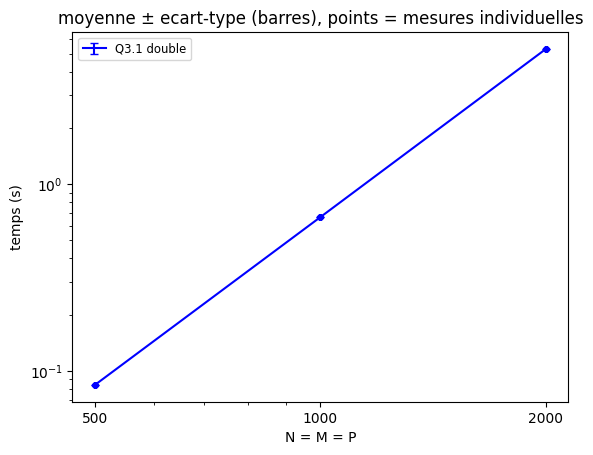

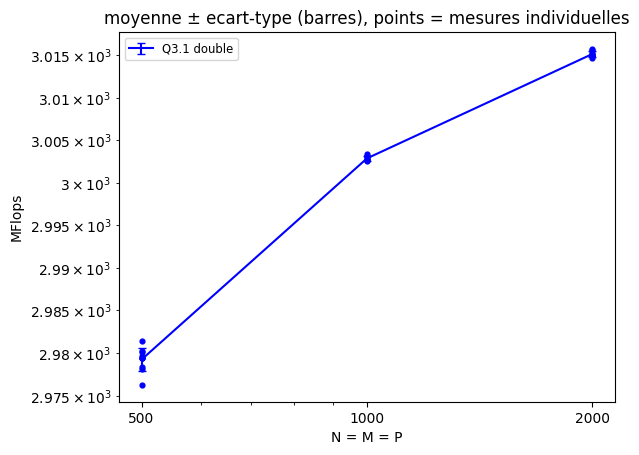

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import warnings
from matplotlib.ticker import NullFormatter
warnings.filterwarnings('ignore')

color_T = {1: "blue", 32: "green", 64: "orange", 128: "red", 256: "black"}
version_linestyle = {"3_1_matrix_mul_cuda": "solid", "3_5_matrix_mul_cuda": "dashed",
                     "3_9_matrix_mul_float": "dotted", "3_13_matrix_mul_half": "dashdot"}
version_nom = {"3_1_matrix_mul_cuda": "Q3.1 double", "3_5_matrix_mul_cuda": "Q3.5 double",
               "3_9_matrix_mul_float": "Q3.9 float", "3_13_matrix_mul_half": "Q3.13 half"}


def courbe_matrices(df, version, T, colonne):
    d = df[(df['version'] == version) & (df['T'] == T)]
    if d.empty:
        return
    moy = d.groupby('N').mean(numeric_only=True).reset_index()
    ecart = d.groupby('N').std(numeric_only=True).reset_index()
    label = version_nom[version] + ("" if T == 1 else f", T = {T}")
    plt.errorbar(moy['N'], moy[colonne], yerr=ecart[colonne].values, capsize=3,
                 linestyle=version_linestyle[version], color=color_T[T], label=label)
    plt.scatter(d['N'], d[colonne], color=color_T[T], s=12)


def figures_matrices(courbes):
    df3 = charger("partie3_matrices")
    for colonne, ylabel, echelle in (("runtime", "temps (s)", "log"), ("mflops", "MFlops", "log")):
        for version, T in courbes:
            courbe_matrices(df3, version, T, colonne)
        plt.xscale('log')
        plt.xticks(tailles_matrices, [str(n) for n in tailles_matrices])
        plt.gca().xaxis.set_minor_formatter(NullFormatter())
        plt.yscale(echelle)
        plt.xlabel('N = M = P')
        plt.ylabel(ylabel)
        plt.title('moyenne ± ecart-type (barres), points = mesures individuelles')
        plt.legend(fontsize='small')
        plt.show()


figures_matrices([("3_1_matrix_mul_cuda", 1)])

### Question 3.4 - Discussion (un thread par bloc)

**Q3.1 (un thread par bloc, double), 10 exécutions par taille**

| N = M = P | temps moyen ± écart-type (s) | MFlops moyens ± écart-type |
|---|---|---|
| 500 | 0.08391 ± 0.00004 | 2979.3 ± 1.4 |
| 1000 | 0.66603 ± 0.00006 | 3002.85 ± 0.26 |
| 2000 | 5.30651 ± 0.00058 | 3015.16 ± 0.33 |

Le temps de la version à un thread par bloc croît comme N^3 : il est multiplié par 7.9 de 500 à 1000 (0.0839 s à 0.666 s) et par 8.0 de 1000 à 2000 (0.666 s à 5.31 s), ce qui correspond à un nombre d'opérations multiplié par 8 à chaque fois. Le débit est presque constant (de 2979 à 3015 MFlops, soit environ 3 GFlops) et les écarts-types sont minuscules (0.0006 s sur 5.31 s à N = 2000). Donc je suppose qu'aucun effet de cache ou de taille n'est visible sur ces trois tailles.

Ce débit de 3 GFlops est très inférieur à ce que la carte peut faire d'après ses spécifications, de l'ordre de 3 TFlops en simple précision et 1/32 de cela en double précision (sans entrer dans le détail de ce calcul). Comme en partie 2, un bloc d'un seul thread n'utilise qu'une voie d'un warp. De plus, à chaque itération, chaque thread lit un élément de A et un élément de B, et ceux de B sont espacés de M éléments en mémoire (une colonne de B), ce qui coûte cher en accès mémoire. Il aurait pu être pertinent de mesurer cet effet séparément mais je ne l'ai pas fait par contrainte de temps.

Par rapport au TP OpenMP : j'y avais mesuré à 1 thread environ 3 s à N = 1000 et 69 s à N = 2000 en double. Le GPU avec un thread par bloc fait 4.5 fois mieux à N = 1000 (0.666 s) et 13 fois mieux à N = 2000 (5.31 s). L'écart augmente avec N, sans doute parce que le CPU perd en efficacité quand les matrices dépassent ses caches, alors que le débit du GPU reste constant.

### Question 3.5 - Plusieurs threads par bloc, mémoire partagée et atomiques

Le bloc (j, i) calcule toujours `C[i][j]`, mais avec `T` threads (argument `-T`) : le thread `t` traite les valeurs de k égales à `t`, `t + T`, `t + 2T`, etc. Chaque thread ajoute sa somme partielle à une variable en mémoire partagée avec `atomicAdd`, puis le thread 0 écrit le total dans `C`. Comme d'habitude, les deux `__syncthreads()` garantissent que le total est initialisé avant les ajouts et complet avant sa lecture.

In [7]:
from pathlib import Path

Path("src/3_5_matrix_mul_cuda.cu").write_text(r"""/*
**  PROGRAM: Matrix Multiply
**
**  PURPOSE: This is a simple matrix multiply program. 
**           It will compute the product
**
**                C  = A * B
**
**           A and B are set to constant matrices so we
**           can make a quick test of the multiplication.
**
**
**  HISTORY: Written by Tim Mattson, Nov 1999.
*            Modified and extended by Jonathan Rouzaud-Cornabas, Oct 2022
*/


#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <chrono>
#include <fstream>
#include <cmath>

#define AVAL 3.14
#define BVAL 5.42
#define TOL  0.001

__global__ void matmul_kernel(const double *A, const double *B, double *C, int M, int P)
{
    __shared__ double total;
    int i = blockIdx.y;
    int j = blockIdx.x;

    if (threadIdx.x == 0) total = 0.0;
    __syncthreads();

    double tmp = 0.0;
    for (int k = threadIdx.x; k < P; k += blockDim.x)
        tmp += A[(long long)i * P + k] * B[(long long)k * M + j];

    atomicAdd(&total, tmp);
    __syncthreads();

    if (threadIdx.x == 0) C[(long long)i * M + j] = total;
}

int main(int argc, char **argv)
{
    int Ndim = 1000, Pdim = 1000, Mdim = 1000;   /* A[N][P], B[P][M], C[N][M] */
    int nthreads = 128;                          // threads par bloc
	int i,j;
	double *A, *B, *C;
	double cval, err, errsq;
    double dN, dM, dP, mflops;

    // Read command line arguments.
      for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 )) {
            Ndim = atoi( argv[ ++i ] );
            printf( "  User N is %d\n", Ndim );
        } else if ( ( strcmp( argv[ i ], "-M" ) == 0 )) {
            Mdim = atoi( argv[ ++i ] );
            printf( "  User M is %d\n", Mdim );
        } else if ( ( strcmp( argv[ i ], "-P" ) == 0 )) {
            Pdim = atoi( argv[ ++i ] );
            printf( "  User P is %d\n", Pdim );
        } else if ( ( strcmp( argv[ i ], "-T" ) == 0 )) {
            nthreads = atoi( argv[ ++i ] );
            printf( "  User nthreads is %d\n", nthreads );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Matrix multiplication Options:\n" );
            printf( "  -N <int>:              Size of the dimension N (by default 1000)\n" );
            printf( "  -M <int>:              Size of the dimension M (by default 1000)\n" );
            printf( "  -P <int>:              Size of the dimension P (by default 1000)\n" );
            printf( "  -T <int>:              Number of threads per block (by default 128)\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
      }


      A = (double *)malloc((size_t)Ndim*Pdim*sizeof(double));
      B = (double *)malloc((size_t)Pdim*Mdim*sizeof(double));
      C = (double *)malloc((size_t)Ndim*Mdim*sizeof(double));

	/* Initialize matrices */

	for (i=0; i<Ndim; i++)
		for (j=0; j<Pdim; j++)
			*(A+((size_t)i*Pdim+j)) = AVAL;

	for (i=0; i<Pdim; i++)
		for (j=0; j<Mdim; j++)
			*(B+((size_t)i*Mdim+j)) = BVAL;

	for (i=0; i<Ndim; i++)
		for (j=0; j<Mdim; j++)
			*(C+((size_t)i*Mdim+j)) = 0.0;

	/* Do the matrix product */

    double *d_A, *d_B, *d_C;
    if (cudaMalloc(&d_A, (size_t)Ndim * Pdim * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
    if (cudaMalloc(&d_B, (size_t)Pdim * Mdim * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
    if (cudaMalloc(&d_C, (size_t)Ndim * Mdim * sizeof(double)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
    cudaMemcpy(d_A, A, (size_t)Ndim * Pdim * sizeof(double), cudaMemcpyHostToDevice);
    cudaMemcpy(d_B, B, (size_t)Pdim * Mdim * sizeof(double), cudaMemcpyHostToDevice);

    dim3 grille(Mdim, Ndim);

    // Timer products.
    auto begin = std::chrono::high_resolution_clock::now();

    matmul_kernel<<<grille, nthreads>>>(d_A, d_B, d_C, Mdim, Pdim);
    cudaError_t erreur = cudaGetLastError();
    if (erreur != cudaSuccess) { printf("Erreur CUDA : %s\n", cudaGetErrorString(erreur)); return 4; }
    cudaDeviceSynchronize();

    auto end = std::chrono::high_resolution_clock::now();
    double time = std::chrono::duration<double>(end - begin).count();

    cudaMemcpy(C, d_C, (size_t)Ndim * Mdim * sizeof(double), cudaMemcpyDeviceToHost);

	printf(" N %d M %d P %d multiplication in %f seconds \n", Ndim, Mdim, Pdim, time);

      dN = (double)Ndim;
      dM = (double)Mdim;
      dP = (double)Pdim;
      mflops = 2.0 * dN * dM * dP / (1000000.0 * time);

	printf(" N %d M %d P %d multiplication at %f mflops\n", Ndim, Mdim, Pdim, mflops);
	std::ofstream("stats_cuda_matrices.csv", std::ios::app) << "3_5_matrix_mul_cuda," << nthreads << "," << Ndim << "," << Mdim << "," << Pdim << "," << time << "," << mflops << "\n";

	cval = (double)Pdim * 3.14 * 5.42;
	errsq = 0.0;
	for (i=0; i<Ndim; i++){
		for (j=0; j<Mdim; j++){
			err = (double)*(C+(size_t)i*Mdim+j) - cval;
		    errsq += err * err;
		}
	}

	if (errsq > TOL)
		printf("\n Errors in multiplication: %f",errsq);
	else
		printf("\n Hey, it worked");

	cudaFree(d_A); cudaFree(d_B); cudaFree(d_C);
	free(A); free(B); free(C);

	printf("\n all done \n");
}
""", encoding="utf8")

5240

In [9]:
!.\build.bat src\3_5_matrix_mul_cuda.cu

3_5_matrix_mul_cuda.cu


In [24]:
!.\bin\3_5_matrix_mul_cuda.exe -N 500 -M 500 -P 500 -T 32

  User N is 500
  User M is 500
  User P is 500
  User nthreads is 32
 N 500 M 500 P 500 multiplication in 0.014838 seconds 
 N 500 M 500 P 500 multiplication at 16848.972550 mflops

 Hey, it worked
 all done 


### Question 3.6 - Évaluation de performance (plusieurs threads par bloc)

Mêmes tailles qu'en 3.2, avec T = 32, 64, 128 et 256 threads par bloc et 10 répétitions. Les résultats s'ajoutent à la feuille `partie3_matrices` du classeur (elle n'est pas effacée ici).

In [ ]:
nettoyer_csv("partie3_matrices")
mesurer_matrices("3_5_matrix_mul_cuda", T_matrices, avec_T=True)

### Question 3.7 - Figures de performance (plusieurs threads par bloc)

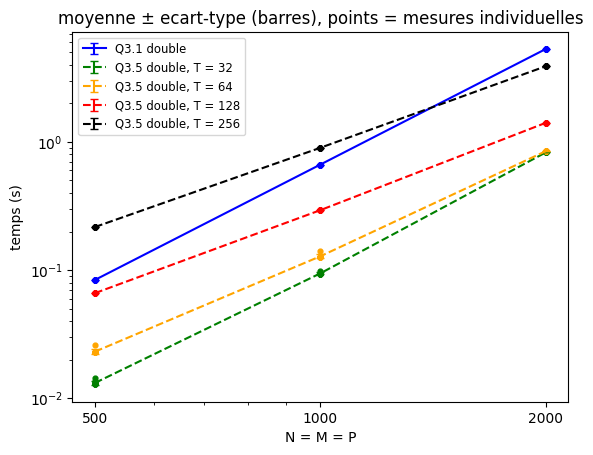

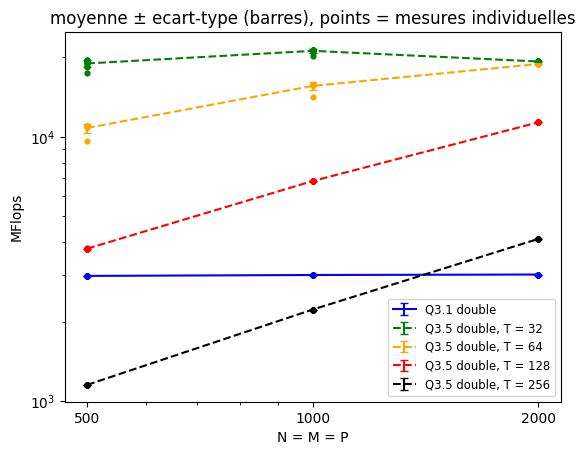

In [4]:
figures_matrices([("3_1_matrix_mul_cuda", 1)] + [("3_5_matrix_mul_cuda", T) for T in T_matrices])

### Question 3.8 - Discussion (plusieurs threads par bloc)

**Q3.5 (double), temps en secondes, 10 exécutions par configuration**

| threads par bloc | N = 500 | N = 1000 | N = 2000 |
|---|---|---|---|
| 32 | 0.01319 ± 0.00046 | 0.0945 ± 0.0017 | 0.82893 ± 0.00052 |
| 64 | 0.0231 ± 0.0010 | 0.1283 ± 0.0044 | 0.84735 ± 0.00017 |
| 128 | 0.06616 ± 0.00007 | 0.29372 ± 0.00010 | 1.40943 ± 0.00011 |
| 256 | 0.21686 ± 0.00007 | 0.90014 ± 0.00024 | 3.89236 ± 0.00029 |

Passer à plusieurs threads par bloc apporte un gain, mais seulement pour les petites valeurs de T. Avec T = 32, la Q3.5 est 6.4 fois plus rapide que la Q3.1 à N = 2000 (0.829 s contre 5.31 s) et 7.0 fois plus rapide à N = 1000 (0.0945 s contre 0.666 s), soit environ 19 GFlops à N = 2000. Ensuite le temps augmente avec T. À N = 2000, il passe de 0.829 s à T = 32 à 3.89 s à T = 256, et c'est encore plus net pour les petites matrices (de 0.0132 s à 0.217 s à N = 500, soit 16 fois plus). À T = 256 et N = 2000, la Q3.5 reste quand même 1.4 fois plus rapide que la Q3.1.

Comme en partie 2, je pense que la cause est la contention sur les additions atomiques. Chaque bloc fait T additions atomiques en mémoire partagée sur la même variable, soit N x M x T = 1.0 x 10^9 additions à N = 2000 et T = 256, et l'addition atomique d'un double en mémoire partagée est probablement émulée par une boucle de comparaison et d'échange. À T = 256 et N = 500, chaque thread ne fait qu'environ 2 itérations de la boucle sur k (500 / 256), donc les additions atomiques dominent le calcul. À T = 32 et T = 64, les temps sont presque identiques à N = 2000 (0.829 s et 0.847 s), et T = 32 est meilleur aux petites tailles. On aurait pu vérifier en mesurant séparément la part des additions atomiques.

Les écarts-types sont très faibles à N = 2000 (moins de 0.1 % du temps) et atteignent 2 à 4 % à N = 500 et N = 1000 pour T = 32 et T = 64.

### Question 3.9 - Passage de `double` à `float`

Les matrices, le kernel et la variable partagée passent en `float`. L'`atomicAdd` sur un `float` existe en matériel, contrairement à celui sur un `double` en mémoire partagée. Comme dans la version OpenMP en `float`, la vérification se fait par erreur relative (seuil 0.001) et non par la somme des carrés des écarts.

In [10]:
from pathlib import Path

Path("src/3_9_matrix_mul_float.cu").write_text(r"""/*
**  PROGRAM: Matrix Multiply
**
**  PURPOSE: This is a simple matrix multiply program. 
**           It will compute the product
**
**                C  = A * B
**
**           A and B are set to constant matrices so we
**           can make a quick test of the multiplication.
**
**
**  HISTORY: Written by Tim Mattson, Nov 1999.
*            Modified and extended by Jonathan Rouzaud-Cornabas, Oct 2022
*/


#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <chrono>
#include <fstream>
#include <cmath>

#define AVAL 3.14f
#define BVAL 5.42f
#define TOL  0.001

__global__ void matmul_kernel(const float *A, const float *B, float *C, int M, int P)
{
    __shared__ float total;
    int i = blockIdx.y;
    int j = blockIdx.x;

    if (threadIdx.x == 0) total = 0.0f;
    __syncthreads();

    float tmp = 0.0f;
    for (int k = threadIdx.x; k < P; k += blockDim.x)
        tmp += A[(long long)i * P + k] * B[(long long)k * M + j];

    atomicAdd(&total, tmp);
    __syncthreads();

    if (threadIdx.x == 0) C[(long long)i * M + j] = total;
}

int main(int argc, char **argv)
{
    int Ndim = 1000, Pdim = 1000, Mdim = 1000;   /* A[N][P], B[P][M], C[N][M] */
    int nthreads = 128;                          // threads par bloc
	int i,j;
	float *A, *B, *C;
	double cval, err, maxrel;
    double dN, dM, dP, mflops;

    // Read command line arguments.
      for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 )) {
            Ndim = atoi( argv[ ++i ] );
            printf( "  User N is %d\n", Ndim );
        } else if ( ( strcmp( argv[ i ], "-M" ) == 0 )) {
            Mdim = atoi( argv[ ++i ] );
            printf( "  User M is %d\n", Mdim );
        } else if ( ( strcmp( argv[ i ], "-P" ) == 0 )) {
            Pdim = atoi( argv[ ++i ] );
            printf( "  User P is %d\n", Pdim );
        } else if ( ( strcmp( argv[ i ], "-T" ) == 0 )) {
            nthreads = atoi( argv[ ++i ] );
            printf( "  User nthreads is %d\n", nthreads );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Matrix multiplication Options:\n" );
            printf( "  -N <int>:              Size of the dimension N (by default 1000)\n" );
            printf( "  -M <int>:              Size of the dimension M (by default 1000)\n" );
            printf( "  -P <int>:              Size of the dimension P (by default 1000)\n" );
            printf( "  -T <int>:              Number of threads per block (by default 128)\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
      }


      A = (float *)malloc((size_t)Ndim*Pdim*sizeof(float));
      B = (float *)malloc((size_t)Pdim*Mdim*sizeof(float));
      C = (float *)malloc((size_t)Ndim*Mdim*sizeof(float));

	/* Initialize matrices */

	for (i=0; i<Ndim; i++)
		for (j=0; j<Pdim; j++)
			*(A+((size_t)i*Pdim+j)) = AVAL;

	for (i=0; i<Pdim; i++)
		for (j=0; j<Mdim; j++)
			*(B+((size_t)i*Mdim+j)) = BVAL;

	for (i=0; i<Ndim; i++)
		for (j=0; j<Mdim; j++)
			*(C+((size_t)i*Mdim+j)) = 0.0f;

	/* Do the matrix product */

    float *d_A, *d_B, *d_C;
    if (cudaMalloc(&d_A, (size_t)Ndim * Pdim * sizeof(float)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
    if (cudaMalloc(&d_B, (size_t)Pdim * Mdim * sizeof(float)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
    if (cudaMalloc(&d_C, (size_t)Ndim * Mdim * sizeof(float)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
    cudaMemcpy(d_A, A, (size_t)Ndim * Pdim * sizeof(float), cudaMemcpyHostToDevice);
    cudaMemcpy(d_B, B, (size_t)Pdim * Mdim * sizeof(float), cudaMemcpyHostToDevice);

    dim3 grille(Mdim, Ndim);

    // Timer products.
    auto begin = std::chrono::high_resolution_clock::now();

    matmul_kernel<<<grille, nthreads>>>(d_A, d_B, d_C, Mdim, Pdim);
    cudaError_t erreur = cudaGetLastError();
    if (erreur != cudaSuccess) { printf("Erreur CUDA : %s\n", cudaGetErrorString(erreur)); return 4; }
    cudaDeviceSynchronize();

    auto end = std::chrono::high_resolution_clock::now();
    double time = std::chrono::duration<double>(end - begin).count();

    cudaMemcpy(C, d_C, (size_t)Ndim * Mdim * sizeof(float), cudaMemcpyDeviceToHost);

	printf(" N %d M %d P %d multiplication in %f seconds \n", Ndim, Mdim, Pdim, time);

      dN = (double)Ndim;
      dM = (double)Mdim;
      dP = (double)Pdim;
      mflops = 2.0 * dN * dM * dP / (1000000.0 * time);

	printf(" N %d M %d P %d multiplication at %f mflops\n", Ndim, Mdim, Pdim, mflops);
	std::ofstream("stats_cuda_matrices.csv", std::ios::app) << "3_9_matrix_mul_float," << nthreads << "," << Ndim << "," << Mdim << "," << Pdim << "," << time << "," << mflops << "\n";

	cval = (double)Pdim * 3.14 * 5.42;
	maxrel = 0.0;
	for (i=0; i<Ndim; i++){
		for (j=0; j<Mdim; j++){
			err = fabs( (double)*(C+(size_t)i*Mdim+j) - cval ) / cval;
			if (err > maxrel) maxrel = err;
		}
	}

	if (maxrel > TOL)
		printf("\n Errors in multiplication");
	else
		printf("\n Hey, it worked");

	cudaFree(d_A); cudaFree(d_B); cudaFree(d_C);
	free(A); free(B); free(C);

	printf("\n all done \n");
}
""", encoding="utf8")

5244

In [10]:
!.\build.bat src\3_9_matrix_mul_float.cu

3_9_matrix_mul_float.cu


In [26]:
!.\bin\3_9_matrix_mul_float.exe -N 500 -M 500 -P 500 -T 32

  User N is 500
  User M is 500
  User P is 500
  User nthreads is 32
 N 500 M 500 P 500 multiplication in 0.010559 seconds 
 N 500 M 500 P 500 multiplication at 23677.381471 mflops

 Hey, it worked
 all done 


### Question 3.10 - Évaluation de performance (float)

Mêmes tailles et mêmes nombres de threads par bloc qu'en 3.6, avec 10 répétitions. Les résultats s'ajoutent à la feuille `partie3_matrices` du classeur (elle n'est pas effacée ici).

In [ ]:
nettoyer_csv("partie3_matrices")
mesurer_matrices("3_9_matrix_mul_float", T_matrices, avec_T=True)

### Question 3.11 - Figures de performance (float)

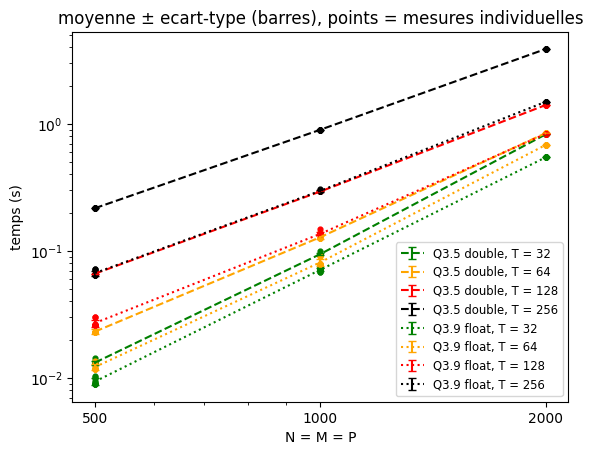

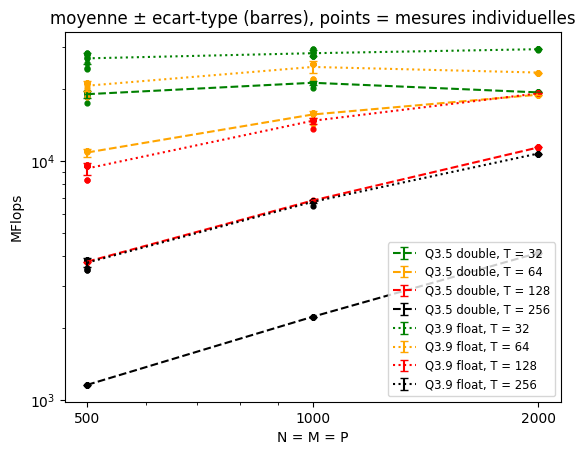

In [5]:
figures_matrices([("3_5_matrix_mul_cuda", T) for T in T_matrices] + [("3_9_matrix_mul_float", T) for T in T_matrices])

### Question 3.12 - Discussion (float)

**Q3.9 (float), temps en secondes, 10 exécutions par configuration**

| threads par bloc | N = 500 | N = 1000 | N = 2000 |
|---|---|---|---|
| 32 | 0.00936 ± 0.00056 | 0.0711 ± 0.0019 | 0.5467 ± 0.0014 |
| 64 | 0.01217 ± 0.00060 | 0.0814 ± 0.0052 | 0.68465 ± 0.00016 |
| 128 | 0.0270 ± 0.0017 | 0.1363 ± 0.0041 | 0.83680 ± 0.00018 |
| 256 | 0.0669 ± 0.0030 | 0.2974 ± 0.0042 | 1.49446 ± 0.00013 |

**Rapport du temps double (Q3.5) / float (Q3.9)**

| threads par bloc | N = 500 | N = 1000 | N = 2000 |
|---|---|---|---|
| 32 | 1.41 | 1.33 | 1.52 |
| 64 | 1.90 | 1.58 | 1.24 |
| 128 | 2.45 | 2.15 | 1.68 |
| 256 | 3.24 | 3.03 | 2.60 |

Le passage en float accélère toutes les configurations. Avec T = 32, le temps passe de 0.829 s en double à 0.547 s à N = 2000, soit 1.52 fois moins, et le rapport double sur float va de 1.24 à 3.24 selon T et N. Le gain est le plus fort à grand T : 2.60 fois à T = 256 et N = 2000, et 3.24 fois à N = 500. 
2 hypothèses : 
- Les matrices en float occupent deux fois moins de mémoire, donc il y a deux fois moins de données à lire. 
- L'addition atomique d'un float existe en matériel, contrairement à celle d'un double en mémoire partagée, ce qui réduit le coût de la contention quand T est grand.

Le gain plus fort à T = 256 qu'à T = 32 va dans le sens de la seconde, mais je n'ai pas séparé les deux.

Le meilleur débit en float est de 29.3 GFlops (T = 32, N = 2000), très en dessous des environ 3 TFlops de la carte en simple précision. Le kernel lit B colonne par colonne sans réutilisation en mémoire partagée, donc il est probablement limité par les accès mémoire et par les additions atomiques. Comme en double, T = 32 est la meilleure valeur et le temps augmente avec T (de 0.547 s à 1.494 s à N = 2000), mais moins vite qu'en double (facteur 2.7 contre 4.7).

### Question 3.13 - Passage de `double` à `half`

L'énoncé propose d'inclure `half.hpp` et d'utiliser `half_float::half`. Cette bibliothèque ne fonctionne que sur le processeur : ses opérations ne sont pas utilisables dans un kernel CUDA. J'utilise donc le type `__half` de CUDA (`cuda_fp16.h`), qui joue le même rôle sur le GPU. Les matrices `A`, `B` et `C`, la variable partagée et la somme partielle de chaque thread sont en `__half`, comme dans la version OpenMP en `half`, avec les opérations `__hmul` et `__hadd`. La vérification se fait par erreur relative avec un seuil de 0.05, comme au TP OpenMP.

Un `half` ne dépasse pas 65504. Chaque élément du produit vaut environ 17 x P, donc le résultat déborde dès que P dépasse environ 3850 : pour N = M = P = 4000, le programme affiche « Errors in multiplication ». Les tailles de 500 à 2000 restent en dessous de cette limite.

In [13]:
from pathlib import Path

Path("src/3_13_matrix_mul_half.cu").write_text(r"""/*
**  PROGRAM: Matrix Multiply
**
**  PURPOSE: This is a simple matrix multiply program. 
**           It will compute the product
**
**                C  = A * B
**
**           A and B are set to constant matrices so we
**           can make a quick test of the multiplication.
**
**
**  HISTORY: Written by Tim Mattson, Nov 1999.
*            Modified and extended by Jonathan Rouzaud-Cornabas, Oct 2022
*/


#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <chrono>
#include <fstream>
#include <cmath>
#include <cuda_fp16.h>

#define AVAL 3.14f
#define BVAL 5.42f
#define TOL  0.05

__global__ void matmul_kernel(const __half *A, const __half *B, __half *C, int M, int P)
{
    __shared__ __half total;
    int i = blockIdx.y;
    int j = blockIdx.x;

    if (threadIdx.x == 0) total = __float2half(0.0f);
    __syncthreads();

    __half tmp = __float2half(0.0f);
    for (int k = threadIdx.x; k < P; k += blockDim.x)
        tmp = __hadd(tmp, __hmul(A[(long long)i * P + k], B[(long long)k * M + j]));

    atomicAdd(&total, tmp);
    __syncthreads();

    if (threadIdx.x == 0) C[(long long)i * M + j] = total;
}

int main(int argc, char **argv)
{
    int Ndim = 1000, Pdim = 1000, Mdim = 1000;   /* A[N][P], B[P][M], C[N][M] */
    int nthreads = 128;                          // threads par bloc
	int i,j;
	__half *A, *B, *C;
	double cval, err, maxrel;
    double dN, dM, dP, mflops;

    // Read command line arguments.
      for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 )) {
            Ndim = atoi( argv[ ++i ] );
            printf( "  User N is %d\n", Ndim );
        } else if ( ( strcmp( argv[ i ], "-M" ) == 0 )) {
            Mdim = atoi( argv[ ++i ] );
            printf( "  User M is %d\n", Mdim );
        } else if ( ( strcmp( argv[ i ], "-P" ) == 0 )) {
            Pdim = atoi( argv[ ++i ] );
            printf( "  User P is %d\n", Pdim );
        } else if ( ( strcmp( argv[ i ], "-T" ) == 0 )) {
            nthreads = atoi( argv[ ++i ] );
            printf( "  User nthreads is %d\n", nthreads );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Matrix multiplication Options:\n" );
            printf( "  -N <int>:              Size of the dimension N (by default 1000)\n" );
            printf( "  -M <int>:              Size of the dimension M (by default 1000)\n" );
            printf( "  -P <int>:              Size of the dimension P (by default 1000)\n" );
            printf( "  -T <int>:              Number of threads per block (by default 128)\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
      }


      A = (__half *)malloc((size_t)Ndim*Pdim*sizeof(__half));
      B = (__half *)malloc((size_t)Pdim*Mdim*sizeof(__half));
      C = (__half *)malloc((size_t)Ndim*Mdim*sizeof(__half));

	/* Initialize matrices */

	for (i=0; i<Ndim; i++)
		for (j=0; j<Pdim; j++)
			*(A+((size_t)i*Pdim+j)) = __float2half(AVAL);

	for (i=0; i<Pdim; i++)
		for (j=0; j<Mdim; j++)
			*(B+((size_t)i*Mdim+j)) = __float2half(BVAL);

	for (i=0; i<Ndim; i++)
		for (j=0; j<Mdim; j++)
			*(C+((size_t)i*Mdim+j)) = __float2half(0.0f);

	/* Do the matrix product */

    __half *d_A, *d_B, *d_C;
    if (cudaMalloc(&d_A, (size_t)Ndim * Pdim * sizeof(__half)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
    if (cudaMalloc(&d_B, (size_t)Pdim * Mdim * sizeof(__half)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
    if (cudaMalloc(&d_C, (size_t)Ndim * Mdim * sizeof(__half)) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
    cudaMemcpy(d_A, A, (size_t)Ndim * Pdim * sizeof(__half), cudaMemcpyHostToDevice);
    cudaMemcpy(d_B, B, (size_t)Pdim * Mdim * sizeof(__half), cudaMemcpyHostToDevice);

    dim3 grille(Mdim, Ndim);

    // Timer products.
    auto begin = std::chrono::high_resolution_clock::now();

    matmul_kernel<<<grille, nthreads>>>(d_A, d_B, d_C, Mdim, Pdim);
    cudaError_t erreur = cudaGetLastError();
    if (erreur != cudaSuccess) { printf("Erreur CUDA : %s\n", cudaGetErrorString(erreur)); return 4; }
    cudaDeviceSynchronize();

    auto end = std::chrono::high_resolution_clock::now();
    double time = std::chrono::duration<double>(end - begin).count();

    cudaMemcpy(C, d_C, (size_t)Ndim * Mdim * sizeof(__half), cudaMemcpyDeviceToHost);

	printf(" N %d M %d P %d multiplication in %f seconds \n", Ndim, Mdim, Pdim, time);

      dN = (double)Ndim;
      dM = (double)Mdim;
      dP = (double)Pdim;
      mflops = 2.0 * dN * dM * dP / (1000000.0 * time);

	printf(" N %d M %d P %d multiplication at %f mflops\n", Ndim, Mdim, Pdim, mflops);
	std::ofstream("stats_cuda_matrices.csv", std::ios::app) << "3_13_matrix_mul_half," << nthreads << "," << Ndim << "," << Mdim << "," << Pdim << "," << time << "," << mflops << "\n";

	cval = (double)Pdim * 3.14 * 5.42;
	maxrel = 0.0;
	for (i=0; i<Ndim; i++){
		for (j=0; j<Mdim; j++){
			err = fabs( (double)__half2float(*(C+(size_t)i*Mdim+j)) - cval ) / cval;
			if (err > maxrel) maxrel = err;
		}
	}

	if (maxrel > TOL)
		printf("\n Errors in multiplication");
	else
		printf("\n Hey, it worked");

	cudaFree(d_A); cudaFree(d_B); cudaFree(d_C);
	free(A); free(B); free(C);

	printf("\n all done \n");
}
""", encoding="utf8")

5388

In [11]:
!.\build.bat src\3_13_matrix_mul_half.cu

3_13_matrix_mul_half.cu


In [28]:
!.\bin\3_13_matrix_mul_half.exe -N 500 -M 500 -P 500 -T 32

  User N is 500
  User M is 500
  User P is 500
  User nthreads is 32
 N 500 M 500 P 500 multiplication in 0.030656 seconds 
 N 500 M 500 P 500 multiplication at 8155.090244 mflops

 Hey, it worked
 all done 


### Question 3.14 - Évaluation de performance (half)

Mêmes tailles et mêmes nombres de threads par bloc qu'en 3.6 et 3.10, avec 10 répétitions. Les résultats s'ajoutent à la feuille `partie3_matrices` du classeur (elle n'est pas effacée ici).

In [ ]:
nettoyer_csv("partie3_matrices")
mesurer_matrices("3_13_matrix_mul_half", T_matrices, avec_T=True)

### Question 3.15 - Figures de performance (half)

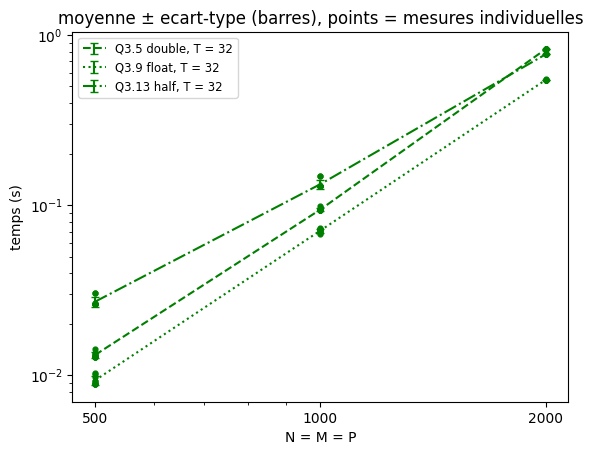

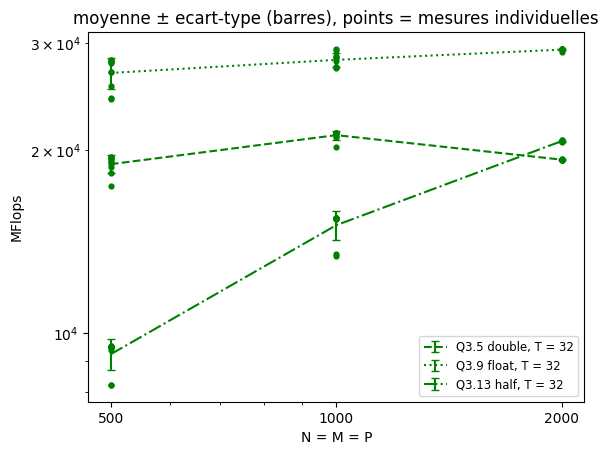

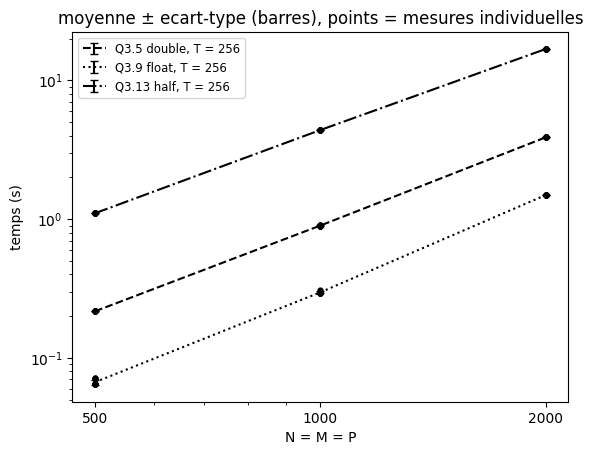

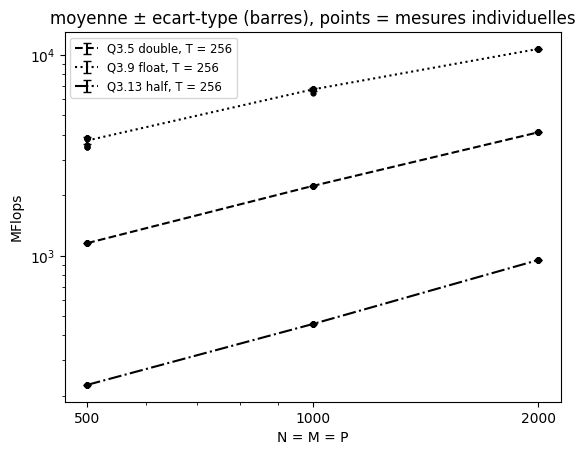

In [6]:
figures_matrices([("3_5_matrix_mul_cuda", 32), ("3_9_matrix_mul_float", 32), ("3_13_matrix_mul_half", 32)])
figures_matrices([("3_5_matrix_mul_cuda", 256), ("3_9_matrix_mul_float", 256), ("3_13_matrix_mul_half", 256)])

### Question 3.16 - Discussion (half)

**Q3.13 (half), temps en secondes, 10 exécutions par configuration**

| threads par bloc | N = 500 | N = 1000 | N = 2000 |
|---|---|---|---|
| 32 | 0.0271 ± 0.0017 | 0.1332 ± 0.0081 | 0.7728 ± 0.0012 |
| 64 | 0.0749 ± 0.0047 | 0.3045 ± 0.0012 | 1.34947 ± 0.00041 |
| 128 | 0.27774 ± 0.00039 | 1.11978 ± 0.00026 | 4.55900 ± 0.00035 |
| 256 | 1.10327 ± 0.00021 | 4.39104 ± 0.00023 | 16.85678 ± 0.00095 |

**Rapport du temps half (Q3.13) / float (Q3.9)**

| threads par bloc | N = 500 | N = 1000 | N = 2000 |
|---|---|---|---|
| 32 | 2.90 | 1.87 | 1.41 |
| 64 | 6.16 | 3.74 | 1.97 |
| 128 | 10.27 | 8.21 | 5.45 |
| 256 | 16.49 | 14.77 | 11.28 |

Le half n'apporte aucun gain de vitesse ici, alors qu'on pourrait l'attendre d'un type deux fois plus petit que le float. Avec T = 32, il est 1.41 fois plus lent que le float à N = 2000 (0.773 s contre 0.547 s) et 2.90 fois plus lent à N = 500, et l'écart explose avec T : à T = 256, il est 11.3 fois plus lent à N = 2000 (16.86 s contre 1.49 s) et 16.5 fois plus lent à N = 500. Par rapport au double, il est à peine plus rapide à T = 32 (0.773 s contre 0.829 s à N = 2000) et beaucoup plus lent dès T = 128 (4.56 s contre 1.41 s).

Je vois deux raisons possibles, que je n'ai pas vérifiées. 
D'abord, d'après mes questions à une LLM, les paires de half traitées ensemble profitent d'un débit doublé offert par la carte (`half2`). Mais cet avantage ne sera donc pas présent pour les opérations sur un half isolé (`__hmul` et `__hadd`). 
Ensuite, l'addition atomique d'un half en mémoire partagée doit sûrement encore être émulée par une boucle de comparaison et d'échange, plus coûteuse encore que celle du double, ce qui expliquerait l'effondrement pour un grand T. L'écart avec le float est plus fort sur les petites matrices (16.5 fois à N = 500 contre 11.3 fois à N = 2000). Ça va dans le sens d'un coût fixe par bloc (les additions atomiques) qui pèse plus quand le calcul est court.

Le half est aussi limité en précision et en amplitude. Un élément du produit vaut environ 17 x P et un half ne dépasse pas 65504, donc le résultat déborde pour P supérieur à environ 3850 (j'ai observé « Errors in multiplication » à N = 4000). Aux tailles mesurées, qui vont jusqu'à 2000 (éléments d'environ 34 000), la vérification par erreur relative avec un seuil de 5 % a réussi dans mes essais (N = 500 avec T = 1, 32, 128 et 256, puis N = 1000 et 2000 avec T = 32). 

En conclusion, pour cette application, je choisirais le float : plus rapide que le double et sans les limites du half.

## 4. Chaining Matrix Multiplication

### Question 4.1 - Implémentation parallèle du workflow

Le graphe est le même que celui du TP OpenMP : 4 produits indépendants (AB, CD, EF, GH), puis 2 produits (ABCD et EFGH), puis le produit final, soit 7 produits sur 3 niveaux. Chaque produit réutilise le kernel de la question 3.5 (plusieurs threads par bloc, mémoire partagée et `atomicAdd`), lancé dans un stream CUDA. Les produits d'un même niveau sont répartis sur les streams disponibles (`flux[k % nstreams]`), et ils peuvent donc s'exécuter en même temps. Pour qu'un produit n'attende que les deux résultats dont il dépend, chaque produit enregistre un événement (`cudaEventRecord`) à sa fin, et le stream du produit suivant l'attend avec `cudaStreamWaitEvent`, sans bloquer le CPU.

Le nombre de streams est un argument (`-S`). Avec `-S 1`, les 7 produits passent dans le même stream et s'exécutent l'un après l'autre : c'est la référence séquentielle, avec exactement le même code que la version à plusieurs streams. Les 8 matrices d'entrée valent `AVAL`, donc chaque case du résultat vaut N^7 x AVAL^8, et la vérification porte sur l'erreur relative maximale (seuil 1e-9), comme dans la version OpenMP. Le temps comprend le lancement des 7 produits et l'attente de la fin du dernier (`cudaDeviceSynchronize`), mais pas les copies vers et depuis le GPU. Les MFlops sont calculés avec 7 x 2 x N^3 opérations.

In [ ]:
from pathlib import Path

Path("src/4_1_matrix_chain_cuda.cu").write_text(r"""/*
**  PROGRAM: Matrix Multiply
**
**  PURPOSE: This is a simple matrix multiply program. 
**           It will compute the product
**
**                C  = A * B
**
**           A and B are set to constant matrices so we
**           can make a quick test of the multiplication.
**
**
**  HISTORY: Written by Tim Mattson, Nov 1999.
*            Modified and extended by Jonathan Rouzaud-Cornabas, Oct 2022
*/


#include <limits>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <chrono>
#include <fstream>
#include <cmath>

#define AVAL 3.14
#define BVAL 5.42
#define TOL  1e-9

__global__ void matmul_kernel(const double *A, const double *B, double *C, int M, int P)
{
    __shared__ double total;
    int i = blockIdx.y;
    int j = blockIdx.x;

    if (threadIdx.x == 0) total = 0.0;
    __syncthreads();

    double tmp = 0.0;
    for (int k = threadIdx.x; k < P; k += blockDim.x)
        tmp += A[(long long)i * P + k] * B[(long long)k * M + j];

    atomicAdd(&total, tmp);
    __syncthreads();

    if (threadIdx.x == 0) C[(long long)i * M + j] = total;
}

void produit(const double *A, const double *B, double *C, int N, int M, int P, int T, cudaStream_t flux)
{
    dim3 grille(M, N);
    matmul_kernel<<<grille, T, 0, flux>>>(A, B, C, M, P);
}

int main(int argc, char **argv)
{
    int Ndim = 1000, Pdim = 1000, Mdim = 1000;   /* A[N][P], B[P][M], C[N][M] */
    int nthreads = 32;                           // threads par bloc : meilleur valeur d'apres mesures partie 3
    int nstreams = 4;
	int i,j;
	double *h_A;
	double *d_in[8], *d_AB, *d_CD, *d_EF, *d_GH, *d_ABCD, *d_EFGH, *d_R, *h_R;
	double cval, err, maxrel;
    double dN, dM, dP, mflops;

    // Read command line arguments.
      for ( int i = 0; i < argc; i++ ) {
        if ( ( strcmp( argv[ i ], "-N" ) == 0 )) {
            Ndim = atoi( argv[ ++i ] );
            printf( "  User N is %d\n", Ndim );
        } else if ( ( strcmp( argv[ i ], "-M" ) == 0 )) {
            Mdim = atoi( argv[ ++i ] );
            printf( "  User M is %d\n", Mdim );
        } else if ( ( strcmp( argv[ i ], "-P" ) == 0 )) {
            Pdim = atoi( argv[ ++i ] );
            printf( "  User P is %d\n", Pdim );
        } else if ( ( strcmp( argv[ i ], "-T" ) == 0 )) {
            nthreads = atoi( argv[ ++i ] );
            printf( "  User nthreads is %d\n", nthreads );
        } else if ( ( strcmp( argv[ i ], "-S" ) == 0 )) {
            nstreams = atoi( argv[ ++i ] );
            printf( "  User nstreams is %d\n", nstreams );
        } else if ( ( strcmp( argv[ i ], "-h" ) == 0 ) || ( strcmp( argv[ i ], "-help" ) == 0 ) ) {
            printf( "  Matrix multiplication Options:\n" );
            printf( "  -N <int>:              Size of the dimension N (by default 1000)\n" );
            printf( "  -M <int>:              Size of the dimension M (by default 1000)\n" );
            printf( "  -P <int>:              Size of the dimension P (by default 1000)\n" );
            printf( "  -T <int>:              Number of threads per block (by default 32)\n" );
            printf( "  -S <int>:              Number of streams (by default 4)\n" );
            printf( "  -help (-h):            print this message\n\n" );
            exit( 1 );
        }
      }

    size_t octets = (size_t)Ndim * Ndim * sizeof(double);

    h_A = (double *)malloc(octets);
    h_R = (double *)malloc(octets);
    for (size_t x = 0; x < (size_t)Ndim * Ndim; x++)
        h_A[x] = AVAL;

    double **tous[] = { &d_AB, &d_CD, &d_EF, &d_GH, &d_ABCD, &d_EFGH, &d_R };
    for (int m = 0; m < 8; m++) {
        if (cudaMalloc(&d_in[m], octets) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }
        cudaMemcpy(d_in[m], h_A, octets, cudaMemcpyHostToDevice);
    }
    for (int m = 0; m < 7; m++)
        if (cudaMalloc(tous[m], octets) != cudaSuccess) { printf("Erreur : memoire insuffisante\n"); return 3; }

    cudaStream_t flux[4];
    for (int s = 0; s < nstreams; s++) cudaStreamCreate(&flux[s]);
    cudaEvent_t fini[6];                         // AB, CD, EF, GH, ABCD, EFGH
    for (int e = 0; e < 6; e++) cudaEventCreateWithFlags(&fini[e], cudaEventDisableTiming);

    // Timer products.
    auto begin = std::chrono::high_resolution_clock::now();

    // 4 produits independants
    produit(d_in[0], d_in[1], d_AB, Ndim, Mdim, Pdim, nthreads, flux[0 % nstreams]);
    cudaEventRecord(fini[0], flux[0 % nstreams]);
    produit(d_in[2], d_in[3], d_CD, Ndim, Mdim, Pdim, nthreads, flux[1 % nstreams]);
    cudaEventRecord(fini[1], flux[1 % nstreams]);
    produit(d_in[4], d_in[5], d_EF, Ndim, Mdim, Pdim, nthreads, flux[2 % nstreams]);
    cudaEventRecord(fini[2], flux[2 % nstreams]);
    produit(d_in[6], d_in[7], d_GH, Ndim, Mdim, Pdim, nthreads, flux[3 % nstreams]);
    cudaEventRecord(fini[3], flux[3 % nstreams]);

    // ABCD attend AB et CD, EFGH attend EF et GH
    cudaStreamWaitEvent(flux[0], fini[0]);
    cudaStreamWaitEvent(flux[0], fini[1]);
    produit(d_AB, d_CD, d_ABCD, Ndim, Mdim, Pdim, nthreads, flux[0]);
    cudaEventRecord(fini[4], flux[0]);

    cudaStreamWaitEvent(flux[1 % nstreams], fini[2]);
    cudaStreamWaitEvent(flux[1 % nstreams], fini[3]);
    produit(d_EF, d_GH, d_EFGH, Ndim, Mdim, Pdim, nthreads, flux[1 % nstreams]);
    cudaEventRecord(fini[5], flux[1 % nstreams]);

    // on attend ABCD et EFGH
    cudaStreamWaitEvent(flux[0], fini[4]);
    cudaStreamWaitEvent(flux[0], fini[5]);
    produit(d_ABCD, d_EFGH, d_R, Ndim, Mdim, Pdim, nthreads, flux[0]);

    cudaError_t erreur = cudaGetLastError();
    if (erreur != cudaSuccess) { printf("Erreur CUDA : %s\n", cudaGetErrorString(erreur)); return 4; }
    cudaDeviceSynchronize();

    auto end = std::chrono::high_resolution_clock::now();
    double time = std::chrono::duration<double>(end - begin).count();

    cudaMemcpy(h_R, d_R, octets, cudaMemcpyDeviceToHost);

	printf(" N %d M %d P %d multiplication in %f seconds \n", Ndim, Mdim, Pdim, time);

      dN = (double)Ndim;
      dM = (double)Mdim;
      dP = (double)Pdim;
      mflops = 7.0 * 2.0 * dN * dM * dP / (1000000.0 * time);

	printf(" N %d M %d P %d multiplication at %f mflops\n", Ndim, Mdim, Pdim, mflops);
	std::ofstream("stats_cuda_chaine.csv", std::ios::app) << "4_1_matrix_chain_cuda," << nstreams << "," << Ndim << "," << Mdim << "," << Pdim << "," << time << "," << mflops << "\n";

	cval = pow((double)Ndim, 7) * pow(AVAL, 8);
	maxrel = 0.0;
	for (i=0; i<Ndim; i++){
		for (j=0; j<Mdim; j++){
			err = fabs( *(h_R+(size_t)i*Mdim+j) - cval ) / cval;
			if (err > maxrel) maxrel = err;
		}
	}

	if (maxrel > TOL)
		printf("\n Errors in multiplication");
	else
		printf("\n Hey, it worked");

    // on libère tout
	for (int m = 0; m < 8; m++) cudaFree(d_in[m]);
	for (int m = 0; m < 7; m++) cudaFree(*tous[m]);
	for (int s = 0; s < nstreams; s++) cudaStreamDestroy(flux[s]);
	for (int e = 0; e < 6; e++) cudaEventDestroy(fini[e]);
	free(h_A); free(h_R);


	printf("\n all done \n");
}
""", encoding="utf8")

6952

In [ ]:
!.\build.bat src\4_1_matrix_chain_cuda.cu

4_1_matrix_chain_cuda.cu


In [ ]:
!.\bin\4_1_matrix_chain_cuda.exe -N 500 -M 500 -P 500 -S 1

  User N is 500
  User M is 500
  User P is 500
  User nstreams is 1
 N 500 M 500 P 500 multiplication in 0.098813 seconds 
 N 500 M 500 P 500 multiplication at 17710.292007 mflops

 Hey, it worked
 all done 


In [ ]:
!.\bin\4_1_matrix_chain_cuda.exe -N 500 -M 500 -P 500 -S 4

  User N is 500
  User M is 500
  User P is 500
  User nstreams is 4
 N 500 M 500 P 500 multiplication in 0.094162 seconds 
 N 500 M 500 P 500 multiplication at 18585.031297 mflops

 Hey, it worked
 all done 


### Question 4.2 - Évaluation de performance

L'énoncé demande N et M de 1000 à 18000. Les matrices sont carrées, donc je donne la même valeur à N, M et P. Le workflow garde 15 matrices en mémoire (8 entrées, 7 résultats) : avec 4 Go, N = 18000 est impossible (environ 39 Go en `double`) et N = 8000 aussi (environ 7.7 Go). N = 4000 tient (environ 1.9 Go), mais une exécution coûterait environ 76 s d'après la partie 3 (7 produits de 11 s), soit plus de 20 minutes par valeur du nombre de streams avec 10 répétitions. La grille est donc réduite à N = M = P parmi 250, 500, 1000 et 2000, avec 1, 2 et 4 streams et 10 répétitions. Le nombre de threads par bloc est fixé à 32, la meilleure valeur de la partie 3.

| N = M = P | streams | répétitions |
|---|---|---|
| 250, 500, 1000, 2000 | 1, 2, 4 | 10 |

In [ ]:
import time

FEUILLES["partie4_chaine"] = ("stats_cuda_chaine.csv", ["version", "S", "N", "M", "P", "runtime", "mflops"])

tailles_chaine = [250, 500, 1000, 2000]
streams_chaine = [1, 2, 4]

# Pour limiter la duree d'une session : secondes apres lesquelles on s'arrete (None = aller jusqu'au bout)
BUDGET_SECONDES = None


def deja_faites_chaine(version, s, n):
    d = charger("partie4_chaine")
    if d.empty:
        return 0
    return int(((d["version"] == version) & (d["S"] == s) & (d["N"] == n)).sum())


def mesurer_chaine(version, cible=NB_REPETITIONS):
    debut = time.time()
    for n in tailles_chaine:
        for s in streams_chaine:
            if BUDGET_SECONDES is not None and time.time() - debut > BUDGET_SECONDES:
                print("Budget de temps atteint. Relancer la cellule pour continuer.")
                return
            for repeat in range(cible - deja_faites_chaine(version, s, n)):
                args = [f"./bin/{version}.exe", "-N", str(n), "-M", str(n), "-P", str(n), "-S", str(s), "-T", "32"]
                popen = subprocess.Popen(args, stdout=subprocess.PIPE)
                try:
                    popen.wait(timeout=1800)
                except subprocess.TimeoutExpired:
                    popen.kill()
                    print("Interrompu (30 min) :", args)
                    return
            fusionner("partie4_chaine")

In [ ]:
nettoyer_csv("partie4_chaine")
mesurer_chaine("4_1_matrix_chain_cuda")

### Question 4.3 - Figures de performance

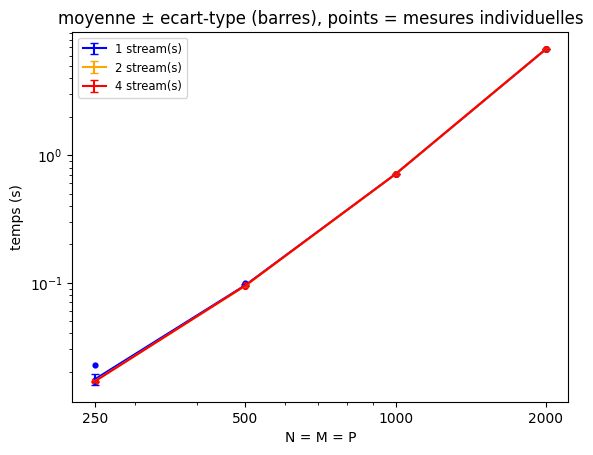

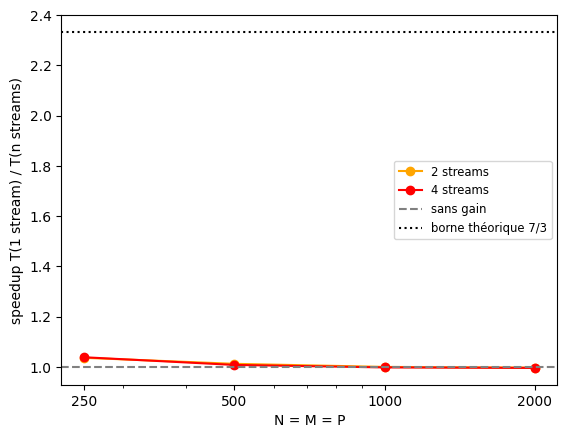

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import warnings
from matplotlib.ticker import NullFormatter
warnings.filterwarnings('ignore')

color_S = {1: "blue", 2: "orange", 4: "red"}


def figures_chaine():
    df4 = charger("partie4_chaine")
    for s, color in color_S.items():
        d = df4[df4['S'] == s]
        if d.empty:
            continue
        moy = d.groupby('N').mean(numeric_only=True).reset_index()
        ecart = d.groupby('N').std(numeric_only=True).reset_index()
        plt.errorbar(moy['N'], moy['runtime'], yerr=ecart['runtime'].values, capsize=3, color=color, label=f"{s} stream(s)")
        plt.scatter(d['N'], d['runtime'], color=color, s=12)
    plt.xscale('log')
    plt.yscale('log')
    plt.xticks(tailles_chaine, [str(n) for n in tailles_chaine])
    plt.gca().xaxis.set_minor_formatter(NullFormatter())
    plt.xlabel('N = M = P')
    plt.ylabel('temps (s)')
    plt.title('moyenne ± ecart-type (barres), points = mesures individuelles')
    plt.legend(fontsize='small')
    plt.show()

    moy = df4.groupby(['S', 'N']).mean(numeric_only=True).reset_index()
    for s, color in color_S.items():
        if s == 1:
            continue
        t1 = moy[moy['S'] == 1].set_index('N')['runtime']
        ts = moy[moy['S'] == s].set_index('N')['runtime']
        plt.plot(ts.index, t1.loc[ts.index] / ts, marker='o', color=color, label=f"{s} streams")
    plt.axhline(1.0, color='gray', linestyle='--', label='sans gain')
    plt.axhline(7 / 3, color='black', linestyle=':', label='borne théorique 7/3')
    plt.xscale('log')
    plt.xticks(tailles_chaine, [str(n) for n in tailles_chaine])
    plt.gca().xaxis.set_minor_formatter(NullFormatter())
    plt.xlabel('N = M = P')
    plt.ylabel('speedup T(1 stream) / T(n streams)')
    plt.legend(fontsize='small')
    plt.show()


figures_chaine()

### Question 4.4 - Discussion

**Temps de la chaîne de 7 produits en secondes, T = 32, 10 exécutions par configuration**

| N = M = P | 1 stream | 2 streams | 4 streams |
|---|---|---|---|
| 250 | 0.0175 ± 0.0017 | 0.01692 ± 0.00014 | 0.01688 ± 0.00017 |
| 500 | 0.0957 ± 0.0015 | 0.09452 ± 0.00049 | 0.09494 ± 0.00072 |
| 1000 | 0.7105 ± 0.0015 | 0.7107 ± 0.0013 | 0.7121 ± 0.0016 |
| 2000 | 6.770 ± 0.011 | 6.7906 ± 0.0054 | 6.7992 ± 0.0075 |

**Speedup T(1 stream) / T(n streams) et borne théorique 7/3 = 2.33**

| N = M = P | 2 streams | 4 streams |
|---|---|---|
| 250 | 1.036 | 1.038 |
| 500 | 1.012 | 1.008 |
| 1000 | 1.000 | 0.998 |
| 2000 | 0.997 | 0.996 |

Les streams n'apportent aucun gain mesurable. Le speedup avec 4 streams est de 1.038 à N = 250 (0.01753 s avec 1 stream contre 0.01688 s avec 4), puis de 1.008 à N = 500, de 0.998 à N = 1000 et de 0.996 à N = 2000, très loin de la borne théorique de 7/3 qu'on obtiendrait si les produits d'un même niveau s'exécutaient vraiment en parallèle. À N = 250, l'écart de 4 % est du même ordre que l'écart-type de la version à 1 stream (0.0017 s, soit 10 %), donc il n'est pas significatif. À N = 2000, la version à 4 streams est même 0.4 % plus lente (6.799 s contre 6.770 s), ce qui est à peine plus que les écarts-types.

Mon interprétation est que chaque produit occupe déjà toute la carte. Un produit lance N x M blocs de 32 threads, soit 62 500 blocs à N = 250 et 4 millions à N = 2000, alors que la carte ne peut en exécuter qu'environ 224 à la fois (14 multiprocesseurs, avec au plus 16 blocs résidents par multiprocesseur d'après les spécifications de cette architecture). Un seul kernel suffit donc à saturer le GPU, et un second kernel lancé dans un autre stream ne peut démarrer que quand des blocs du premier se terminent, c'est-à-dire en fin de kernel. On pourrait éventuellement vérifier ce point avec un outil de profilage, par exemple en observant la chronologie des kernels.

Dans le TP OpenMP, le speedup de l'enchaînement plafonnait autour de 2, avec la même borne de 7/3, parce que chaque produit était séquentiel sur un seul cœur : le parallélisme entre les produits d'un niveau était alors la seule source de parallélisme disponible. Ici, chaque produit est déjà très parallèle, et celui entre produits n'ajoute rien. Pour que les streams aident, il faudrait des produits qui n'occupent qu'une partie de la carte, par exemple avec peu de blocs, mais je ne l'ai pas testé.

Le temps de la chaîne est proche de 7 fois celui d'un produit isolé de la partie 3 (T = 32) : 0.0957 s contre 7 x 0.0132 = 0.0923 s à N = 500, 0.710 s contre 0.661 s à N = 1000 et 6.77 s contre 5.80 s à N = 2000. La chaîne est donc de 4 % à 17 % plus lente que sept produits isolés, et l'écart augmente avec N. Je n'ai pas d'explication vérifiée. Peut-être que la mémoire occupée (15 matrices, environ 480 Mo à N = 2000) rend la lecture des matrices moins efficace que dans la partie 3, mais je ne l'ai pas mesuré. Le débit de la chaîne reste de l'ordre de 12 à 20 GFlops selon la taille, comparable à celui d'un produit seul.